# Interpretable clustering of JSE Top 40 equities across three decision-date cross-sections

**Status: PILOT / exploratory.** This notebook implements the frozen research protocol
[`docs/research_protocol.md`](../docs/research_protocol.md) (**v1.2**, tag `protocol-v1.2`) on the **v1 reconstructed data**.
The v1 data are not point-in-time (protocol Section 2, "Known gap"), so every result here is a pilot result.
The same code will be rerun unchanged on the v2 point-in-time data.

Decision dates: 30 June 2025 (*t*₁, selection and preprocessing date), 31 December 2025, 30 June 2026.

1. **Setup and data checks**: load the 123 observations and confirm nothing was dropped.
2. **Exploratory data analysis (EDA)**: membership, missing data, sectors, distributions, correlations.
3. **Preprocessing**: MinMax scaling fitted on June 2025 only; the log-size variant used as a sensitivity.
4. **Optimisation**: the paper's nine combinations, then the full grid of dimension reductions × clustering methods × linkages × distance
   measures × k × seeds. The protocol's rule selects the method on June 2025 only. The later dates and a free-k diagnostic check it.
5. **Final models**: the selected method and the SACJ baseline at each date: maps, **dendrograms side by side over the years**, cluster profiles.
6. **Stability**: seed stability, and **perturbation stability** (100 subsamples of 37 of 41 firms per date).
7. **Shifts over time**: clusters matched by Jaccard + Hungarian assignment; matches, splits, merges, dissolutions; firms that **robustly moved** and firms that **stayed**.
8. **Signals**: S1 sector divergence, S2 multivariate outlier (individual Mahalanobis distance, with the SACJ Hotelling rule as a replication), S3 isolation.
9. **Anomaly-dynamics taxonomy**: emerging, persistent, resolving, transient … per signal.
10. **SHAP**: what separates the clusters, which attributes are **associated with** each mover's or signalled firm's change relative to June 2025,
    and what separates sector-divergent firms from their sector peers.
11. **Summary and run record.**

**How to run.** Open in VS Code (or Jupyter) with the project `.venv` kernel and choose *Run All*.
The optimisation grid takes about 5–6 minutes on 12 cores the first time. Its results are then saved and reused
unless the grid changes (`REUSE_SAVED_SEARCH` in Section 4.2).
Figures are saved to `reports/figures/` and tables to `reports/paper_tables/`.

**Departures from the SACJ paper.** Three dates instead of one; ten features (analyst ratings cannot be reconstructed historically, and earnings
yield replaces P/E because P/E is undefined for loss-making firms); historically correct index membership (41 instruments per date, including RNI
with imputed fundamentals); a documented model search; scores in both the 2-D map and the common 10-feature space; firm-level claims checked under data perturbation.

## 1. Setup and data checks

In [1]:
import os
for var in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS']:
    os.environ.setdefault(var, '1')          # single-threaded maths keeps results reproducible

import json, sys, time, warnings
from itertools import combinations, product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, adjusted_rand_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import MinMaxScaler

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'scripts'))
import analysis as A                         # tracked pipeline: features, scaler, models, settings
from validate_data import validate
%matplotlib inline

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*n_jobs value.*')
PROTOCOL = 'protocol-v1.2'                  # docs/research_protocol.md
DATES, FEATURES = A.DATES, A.FEATURES
SEED = 42                                    # headline seed, as in the archived runs
SEEDS = [42, 43, 44, 45, 46]                 # five seeds for stability checks
K = A.SPEC['hierarchical']['n_clusters']     # 8 at every date (protocol Section 6)
IMPUTED = {'RNI', 'AGL'}                     # imputation-sensitive firms

SHORT = {'return_1y': '1y return', 'average_daily_volume_1y_model': 'Avg volume',
         'market_cap_zar': 'Market cap', 'beta_1y': 'Beta', 'shares_outstanding': 'Shares out',
         'revenue_zar_model': 'Revenue', 'eps_zar_model': 'EPS', 'annualised_volatility_1y': 'Volatility',
         'dividend_yield': 'Div. yield', 'earnings_yield_model_clipped': 'Earnings yield'}
NAMES = [SHORT[f] for f in FEATURES]

FIG, TAB = ROOT / 'reports/figures', ROOT / 'reports/paper_tables'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False})

def save(fig, name):
    fig.savefig(FIG / f'{name}.png')

def table(frame, name, index=True):
    frame.to_csv(TAB / f'{name}.csv', index=index)
    return frame

`validate()` checks the modelling CSV against the source workbook and the documented method:
123 rows, 41 per date, 43 distinct tickers, RNI kept at every date, the two AGL volume
imputations, and imputation and clipping constants re-derived from June 2025. It stops with an error if anything is off.

In [2]:
validate()
data = pd.read_csv(ROOT / 'data/processed/Top40_Retrospective_Model_Inputs_v1.csv')
scaler, snaps = A.prepare(data)   # snaps[date]: the 41 firms at that date, sorted by ticker
print({d: len(s) for d, s in snaps.items()}, '| distinct tickers:', data.ticker.nunique())

PASS: 123 rows; 41 per date; 43 tickers; 3 RNI rows retained; 2 volume imputations; model features complete.
{'2025-06-30': 41, '2025-12-31': 41, '2026-06-30': 41} | distinct tickers: 43


## 2. Exploratory data analysis

### 2.1 Index membership over time

In [3]:
members = {d: set(snaps[d].ticker) for d in DATES}
info = data.drop_duplicates('ticker').set_index('ticker')[['company', 'sector_label']]
events = []
for before, after in zip(DATES, DATES[1:]):
    events += [dict(period=f'{before} → {after}', ticker=t, event='entry') for t in sorted(members[after] - members[before])]
    events += [dict(period=f'{before} → {after}', ticker=t, event='exit') for t in sorted(members[before] - members[after])]
events = table(pd.DataFrame(events).join(info, on='ticker'), 'membership_events', index=False)
always = set.intersection(*members.values())
print(f'{len(always)} firms are in the index at all three dates.')
events

39 firms are in the index at all three dates.


,period,ticker,event,company,sector_label
0,2025-06-30 → 2025-12-31,GLN,entry,GLENCORE XSTRATA PLC,Basic Materials
1,2025-06-30 → 2025-12-31,APN,exit,ASPEN PHARMACARE HLD,Health Care
2,2025-12-31 → 2026-06-30,PAN,entry,PAN AFRICAN RESOURCE PLC,Basic Materials
3,2025-12-31 → 2026-06-30,MNP,exit,MONDI PLC,Basic Materials


GLN's June 2025 exit and NPH's entry happened *before* the first snapshot, so they are not
between-snapshot events here. Entries and exits are treated separately in Section 7 and are never counted as "cluster changes".

### 2.2 Missing data and imputation
No firm is dropped. Where a raw value is unavailable, the raw column stays blank and a separate
model-only value (a June 2025 median) is used, with a flag.

In [4]:
flagged = data[data.volume_imputed | data.fundamentals_imputed]
table(flagged[['decision_date', 'ticker', 'company', 'volume_imputed', 'fundamentals_imputed',
               'revenue_zar_raw', 'revenue_zar_model', 'eps_zar_raw', 'eps_zar_model']],
      'imputed_observations', index=False)

,decision_date,ticker,company,volume_imputed,fundamentals_imputed,revenue_zar_raw,revenue_zar_model,eps_zar_raw,eps_zar_model
1,2025-06-30,AGL,ANGLO AMERICAN PLC,True,False,4.852847e+11,4.852847e+11,-44.989747,-44.989747
32,2025-06-30,RNI,REINET INVESTMENTS SCA,False,True,NaN,9.824454e+10,NaN,12.771500
42,2025-12-31,AGL,ANGLO AMERICAN PLC,True,False,4.515949e+11,4.515949e+11,-41.866440,-41.866440
73,2025-12-31,RNI,REINET INVESTMENTS SCA,False,True,NaN,9.824454e+10,NaN,12.771500
114,2026-06-30,RNI,REINET INVESTMENTS SCA,False,True,NaN,9.824454e+10,NaN,12.771500


Results for **RNI** (imputed revenue, EPS and earnings yield at all dates) and **AGL** (imputed volume) are flagged as *imputation-sensitive* wherever they are interpreted.

### 2.3 Sector composition

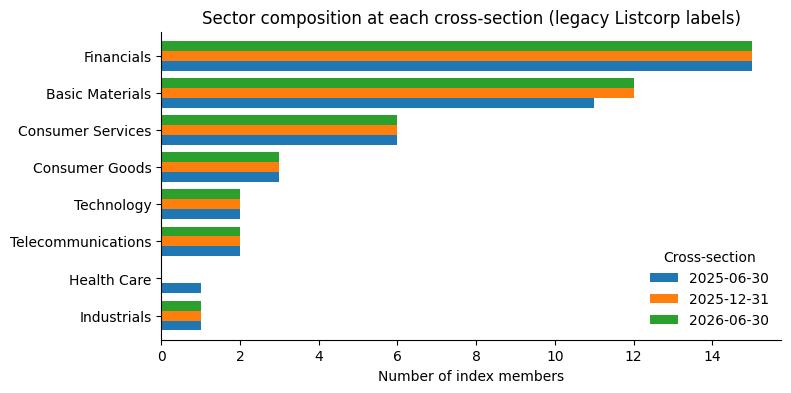

In [5]:
sector_counts = table(pd.crosstab(data.sector_label, data.decision_date), 'sector_counts')
fig, ax = plt.subplots(figsize=(8, 4))
sector_counts.sort_values(DATES[0]).plot.barh(ax=ax, width=0.8)
ax.set_xlabel('Number of index members'); ax.set_ylabel('')
ax.set_title('Sector composition at each cross-section (legacy Listcorp labels)')
ax.legend(title='Cross-section', frameon=False)
save(fig, 'eda_sector_composition'); plt.show()

Sector labels are **not** used to fit any model or to choose any setting. They are an **external comparator** used only afterwards.
The labels are legacy Listcorp categories, not verified historical classifications.

### 2.4 Descriptive statistics
Medians and skewness of the ten modelling features at each date (native units: ZAR, shares, ratios).

In [6]:
stats_rows = []
for d in DATES:
    s = snaps[d][FEATURES]
    stats_rows.append(pd.DataFrame({'date': d, 'feature': NAMES, 'median': s.median().values,
                                    'mean': s.mean().values, 'std': s.std().values,
                                    'min': s.min().values, 'max': s.max().values, 'skew': s.skew().values}))
describe = table(pd.concat(stats_rows), 'descriptive_statistics', index=False)
describe.pivot(index='feature', columns='date', values=['median', 'skew']).loc[NAMES]

median                                   skew  \
date              2025-06-30    2025-12-31    2026-06-30 2025-06-30   
feature                                                               
1y return       1.107605e-01  1.947077e-01  1.118476e-01  -0.000871   
Avg volume      1.534909e+06  1.572320e+06  1.629171e+06   2.277893   
Market cap      1.431642e+11  1.712493e+11  1.562087e+11   2.201627   
Beta            1.055951e+00  8.801319e-01  5.638668e-01   0.725528   
Shares out      8.294584e+08  8.919062e+08  8.850165e+08   1.677737   
Revenue         9.824454e+10  9.824454e+10  1.156970e+11   2.769304   
EPS             1.277150e+01  1.394900e+01  1.394900e+01   5.111764   
Volatility      2.613748e-01  2.743391e-01  2.446734e-01   1.253408   
Div. yield      2.635855e-02  2.929574e-02  3.815014e-02   0.531125   
Earnings yield  5.136140e-02  5.716446e-02  6.093721e-02  -4.092619   

                                      
date           2025-12-31 2026-06-30  
feature                               
1y return        1.884050   0.717907  
Avg volume       2.442079   2.225048  
Market cap       1.968104   2.338347  
Beta             0.983128   1.284794  
Shares out       3.253252   3.196204  
Revenue          5.355344   5.508909  
EPS              1.637890   1.340373  
Volatility       1.306200   1.247727  
Div. yield       0.361442   0.197429  
Earnings yield  -0.477587  -0.754653

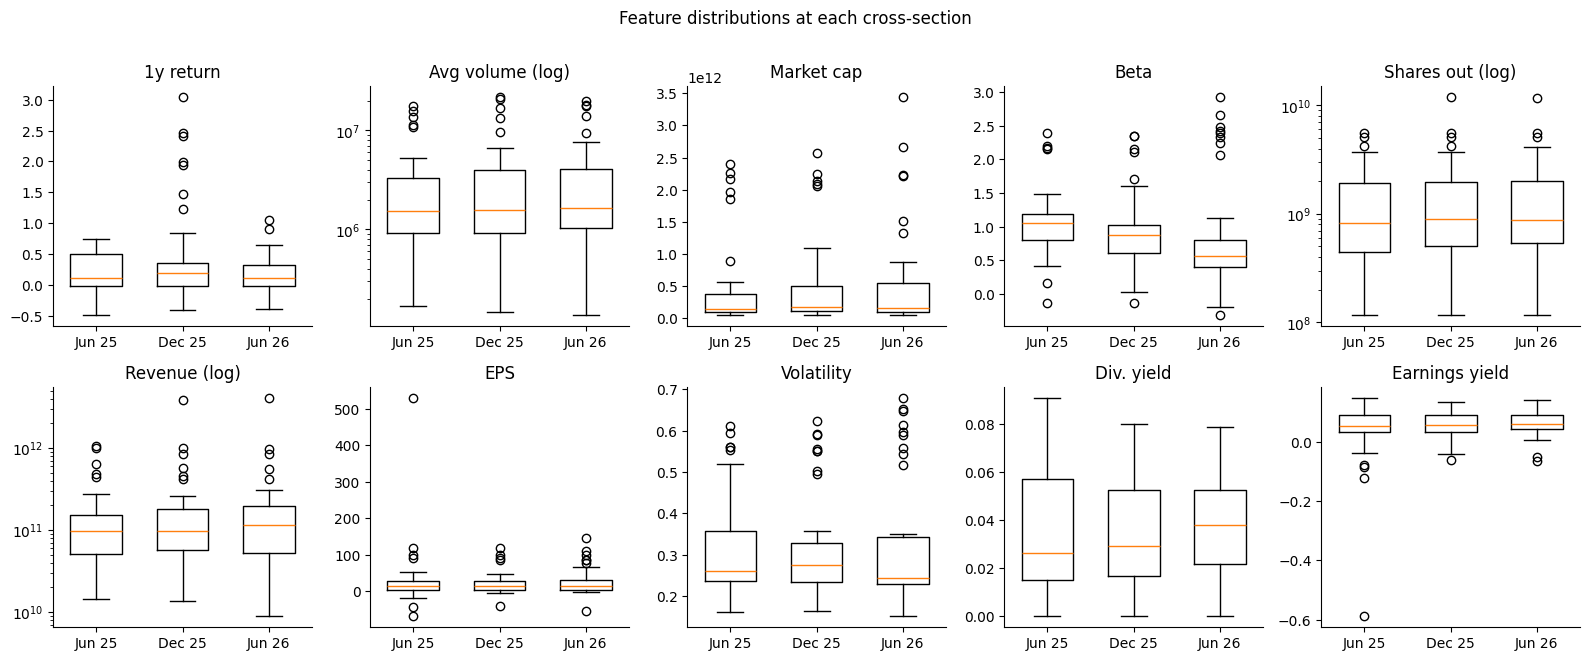

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for ax, feature, name in zip(axes.flat, FEATURES, NAMES):
    values = [snaps[d][feature] for d in DATES]
    ax.boxplot(values, tick_labels=['Jun 25', 'Dec 25', 'Jun 26'], widths=0.6)
    low, high = min(v.min() for v in values), max(v.max() for v in values)
    if low > 0 and high / low > 100:
        ax.set_yscale('log'); name += ' (log)'
    ax.set_title(name)
fig.suptitle('Feature distributions at each cross-section', y=1.01)
fig.tight_layout(); save(fig, 'eda_feature_distributions'); plt.show()

Size variables (market cap, shares, volume, revenue) are strongly right-skewed, so a few very large firms
carry much of the MinMax-scaled distance. The primary specification is kept, and a log-size variant (Section 3) is run as a sensitivity.

### 2.5 Correlations (June 2025, the preprocessing fit date)

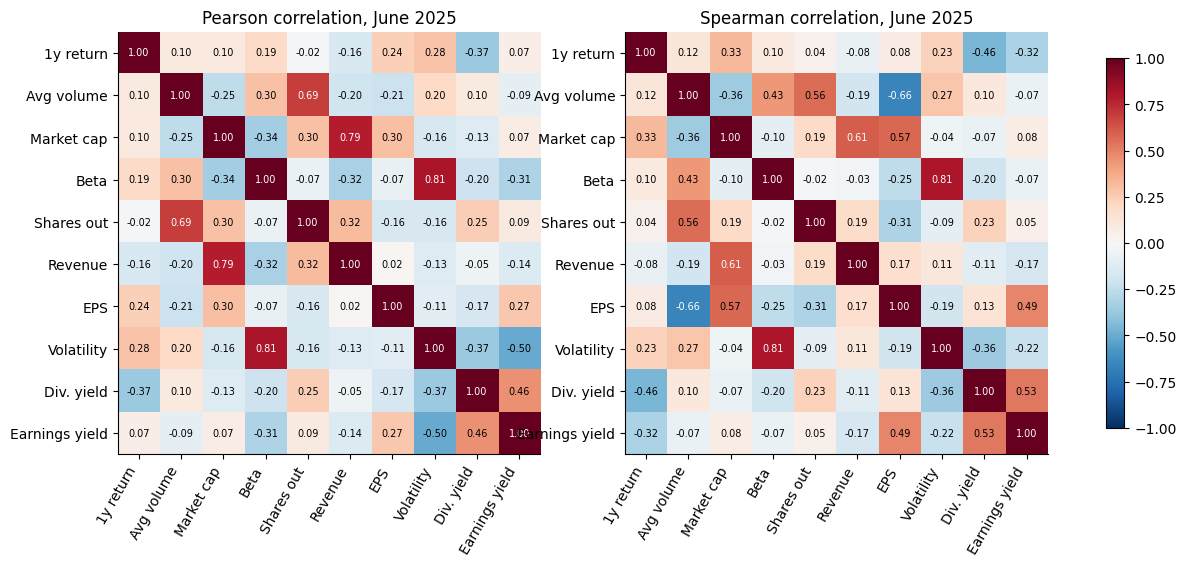

,feature_a,feature_b,pearson
27,Beta,Volatility,0.814852
19,Market cap,Revenue,0.786905


In [8]:
june = snaps[DATES[0]][FEATURES].set_axis(NAMES, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, method in zip(axes, ['pearson', 'spearman']):
    corr = june.corr(method=method)
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=60, ha='right'); ax.set_yticks(range(len(NAMES)), NAMES)
    for i, j in product(range(len(NAMES)), repeat=2):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
    ax.set_title(f'{method.title()} correlation, June 2025')
fig.colorbar(im, ax=axes, shrink=0.8); save(fig, 'eda_correlations'); plt.show()

pairs = [(NAMES[i], NAMES[j], june.corr().iloc[i, j]) for i, j in combinations(range(len(NAMES)), 2)]
high = pd.DataFrame(pairs, columns=['feature_a', 'feature_b', 'pearson']).query('abs(pearson) >= 0.7')
table(high.sort_values('pearson', key=abs, ascending=False), 'high_correlations', index=False)

Unlike the original sample, a few pairs are near or above 0.8 (for example beta with volatility, and market cap with revenue).
All ten features are kept so that the specification stays fixed. Correlated size and risk variables give those dimensions
extra weight, which should be stated in the paper.

## 3. Preprocessing
MinMax scaling is fitted **only on June 2025** and then applied unchanged to December 2025 and June 2026.
This avoids letting future information shape the scale. As a result, later values can fall outside [0, 1].

In [9]:
X = {d: scaler.transform(A.numeric_matrix(snaps[d])) for d in DATES}
outside = pd.DataFrame({d: ((X[d] < 0) | (X[d] > 1)).sum(axis=0) for d in DATES}, index=NAMES)
print('Scaled values outside [0, 1] per feature (expected to be 0 for June 2025):')
outside.T

Scaled values outside [0, 1] per feature (expected to be 0 for June 2025):


,1y return,Avg volume,Market cap,Beta,Shares out,Revenue,EPS,Volatility,Div. yield,Earnings yield
2025-06-30,0,0,0,0,0,0,0,1,0,0
2025-12-31,8,3,2,1,2,2,0,1,0,0
2026-06-30,2,3,4,6,1,3,0,5,0,0


**Log-size variant (sensitivity only, protocol Section 5).** log₁₀ of market cap, shares, average volume and revenue, applied before imputation:
values that were imputed, or are not positive, are set to missing and filled with the June 2025 median **of the logged values**, then MinMax is fitted on June 2025.

In [10]:
LOG_SIZE = {'market_cap_zar': None, 'shares_outstanding': None, 'average_daily_volume_1y_model': 'volume_imputed', 'revenue_zar_model': 'fundamentals_imputed'}

def log_matrix(frame, medians=None):
    out = frame[FEATURES].astype(float).copy()
    for f, flag in LOG_SIZE.items():
        v = out[f].where(out[f] > 0)
        if flag:
            v = v.where(~frame[flag].astype(bool))
        out[f] = np.log10(v)
    medians = out[list(LOG_SIZE)].median() if medians is None else medians
    return out.fillna(medians).to_numpy(), medians

x_log0, LOG_MEDIANS = log_matrix(snaps[DATES[0]])
assert np.isfinite(x_log0).all() and (np.ptp(x_log0, axis=0) > 0).all()     # protocol failure rule: no all-missing / constant feature
log_scaler = MinMaxScaler().fit(x_log0)
X_LOG = {d: log_scaler.transform(log_matrix(snaps[d], LOG_MEDIANS)[0]) for d in DATES}
print('Log-size medians used for filling (June 2025, log10 scale):', LOG_MEDIANS.round(3).to_dict())

Log-size medians used for filling (June 2025, log10 scale): {'market_cap_zar': 11.156, 'shares_outstanding': 8.919, 'average_daily_volume_1y_model': 6.186, 'revenue_zar_model': 10.992}


## 4. Optimisation: which dimension reduction and clustering method works best?

Two stages:

* **4.1 Replication.** The paper's nine combinations (Table 2), with their original default settings, at each date.
* **4.2–4.8 Full search.** Every combination of the settings below, at every date, with five seeds each. The best model is
  chosen **on June 2025 only**, using a rule written down before looking at the results (Section 4.5). December 2025 and June 2026 then
  test whether the choice holds on new data.

**How quality is measured.** Silhouette (higher is better) and Davies–Bouldin (DB, lower is better), each computed in two places:
* **in the embedding**, the space that was clustered, as in the paper. These scores are *not* comparable across methods:
  t-SNE and UMAP are designed to pull neighbours together, so they inflate their own scores;
* **in the common 10-feature space** (June-2025 MinMax units). This is the same space for every method, so it is the fair basis for choosing.

### 4.1 Replication: the paper's nine combinations

In [11]:
REPS9, ALGOS = ['pca', 'tsne', 'umap'], ['hierarchical', 'kmeans', 'dbscan']
embeddings, rows = {}, []
for d in DATES:
    for rep in REPS9:
        z = embeddings[d, rep] = A.embed(X[d], rep, SEED)
        for algo in ALGOS:
            y = A.cluster(z, algo, SEED, K)
            rows.append(dict(date=d, reduction=rep, clustering=algo, **A.scores(X[d], z, y, snaps[d].sector_label)))
comparison = pd.DataFrame(rows)
cols = ['n_clusters', 'coverage', 'silhouette_embedding', 'davies_bouldin_embedding', 'silhouette_features']
table(comparison[['date', 'reduction', 'clustering'] + cols + ['sector_ari', 'sector_nmi']], 'model_comparison', index=False)
comparison.pivot_table(index=['reduction', 'clustering'], columns='date',
                       values=['silhouette_embedding', 'davies_bouldin_embedding', 'silhouette_features']).round(3)

C:\Users\HP\Documents\GitHub\JSE-Top-40-Clustering\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


davies_bouldin_embedding                        \
date                                 2025-06-30 2025-12-31 2026-06-30   
reduction clustering                                                    
pca       dbscan                          0.431      0.348      0.310   
          hierarchical                    0.416      0.371      0.446   
          kmeans                          0.555      0.496      0.629   
tsne      dbscan                          0.662      0.532      0.484   
          hierarchical                    0.429      0.447      0.407   
          kmeans                          0.557      0.439      0.407   
umap      dbscan                          0.680      0.627      0.255   
          hierarchical                    0.689      0.548      0.613   
          kmeans                          0.697      0.642      0.613   

                       silhouette_embedding                        \
date                             2025-06-30 2025-12-31 2026-06-30   
reduction clustering                                                
pca       dbscan                      0.540      0.752      0.718   
          hierarchical                0.426      0.498      0.466   
          kmeans                      0.397      0.447      0.414   
tsne      dbscan                      0.338      0.505      0.507   
          hierarchical                0.571      0.598      0.641   
          kmeans                      0.529      0.618      0.641   
umap      dbscan                      0.287      0.433      0.759   
          hierarchical                0.406      0.501      0.542   
          kmeans                      0.421      0.523      0.543   

                       silhouette_features                        
date                            2025-06-30 2025-12-31 2026-06-30  
reduction clustering                                              
pca       dbscan                     0.393      0.556      0.427  
          hierarchical               0.177      0.285      0.279  
          kmeans                     0.072      0.151      0.093  
tsne      dbscan                     0.294      0.171      0.297  
          hierarchical               0.182      0.177      0.223  
          kmeans                     0.177      0.208      0.223  
umap      dbscan                     0.202      0.473      0.321  
          hierarchical               0.117      0.153      0.209  
          kmeans                     0.125      0.170      0.182

In [12]:
# Check: these numbers must match the archived tracked run (same code, data and seed).
archived = pd.read_csv(ROOT / 'experiments/runs/final-full-42/model_comparison.csv')
mine = comparison.assign(model=comparison.reduction + '_' + comparison.clustering)
check = mine.merge(archived, left_on=['date', 'model'], right_on=['decision_date', 'model'], suffixes=('', '_archived'))
for c in ['silhouette_embedding', 'silhouette_features', 'davies_bouldin_embedding']:
    np.testing.assert_allclose(check[c].astype(float), check[c + '_archived'].astype(float), rtol=1e-6, equal_nan=True)
print(f'Matches the archived run final-full-42 on all {len(check)} model/date rows.')

Matches the archived run final-full-42 on all 27 model/date rows.


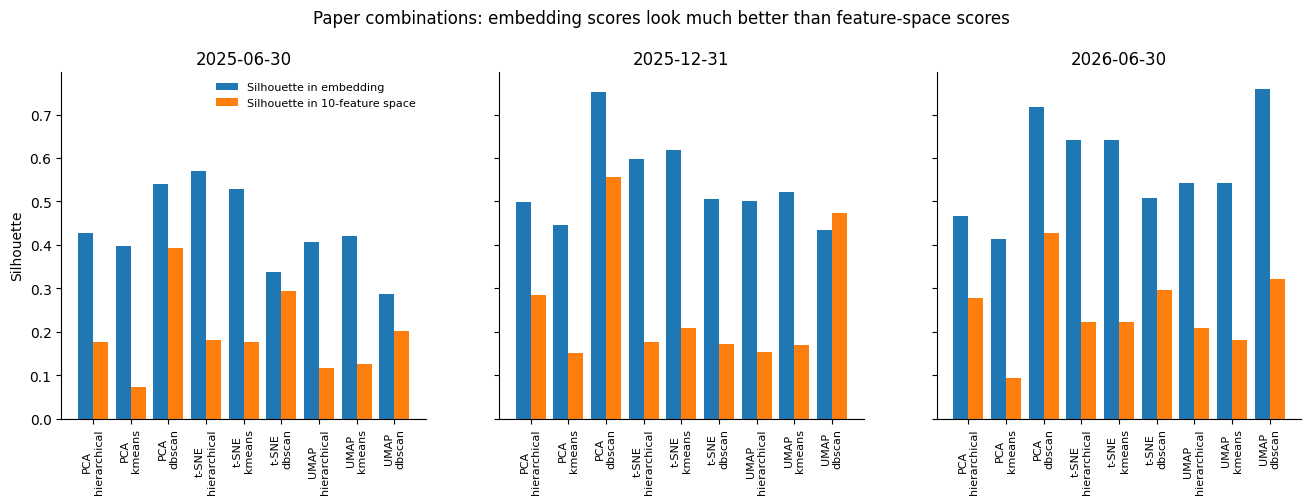

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
labels = [f'{r.upper() if r == "pca" else ("t-SNE" if r == "tsne" else "UMAP")}\n{a}' for r, a in product(REPS9, ALGOS)]
for ax, d in zip(axes, DATES):
    sub = comparison[comparison.date == d]
    pos = np.arange(len(sub))
    ax.bar(pos - 0.2, sub.silhouette_embedding, 0.4, label='Silhouette in embedding')
    ax.bar(pos + 0.2, sub.silhouette_features, 0.4, label='Silhouette in 10-feature space')
    ax.set_xticks(pos, labels, rotation=90, fontsize=8); ax.set_title(d); ax.axhline(0, color='grey', lw=0.8)
axes[0].set_ylabel('Silhouette'); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Paper combinations: embedding scores look much better than feature-space scores', y=1.02)
save(fig, 'model_comparison_silhouette'); plt.show()

**What to look for.** Embedding silhouettes (as in the paper) against feature-space silhouettes for the same partitions.
A large gap means the 2-D map makes groups look more separated than they are in the financial data,
which is why the full search below compares methods in the common space.

### 4.2 The search space
Everything in this grid is fitted at **each of the three dates** with **each of the five seeds**:

| Step | Options tested |
|---|---|
| Dimension reduction | **none** (cluster the 10 scaled features directly); **PCA** (2 components, or 95% of variance); **t-SNE** (perplexity 5/10/20 × learning rate 10/auto × 300/1000 iterations × Euclidean/Manhattan input distance); **UMAP** (3/5/10/20 neighbours × min_dist 0/0.1/0.5 × Euclidean/Manhattan input distance) |
| Hierarchical clustering | **linkage**: single, complete, average, Ward; **distance**: Euclidean, Manhattan (city-block), cosine (Ward needs Euclidean) |
| Other clustering | **K-Means** (20 starts); **DBSCAN** (eps 0.3/0.5/0.8/1.2 × min_samples 2/3/5, on standardised coordinates). DBSCAN picks its own number of clusters, so it cannot keep k = 8 unchanged at later dates: it is a **comparator only**, never eligible as the selected method |
| Number of clusters | k = 2 … 10 for hierarchical and K-Means |

The baseline (t-SNE perplexity 5, learning rate 10, 300 iterations, average linkage, Manhattan, k = 8) is one point in this grid.
Hierarchical clustering uses SciPy. The next section checks that it gives exactly the pipeline's (scikit-learn's) baseline result.

In [14]:
GRID = {
    'reductions': {
        'none': [{}],
        'pca': [{'n_components': 2}, {'n_components': 0.95}],
        'tsne': [dict(perplexity=p, learning_rate=lr, max_iter=it, metric=m)
                 for p, lr, it, m in product([5, 10, 20], [10, 'auto'], [300, 1000], ['euclidean', 'manhattan'])],
        'umap': [dict(n_neighbors=n, min_dist=md, metric=m)
                 for n, md, m in product([3, 5, 10, 20], [0.0, 0.1, 0.5], ['euclidean', 'manhattan'])]},
    'hierarchical': [['ward', 'euclidean']] + [[l, m] for l, m in product(['single', 'complete', 'average'],
                                                                           ['euclidean', 'cityblock', 'cosine'])],
    'k': list(range(2, 11)),
    'kmeans_n_init': 20,
    'dbscan': [[e, m] for e, m in product([0.3, 0.5, 0.8, 1.2], [2, 3, 5])],
    'seeds': SEEDS, 'dates': DATES}

REPS = [dict(reduction=name, **p) for name, settings in GRID['reductions'].items() for p in settings]
CLUSTERINGS = ([dict(clustering='hierarchical', linkage=l, distance=m, k=k) for l, m in GRID['hierarchical'] for k in GRID['k']]
               + [dict(clustering='kmeans', k=k) for k in GRID['k']]
               + [dict(clustering='dbscan', eps=e, min_samples=m, k=0) for e, m in GRID['dbscan']])   # k=0: chosen by DBSCAN
NICE = {'none': 'No reduction', 'pca': 'PCA', 'tsne': 't-SNE', 'umap': 'UMAP'}

def rep_label(rep):
    p = {k: v for k, v in rep.items() if k != 'reduction'}
    short = {'perplexity': 'perp', 'learning_rate': 'lr', 'max_iter': 'iter', 'metric': 'dist',
             'n_neighbors': 'nn', 'min_dist': 'min_dist', 'n_components': 'comp'}
    return NICE[rep['reduction']] + (' (' + ', '.join(f'{short[k]}={v}' for k, v in p.items()) + ')' if p else '')

def cl_label(cl):
    if cl['clustering'] == 'hierarchical':
        return f"hierarchical {cl['linkage']}/{cl['distance']}"
    return 'k-means' if cl['clustering'] == 'kmeans' else f"DBSCAN eps={cl['eps']}, min_samples={cl['min_samples']}"

def represent(x, rep, seed):
    # Dimension reduction (or none) with a given seed.
    p = {k: v for k, v in rep.items() if k != 'reduction'}
    if rep['reduction'] == 'none':
        return x
    if rep['reduction'] == 'pca':
        return PCA(svd_solver='full', **p).fit_transform(x)
    if rep['reduction'] == 'tsne':
        return TSNE(n_components=2, init='random', n_jobs=1, random_state=seed, **p).fit_transform(x)
    from umap import UMAP
    return UMAP(n_components=2, n_jobs=1, random_state=seed, **p).fit_transform(x)

def assign(z, cl, seed):
    # Cluster labels 0..k-1 (DBSCAN noise = -1).
    if cl['clustering'] == 'hierarchical':
        return fcluster(linkage(z, method=cl['linkage'], metric=cl['distance']), cl['k'], 'maxclust') - 1
    if cl['clustering'] == 'kmeans':
        return KMeans(cl['k'], n_init=GRID['kmeans_n_init'], random_state=seed).fit_predict(z)
    sd = z.std(axis=0)
    return DBSCAN(eps=cl['eps'], min_samples=cl['min_samples']).fit_predict((z - z.mean(axis=0)) / np.where(sd == 0, 1, sd))

def quality(x, z, y):
    keep = y != -1
    sizes = np.bincount(y[keep]) if keep.any() else np.array([], dtype=int)
    sizes = sizes[sizes > 0]
    valid = 1 < len(sizes) < keep.sum()
    out = dict(n_clusters=len(sizes), coverage=keep.mean(), singletons=int((sizes == 1).sum()),
               largest_share=sizes.max() / len(y) if len(sizes) else np.nan, valid=valid)
    for space, v in (('embedding', z), ('features', x)):
        out[f'silhouette_{space}'] = silhouette_score(v[keep], y[keep]) if valid else np.nan
        out[f'davies_bouldin_{space}'] = davies_bouldin_score(v[keep], y[keep]) if valid else np.nan
    return out

def search_task(x, d, r, rep):
    # One date x one representation: all clusterings, all seeds, plus pairwise seed ARI.
    rows, labels, z = [], {}, None
    for s in SEEDS:
        if z is None or rep['reduction'] in ('tsne', 'umap'):      # PCA / none do not depend on the seed
            z = represent(x, rep, s)
        for c, cl in enumerate(CLUSTERINGS):
            y = labels[c, s] = assign(z, cl, s)
            desc = {('embed_metric' if k == 'metric' else k): (str(v) if k == 'learning_rate' else v)
                    for k, v in rep.items()}
            rows.append(dict(date=d, rep_id=r, cl_id=c, seed=s, rep_label=rep_label(rep), cl_label=cl_label(cl),
                             **desc, **cl, **quality(x, z, y)))
    stab = []
    for c in range(len(CLUSTERINGS)):
        aris = [adjusted_rand_score(labels[c, a], labels[c, b]) for a, b in combinations(SEEDS, 2)]
        stab.append(dict(date=d, rep_id=r, cl_id=c, seed_ari_mean=np.mean(aris), seed_ari_min=np.min(aris)))
    return rows, stab

n_cl = len(CLUSTERINGS)
print(f'{len(REPS)} representations × {n_cl} clusterings = {len(REPS) * n_cl:,} model configurations per date')
print(f'× {len(SEEDS)} seeds × {len(DATES)} dates = {len(REPS) * n_cl * len(SEEDS) * len(DATES):,} fits')
pd.Series({NICE[k]: len(v) for k, v in GRID['reductions'].items()}, name='settings tested').to_frame().T

51 representations × 111 clusterings = 5,661 model configurations per date
× 5 seeds × 3 dates = 84,915 fits


,No reduction,PCA,t-SNE,UMAP
settings tested,1,2,24,24


In [15]:
REUSE_SAVED_SEARCH = True     # set to False to force a fresh search
FITS_FILE, STAB_FILE, GRID_FILE = TAB / 'optimisation_all_fits.csv.gz', TAB / 'optimisation_seed_ari.csv.gz', TAB / 'optimisation_grid.json'

same_grid = GRID_FILE.exists() and json.loads(GRID_FILE.read_text()) == json.loads(json.dumps(GRID))
if REUSE_SAVED_SEARCH and same_grid and FITS_FILE.exists() and STAB_FILE.exists():
    fits, stab = pd.read_csv(FITS_FILE), pd.read_csv(STAB_FILE)
    print(f'Reusing the saved search ({len(fits):,} fits). Set REUSE_SAVED_SEARCH = False to rerun it.')
else:
    start = time.time()
    out = Parallel(n_jobs=-1)(delayed(search_task)(X[d], d, r, rep) for d in DATES for r, rep in enumerate(REPS))
    fits = pd.DataFrame([row for rows, _ in out for row in rows])
    stab = pd.DataFrame([row for _, st in out for row in st])
    fits.to_csv(FITS_FILE, index=False); stab.to_csv(STAB_FILE, index=False)
    GRID_FILE.write_text(json.dumps(GRID, indent=1))
    print(f'Search finished: {len(fits):,} fits in {(time.time() - start) / 60:.1f} minutes.')

# Check: the grid's version of the baseline reproduces the pipeline exactly (seed 42, all dates).
BASELINE_REP = dict(reduction='tsne', perplexity=5, learning_rate=10, max_iter=300, metric='euclidean')
BASELINE_CL = dict(clustering='hierarchical', linkage='average', distance='cityblock', k=K)
b = fits[(fits.rep_label == rep_label(BASELINE_REP)) & (fits.cl_label == cl_label(BASELINE_CL)) & (fits.k == K) & (fits.seed == SEED)]
ref = comparison.query('reduction == "tsne" and clustering == "hierarchical"').set_index('date')
np.testing.assert_allclose(b.set_index('date').loc[DATES, 'silhouette_embedding'], ref.loc[DATES, 'silhouette_embedding'], rtol=1e-6)
print('The baseline inside the grid matches the pipeline at all three dates.')

Reusing the saved search (84,915 fits). Set REUSE_SAVED_SEARCH = False to rerun it.
The baseline inside the grid matches the pipeline at all three dates.


In [16]:
# One row per configuration and date: averages over the five seeds, plus seed stability.
keys = ['date', 'rep_id', 'cl_id']
desc_cols = ['rep_label', 'cl_label', 'reduction', 'clustering', 'linkage', 'distance', 'k', 'eps', 'min_samples',
             'perplexity', 'learning_rate', 'max_iter', 'embed_metric', 'n_neighbors', 'min_dist', 'n_components']
summary = (fits.groupby(keys)
           .agg(all_seeds_valid=('valid', 'all'), coverage_min=('coverage', 'min'), n_clusters=('n_clusters', 'median'),
                singletons_max=('singletons', 'max'), largest_share_max=('largest_share', 'max'),
                silhouette_features=('silhouette_features', 'mean'), silhouette_features_sd=('silhouette_features', 'std'),
                davies_bouldin_features=('davies_bouldin_features', 'mean'),
                silhouette_embedding=('silhouette_embedding', 'mean'), davies_bouldin_embedding=('davies_bouldin_embedding', 'mean'))
           .reset_index().merge(stab, on=keys).merge(fits.drop_duplicates(keys)[keys + desc_cols], on=keys))
summary['family'] = np.where(summary.clustering == 'hierarchical', summary.linkage + '/' + summary.distance, summary.clustering)
table(summary, 'optimisation_summary', index=False)
june_all = summary[summary.date == DATES[0]]
print(f'{len(june_all):,} configurations per date; {int(june_all.all_seeds_valid.sum()):,} give a valid partition on all five seeds in June 2025.')

5,661 configurations per date; 5,307 give a valid partition on all five seeds in June 2025.


### 4.3 Dimension reduction × clustering method × linkage × distance (June 2025, k = 8)
Each cell shows the **best** score that combination reaches over its reduction settings (perplexity, neighbours and so on), averaged over five seeds.
The top panel uses the common feature space, the fair comparison. The bottom panel uses the embedding, as in the paper.

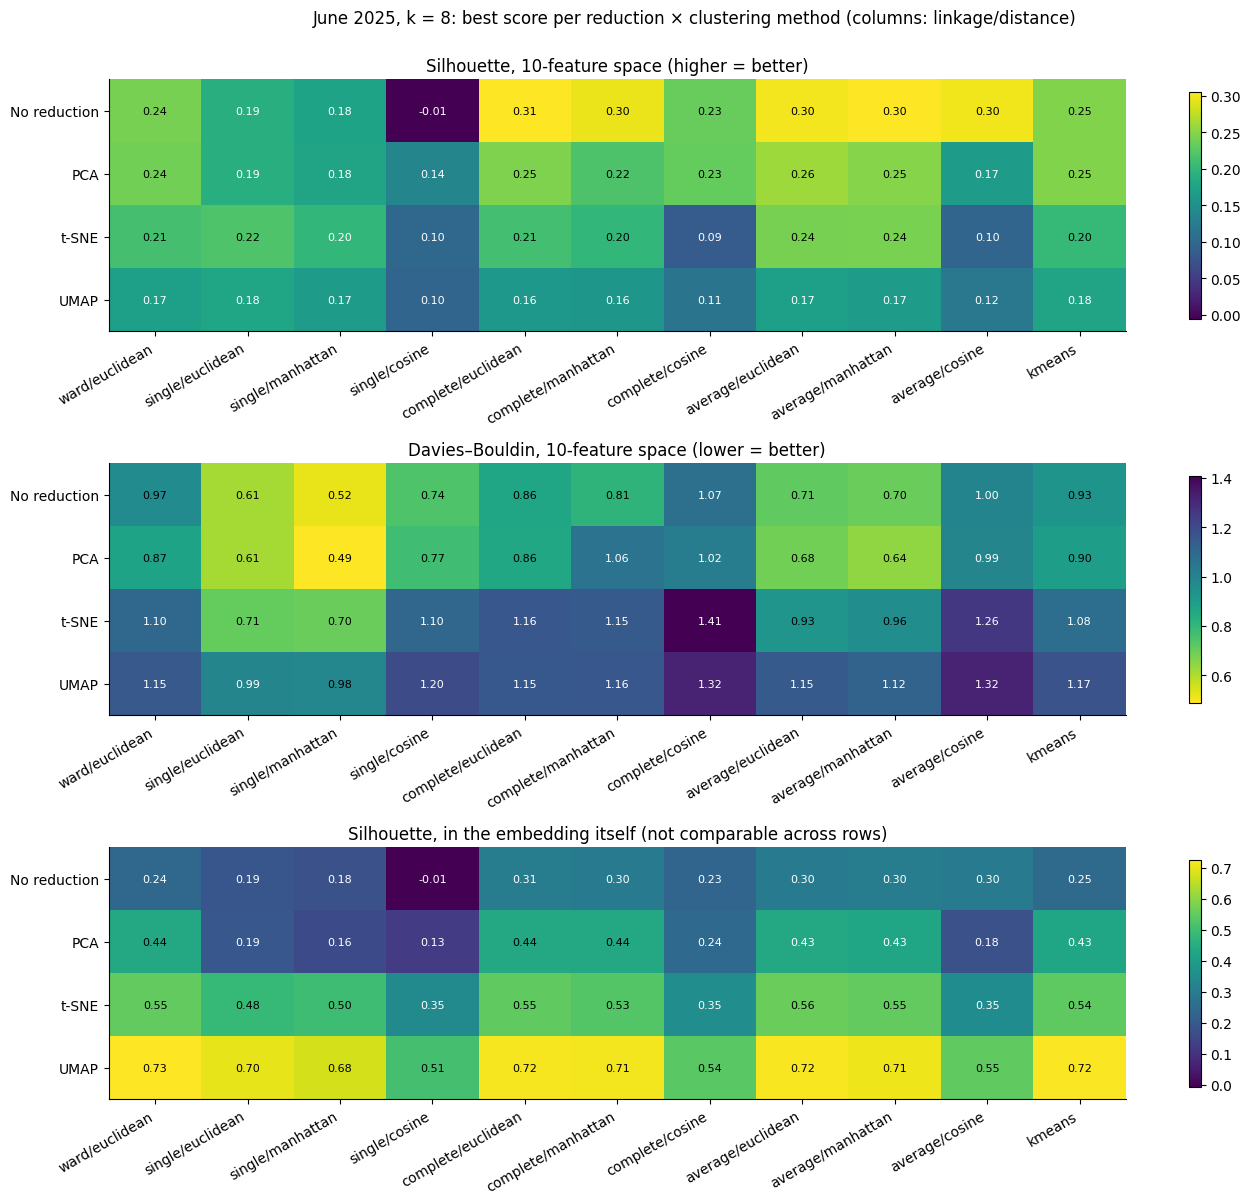

family,ward/euclidean,single/euclidean,single/cityblock,single/cosine,complete/euclidean,complete/cityblock,complete/cosine,average/euclidean,average/cityblock,average/cosine,kmeans
reduction,,,,,,,,,,,
none,0.242,0.190,0.175,-0.005,0.305,0.296,0.233,0.300,0.304,0.298,0.246
pca,0.239,0.190,0.177,0.136,0.245,0.219,0.231,0.259,0.248,0.167,0.246
tsne,0.214,0.219,0.200,0.100,0.212,0.200,0.086,0.241,0.242,0.096,0.203
umap,0.171,0.177,0.166,0.096,0.160,0.160,0.115,0.170,0.166,0.119,0.176


In [17]:
j8 = june_all[(june_all.k == K) & june_all.all_seeds_valid]
fam_order = ['ward/euclidean'] + [f'{l}/{m}' for l, m in product(['single', 'complete', 'average'], ['euclidean', 'cityblock', 'cosine'])] + ['kmeans']
red_order = ['none', 'pca', 'tsne', 'umap']
panels = [('silhouette_features', 'max', 'Silhouette, 10-feature space (higher = better)', 'viridis'),
          ('davies_bouldin_features', 'min', 'Davies–Bouldin, 10-feature space (lower = better)', 'viridis_r'),
          ('silhouette_embedding', 'max', 'Silhouette, in the embedding itself (not comparable across rows)', 'viridis')]
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for ax, (metric, how, title, cmap) in zip(axes, panels):
    grid = j8.pivot_table(index='reduction', columns='family', values=metric, aggfunc=how).reindex(index=red_order, columns=fam_order)
    im = ax.imshow(grid, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(fam_order)), [f.replace('cityblock', 'manhattan') for f in fam_order], rotation=30, ha='right')
    ax.set_yticks(range(len(red_order)), [NICE[r] for r in red_order]); ax.set_title(title)
    for i, jx in product(range(grid.shape[0]), range(grid.shape[1])):
        v = grid.iloc[i, jx]
        if pd.notna(v):
            ax.text(jx, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if metric.startswith('silhouette') == (v < grid.stack().median()) else 'black')
    fig.colorbar(im, ax=ax, shrink=0.9)
fig.suptitle('June 2025, k = 8: best score per reduction × clustering method (columns: linkage/distance)', y=1.0)
fig.tight_layout(); save(fig, 'optimisation_method_heatmaps'); plt.show()
table(j8.pivot_table(index='reduction', columns='family', values='silhouette_features', aggfunc='max').reindex(index=red_order, columns=fam_order),
      'optimisation_best_silhouette_by_method').round(3)

**What to look for.**
* **Distance and linkage**: columns show how the result changes with linkage and distance for the same reduction.
* **Dimension reduction**: rows compare clustering the 10 features directly, PCA, t-SNE and UMAP on the same footing (top two panels),
  against each method's own embedding score (bottom panel, not comparable across rows).
* Raw scores also reward degenerate partitions (one big group plus several one-firm "clusters"). The rule in Section 4.5 excludes these.

### 4.4 Effect of the t-SNE and UMAP settings, and of k

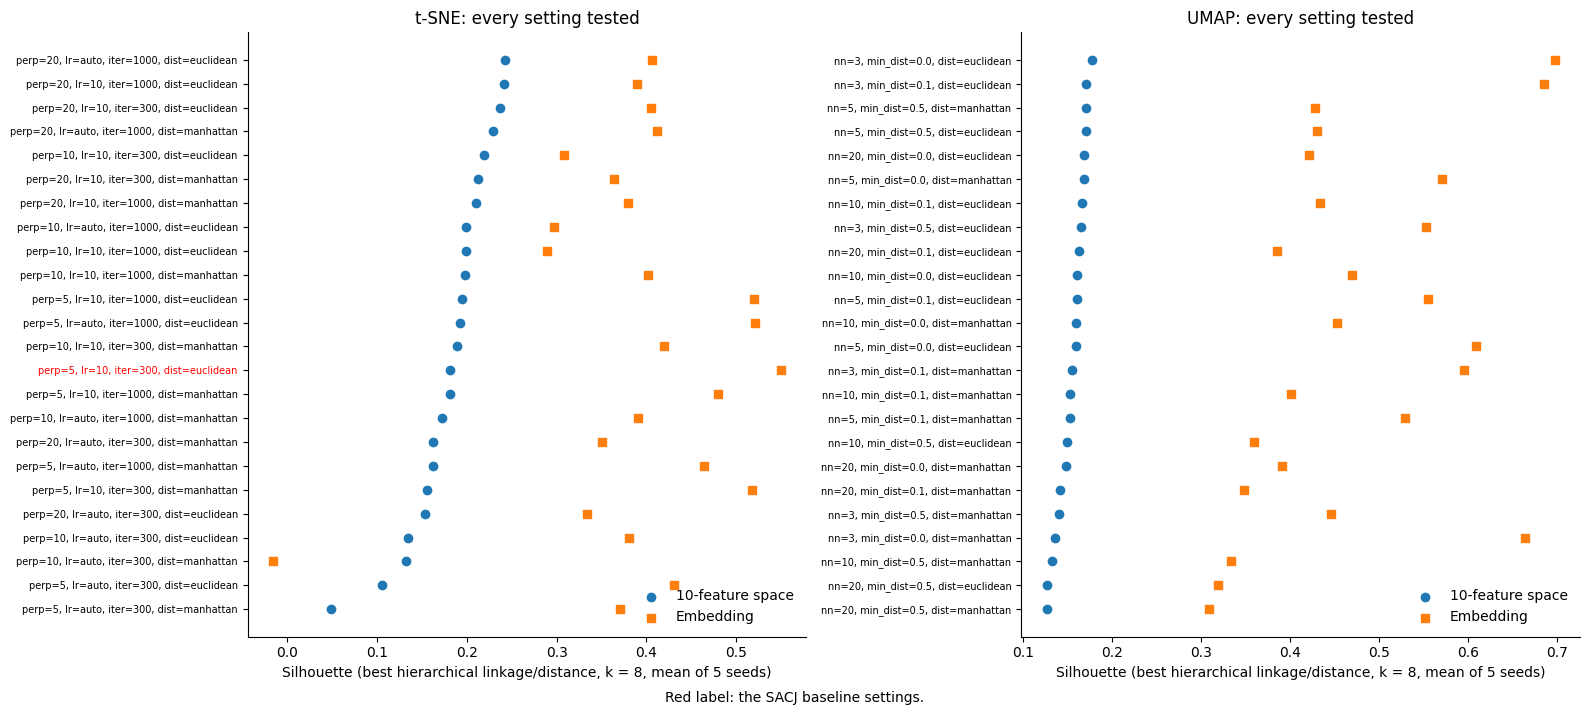

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, red in zip(axes, ['tsne', 'umap']):
    s = (j8[(j8.reduction == red) & (j8.clustering == 'hierarchical')]
         .sort_values('silhouette_features').groupby('rep_label').tail(1).sort_values('silhouette_features'))
    pos = np.arange(len(s))
    ax.scatter(s.silhouette_features, pos, label='10-feature space', color='tab:blue')
    ax.scatter(s.silhouette_embedding, pos, label='Embedding', color='tab:orange', marker='s')
    ax.set_yticks(pos, [l.split('(')[1].rstrip(')') for l in s.rep_label], fontsize=7)
    ax.set_xlabel('Silhouette (best hierarchical linkage/distance, k = 8, mean of 5 seeds)')
    ax.set_title(f'{NICE[red]}: every setting tested'); ax.legend(frameon=False, loc='lower right')
    is_base = s.rep_label == rep_label(BASELINE_REP)
    if is_base.any():
        ax.get_yticklabels()[int(np.flatnonzero(is_base)[0])].set_color('red')
fig.text(0.5, -0.01, 'Red label: the SACJ baseline settings.', ha='center')
fig.tight_layout(); save(fig, 'optimisation_embedding_settings'); plt.show()

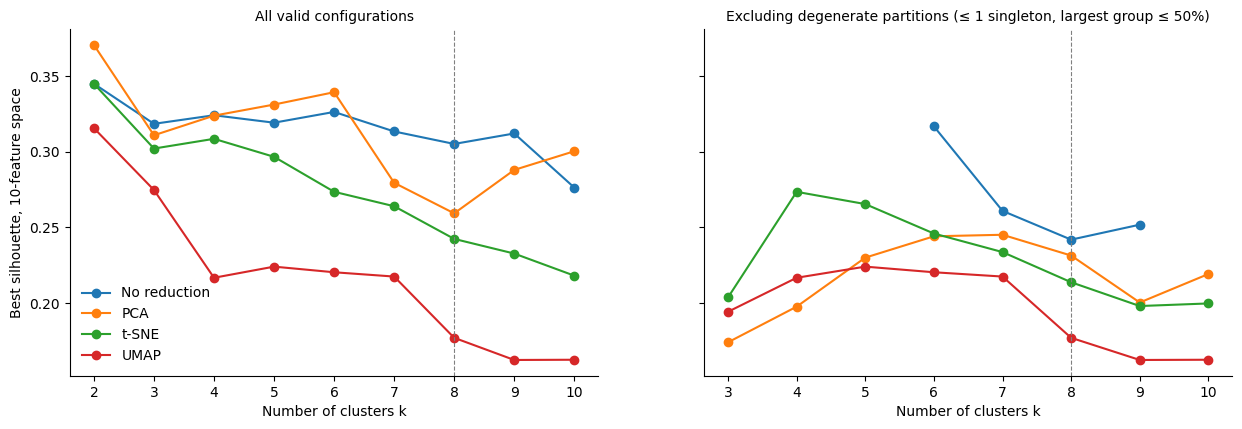

In [19]:
valid_june = june_all[june_all.all_seeds_valid & (june_all.clustering != 'dbscan')]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
useful = (valid_june.singletons_max <= 1) & (valid_june.largest_share_max <= 0.5)
for ax, (subset, title) in zip(axes, [(valid_june, 'All valid configurations'),
                                      (valid_june[useful], 'Excluding degenerate partitions (≤ 1 singleton, largest group ≤ 50%)')]):
    for red in red_order:
        best = subset[subset.reduction == red].groupby('k').silhouette_features.max()
        ax.plot(best.index, best.values, marker='o', label=NICE[red])
    ax.axvline(K, color='grey', ls='--', lw=0.8); ax.set_xlabel('Number of clusters k'); ax.set_title(title, fontsize=10)
axes[0].set_ylabel('Best silhouette, 10-feature space'); axes[0].legend(frameon=False)
save(fig, 'optimisation_k_curves'); plt.show()

Left: all valid configurations, where small k can win simply by splitting off an extreme firm. Right: degenerate partitions excluded.
k = 8 is fixed by the protocol at every date (shifts are read against the eight-sector comparator). Free k is a diagnostic only (Section 4.6).

### 4.5 The selection rule (protocol Section 6)
Applied to **June 2025 only**, among k = 8 configurations (DBSCAN is a comparator and never eligible). All rules must hold **on every one of the five seeds**:

1. the fit succeeds and gives a valid partition;
2. at least 95% of firms assigned (non-noise);
3. mean pairwise seed ARI ≥ 0.80;
4. at most one singleton cluster;
5. no cluster holds more than 50% of all firms at the date.

**Rank**: feature-space silhouette rank + DB rank; lowest sum wins. Ties: higher seed ARI, then higher silhouette, then grid order.
If nothing is eligible, rules 4–5 are dropped and the result is flagged as a deviation.
Rules 4–5 exist because isolating outliers is the job of S2 (Section 8). Sector labels play no part in the selection.

In [20]:
RULE = dict(min_coverage=0.95, min_seed_ari=0.80, max_singletons=1, max_largest_share=0.50)

def eligible(df, rule=RULE):
    return df[df.all_seeds_valid & (df.coverage_min >= rule['min_coverage']) & (df.seed_ari_mean >= rule['min_seed_ari'])
              & (df.singletons_max <= rule['max_singletons']) & (df.largest_share_max <= rule['max_largest_share'])]

def ranked(df, space='features'):
    df = df.assign(joint_rank=df[f'silhouette_{space}'].rank(ascending=False) + df[f'davies_bouldin_{space}'].rank())
    return df.sort_values(['joint_rank', 'seed_ari_mean', f'silhouette_{space}', 'rep_id', 'cl_id'],
                          ascending=[True, False, False, True, True])

show = ['rep_label', 'cl_label', 'k', 'n_clusters', 'silhouette_features', 'davies_bouldin_features',
        'silhouette_embedding', 'davies_bouldin_embedding', 'seed_ari_mean', 'singletons_max', 'largest_share_max', 'joint_rank']
candidates = june_all[(june_all.k == K) & (june_all.clustering != 'dbscan')]
top8 = ranked(eligible(candidates))
SELECTION_DEVIATION = top8.empty
if SELECTION_DEVIATION:                       # protocol fallback: drop rules 4-5, flag the deviation
    top8 = ranked(eligible(candidates, dict(RULE, max_singletons=len(X[DATES[0]]), max_largest_share=1.0)))
    print('DEVIATION: no configuration passed all rules; rules 4-5 dropped.')
print(f'{len(top8)} of {len(candidates)} k = 8 configurations pass the rule. Top 10:')
with pd.option_context('display.max_colwidth', 70):
    display(table(top8.head(10)[show], 'optimisation_top10_k8', index=False).round(3))

70 of 561 k = 8 configurations pass the rule. Top 10:


,rep_label,cl_label,k,n_clusters,silhouette_features,davies_bouldin_features,silhouette_embedding,davies_bouldin_embedding,seed_ari_mean,singletons_max,largest_share_max,joint_rank
6,No reduction,hierarchical ward/euclidean,8,8.0,0.242,0.966,0.242,0.966,1.000,1,0.293,2.0
60,No reduction,hierarchical complete/cosine,8,8.0,0.233,1.068,0.233,1.068,1.000,1,0.268,6.0
282,PCA (comp=0.95),hierarchical complete/cosine,8,8.0,0.231,1.018,0.245,0.980,1.000,1,0.268,6.0
1077,"t-SNE (perp=5, lr=auto, iter=1000, dist=euclidean)",hierarchical average/cityblock,8,8.0,0.189,1.132,0.528,0.516,0.828,0,0.220,15.0
1449,"t-SNE (perp=10, lr=10, iter=1000, dist=euclidean)",hierarchical ward/euclidean,8,8.0,0.189,1.142,0.460,0.627,0.828,0,0.195,17.0
633,"t-SNE (perp=5, lr=10, iter=1000, dist=euclidean)",hierarchical average/cityblock,8,8.0,0.188,1.132,0.532,0.499,0.887,0,0.195,19.0
624,"t-SNE (perp=5, lr=10, iter=1000, dist=euclidean)",hierarchical average/euclidean,8,8.0,0.188,1.143,0.532,0.511,0.874,0,0.195,20.0
1512,"t-SNE (perp=10, lr=10, iter=1000, dist=euclidean)",hierarchical average/euclidean,8,8.0,0.179,1.113,0.459,0.613,0.814,0,0.195,21.0
1068,"t-SNE (perp=5, lr=auto, iter=1000, dist=euclidean)",hierarchical average/euclidean,8,8.0,0.192,1.152,0.521,0.520,0.916,0,0.195,23.0
309,PCA (comp=0.95),hierarchical average/cosine,8,8.0,0.167,0.988,0.175,0.958,1.000,1,0.244,26.0


In [21]:
# Best configuration of each reduction × clustering family (k = 8, same rule): "which technique works best".
best_family = (top8.assign(method=top8.reduction.map(NICE) + ' + ' + np.where(top8.clustering == 'hierarchical', 'hierarchical', 'k-means'))
               .groupby('method').head(1))
with pd.option_context('display.max_colwidth', 70):
    display(table(best_family[['method'] + show], 'optimisation_best_per_family', index=False).round(3))

,method,rep_label,cl_label,k,n_clusters,silhouette_features,davies_bouldin_features,silhouette_embedding,davies_bouldin_embedding,seed_ari_mean,singletons_max,largest_share_max,joint_rank
6,No reduction + hierarchical,No reduction,hierarchical ward/euclidean,8,8.0,0.242,0.966,0.242,0.966,1.000,1,0.293,2.0
282,PCA + hierarchical,PCA (comp=0.95),hierarchical complete/cosine,8,8.0,0.231,1.018,0.245,0.980,1.000,1,0.268,6.0
1077,t-SNE + hierarchical,"t-SNE (perp=5, lr=auto, iter=1000, dist=euclidean)",hierarchical average/cityblock,8,8.0,0.189,1.132,0.528,0.516,0.828,0,0.220,15.0
3225,UMAP + hierarchical,"UMAP (nn=3, min_dist=0.1, dist=euclidean)",hierarchical ward/euclidean,8,8.0,0.171,1.151,0.685,0.363,0.830,0,0.220,36.0
1539,t-SNE + k-means,"t-SNE (perp=10, lr=10, iter=1000, dist=euclidean)",k-means,8,8.0,0.178,1.168,0.465,0.647,0.811,0,0.195,41.0
3981,UMAP + k-means,"UMAP (nn=5, min_dist=0.1, dist=euclidean)",k-means,8,8.0,0.162,1.174,0.554,0.557,0.845,0,0.195,56.0
207,PCA + k-means,PCA (comp=2),k-means,8,8.0,0.114,1.657,0.427,0.630,0.859,1,0.341,129.0


In [22]:
def find(rep, cl, date=DATES[0]):
    return summary[(summary.rep_label == rep_label(rep)) & (summary.cl_label == cl_label(cl)) & (summary.k == cl['k']) & (summary.date == date)].iloc[0]

choices = {
    'Baseline (SACJ)': find(BASELINE_REP, BASELINE_CL),
    'Tuned, k = 8 (main)': top8.iloc[0],
    'Tuned, free k': ranked(eligible(june_all[june_all.clustering != 'dbscan'])).iloc[0],
    'Best 2-D map, k = 8 (feature-space rule)': ranked(eligible(june_all[(june_all.k == K) & june_all.reduction.isin(['tsne', 'umap'])])).iloc[0],
    'Best 2-D map, k = 8 (embedding-score rule, paper style)': ranked(eligible(june_all[(june_all.k == K) & june_all.reduction.isin(['tsne', 'umap'])]), 'embedding').iloc[0],
}
selected = pd.DataFrame(choices).T[show[:-1]]
with pd.option_context('display.max_colwidth', 70):
    display(table(selected, 'optimisation_selected_models').round(3))

,rep_label,cl_label,k,n_clusters,silhouette_features,davies_bouldin_features,silhouette_embedding,davies_bouldin_embedding,seed_ari_mean,singletons_max,largest_share_max
Baseline (SACJ),"t-SNE (perp=5, lr=10, iter=300, dist=euclidean)",hierarchical average/cityblock,8,8.0,0.166405,1.177657,0.550108,0.504607,0.72743,0,0.195122
"Tuned, k = 8 (main)",No reduction,hierarchical ward/euclidean,8,8.0,0.241855,0.966126,0.241855,0.966126,1.0,1,0.292683
"Tuned, free k",No reduction,hierarchical complete/cityblock,6,6.0,0.316739,0.952164,0.316739,0.952164,1.0,1,0.487805
"Best 2-D map, k = 8 (feature-space rule)","t-SNE (perp=5, lr=auto, iter=1000, dist=euclidean)",hierarchical average/cityblock,8,8.0,0.189337,1.132059,0.527561,0.515733,0.827875,0,0.219512
"Best 2-D map, k = 8 (embedding-score rule, paper style)","UMAP (nn=3, min_dist=0.0, dist=euclidean)",hierarchical ward/euclidean,8,8.0,0.165593,1.202384,0.725133,0.331247,0.85336,0,0.219512


In [23]:
# Does the winner depend on the exact thresholds? Re-run the k = 8 selection under alternative rules.
rows = []
for sing, big, ari in product([0, 1, 2], [0.4, 0.5, 0.6], [0.7, 0.8, 0.9]):
    pool = ranked(eligible(candidates, dict(min_coverage=0.95, min_seed_ari=ari, max_singletons=sing, max_largest_share=big)))
    w = pool.iloc[0] if len(pool) else None
    rows.append(dict(max_singletons=sing, max_largest_share=big, min_seed_ari=ari, eligible=len(pool),
                     winner='—' if w is None else f'{w.rep_label} + {w.cl_label}'))
rule_sensitivity = table(pd.DataFrame(rows), 'optimisation_rule_sensitivity', index=False)
print('How often each model wins across the 27 rule variants:')
rule_sensitivity.winner.value_counts().to_frame('rule variants won')

How often each model wins across the 27 rule variants:


,rule variants won
winner,
No reduction + hierarchical ward/euclidean,11
"t-SNE (perp=5, lr=auto, iter=1000, dist=euclidean) + hierarchical average/cityblock",6
"t-SNE (perp=5, lr=auto, iter=1000, dist=euclidean) + hierarchical average/euclidean",3
PCA (comp=0.95) + hierarchical complete/euclidean,3
No reduction + hierarchical complete/euclidean,3
PCA (comp=0.95) + k-means,1


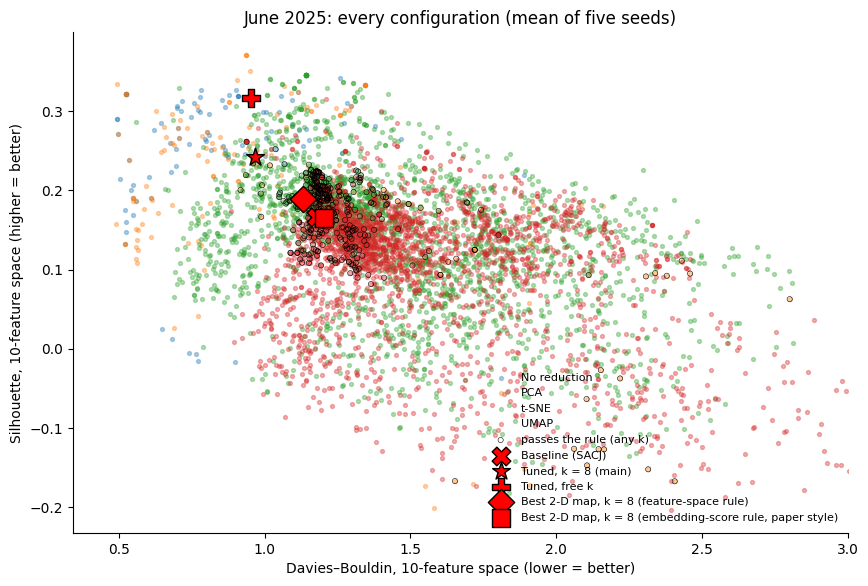

In [24]:
fig, ax = plt.subplots(figsize=(10, 6.5))
pool = june_all[june_all.all_seeds_valid & (june_all.coverage_min >= 0.95)]
for red in red_order:
    s = pool[pool.reduction == red]
    ax.scatter(s.davies_bouldin_features, s.silhouette_features, s=8, alpha=0.35, label=NICE[red])
el = eligible(pool)
ax.scatter(el.davies_bouldin_features, el.silhouette_features, s=14, facecolors='none', edgecolors='black', lw=0.4, label='passes the rule (any k)')
for (name, row), marker in zip(choices.items(), ['X', '*', 'P', 'D', 's']):
    ax.scatter(row.davies_bouldin_features, row.silhouette_features, s=180, marker=marker, color='red', edgecolors='black', label=name, zorder=5)
ax.set_xlabel('Davies–Bouldin, 10-feature space (lower = better)'); ax.set_ylabel('Silhouette, 10-feature space (higher = better)')
ax.set_title('June 2025: every configuration (mean of five seeds)'); ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_xlim(right=min(3, pool.davies_bouldin_features.max())); save(fig, 'optimisation_tradeoff'); plt.show()

### 4.6 Does the choice hold on the later dates?
The selected settings are refitted on December 2025 and June 2026 with no further tuning. "Percentile" is the model's position among all valid
k = 8 configurations at that date by feature-space silhouette (100 = best).

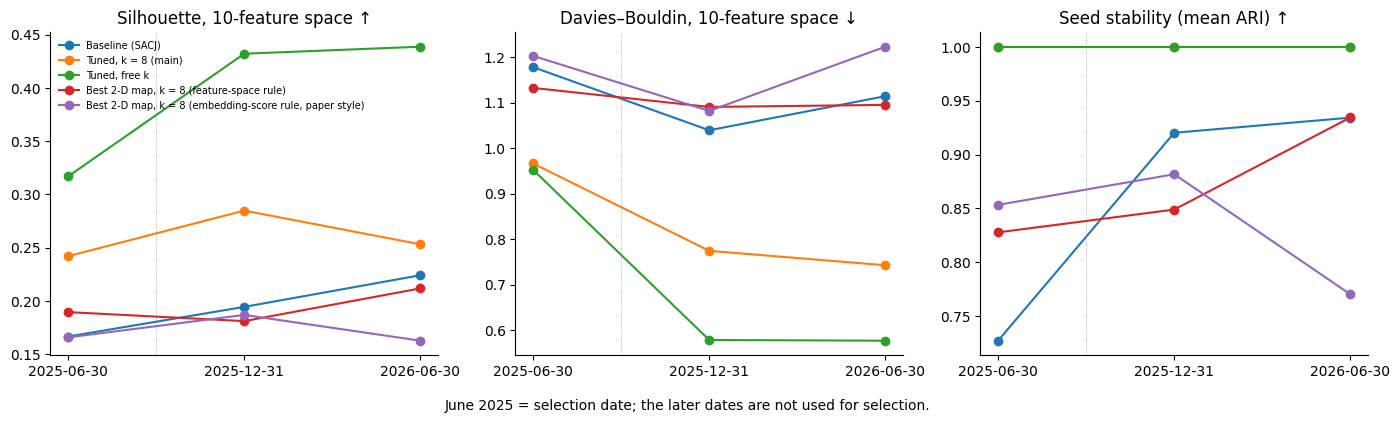

silhouette_features  \
date                                                        2025-06-30   
model                                                                    
Baseline (SACJ)                                                  0.166   
Best 2-D map, k = 8 (embedding-score rule, pape...               0.166   
Best 2-D map, k = 8 (feature-space rule)                         0.189   
Tuned, free k                                                    0.317   
Tuned, k = 8 (main)                                              0.242   

                                                                          \
date                                               2025-12-31 2026-06-30   
model                                                                      
Baseline (SACJ)                                         0.194      0.224   
Best 2-D map, k = 8 (embedding-score rule, pape...      0.187      0.162   
Best 2-D map, k = 8 (feature-space rule)                0.181      0.212   
Tuned, free k                                           0.432      0.439   
Tuned, k = 8 (main)                                     0.285      0.253   

                                                   davies_bouldin_features  \
date                                                            2025-06-30   
model                                                                        
Baseline (SACJ)                                                      1.178   
Best 2-D map, k = 8 (embedding-score rule, pape...                   1.202   
Best 2-D map, k = 8 (feature-space rule)                             1.132   
Tuned, free k                                                        0.952   
Tuned, k = 8 (main)                                                  0.966   

                                                                          \
date                                               2025-12-31 2026-06-30   
model                                                                      
Baseline (SACJ)                                         1.039      1.114   
Best 2-D map, k = 8 (embedding-score rule, pape...      1.081      1.223   
Best 2-D map, k = 8 (feature-space rule)                1.090      1.095   
Tuned, free k                                           0.578      0.577   
Tuned, k = 8 (main)                                     0.774      0.742   

                                                   singletons             \
date                                               2025-06-30 2025-12-31   
model                                                                      
Baseline (SACJ)                                           0.0        1.0   
Best 2-D map, k = 8 (embedding-score rule, pape...        0.0        0.0   
Best 2-D map, k = 8 (feature-space rule)                  0.0        1.0   
Tuned, free k                                             1.0        2.0   
Tuned, k = 8 (main)                                       1.0        2.0   

                                                              percentile_k8  \
date                                               2026-06-30    2025-06-30   
model                                                                         
Baseline (SACJ)                                           0.0        79.679   
Best 2-D map, k = 8 (embedding-score rule, pape...        0.0        78.966   
Best 2-D map, k = 8 (feature-space rule)                  1.0        91.087   
Tuned, free k                                             2.0           NaN   
Tuned, k = 8 (main)                                       3.0        98.039   

                                                                          
date                                               2025-12-31 2026-06-30  
model                                                                     
Baseline (SACJ)                                        72.727     87.879  
Best 2-D map, k = 8 (embedding-score rule, pape...     65.062     44.920 

In [25]:
rows = []
for d in DATES:
    pool_d = summary[(summary.date == d) & (summary.k == K) & summary.all_seeds_valid]
    pct = pool_d.silhouette_features.rank(pct=True)
    for name, row in choices.items():
        r = summary[(summary.rep_id == row.rep_id) & (summary.cl_id == row.cl_id) & (summary.date == d)].iloc[0]
        rows.append(dict(model=name, date=d, silhouette_features=r.silhouette_features, davies_bouldin_features=r.davies_bouldin_features,
                         silhouette_embedding=r.silhouette_embedding, davies_bouldin_embedding=r.davies_bouldin_embedding,
                         seed_ari_mean=r.seed_ari_mean, singletons=r.singletons_max, largest_share=r.largest_share_max,
                         percentile_k8=100 * pct.get(r.name, np.nan) if r.k == K else np.nan))
holdout = table(pd.DataFrame(rows), 'optimisation_later_dates', index=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, metric, title in zip(axes, ['silhouette_features', 'davies_bouldin_features', 'seed_ari_mean'],
                             ['Silhouette, 10-feature space ↑', 'Davies–Bouldin, 10-feature space ↓', 'Seed stability (mean ARI) ↑']):
    for name in choices:
        s = holdout[holdout.model == name]; ax.plot(s.date, s[metric], marker='o', label=name)
    ax.set_title(title); ax.axvline(0.5, color='grey', lw=0.5, ls=':')
axes[0].legend(frameon=False, fontsize=7); fig.text(0.5, -0.02, 'June 2025 = selection date; the later dates are not used for selection.', ha='center')
save(fig, 'optimisation_later_dates'); plt.show()
holdout.pivot(index='model', columns='date', values=['silhouette_features', 'davies_bouldin_features', 'singletons', 'percentile_k8']).round(3)

**Free-k diagnostic (protocol Section 6).** For the selected method (same reduction, clustering, linkage and distance), the best-supported k at each date
under the same ranking, with and without the eligibility rules. This is reported only; k = 8 is never replaced.

In [26]:
sel = top8.iloc[0]
same_method = (summary.rep_id == sel.rep_id) & (summary.cl_label == sel.cl_label)
rows = []
for d in DATES:
    pool_d = summary[same_method & (summary.date == d) & summary.all_seeds_valid]
    el_d = ranked(eligible(pool_d))
    rows.append(dict(date=d, best_k_any=int(ranked(pool_d).iloc[0].k), best_k_eligible=int(el_d.iloc[0].k) if len(el_d) else np.nan,
                     eligible_k=', '.join(map(str, sorted(el_d.k.astype(int)))) or 'none'))
free_k = table(pd.DataFrame(rows), 'free_k_diagnostic', index=False)
free_k

,date,best_k_any,best_k_eligible,eligible_k
0,2025-06-30,6,7.0,"7, 8"
1,2025-12-31,3,NaN,none
2,2026-06-30,2,NaN,none


### 4.7 Parameters to report
The settings of the baseline and the tuned model, as used in all later sections:

In [27]:
winner = top8.iloc[0]
MODELS = {
    'baseline': dict(name='Baseline: t-SNE + average/Manhattan hierarchical, k = 8', rep=BASELINE_REP, cl=BASELINE_CL),
    'tuned': dict(name=f'Selected: {winner.rep_label} + {winner.cl_label}, k = {int(winner.k)}',
                  rep=REPS[int(winner.rep_id)], cl=CLUSTERINGS[int(winner.cl_id)]),
}
MAIN = 'tuned'          # the protocol's selected method; set to 'baseline' to repeat the firm-level sections for the SACJ model

params = pd.DataFrame({m: {'Scaling': 'MinMax, fitted on June 2025 only', 'Features': '10 (Section 2)',
                           'Dimension reduction': rep_label(s['rep']), 'Clustering': cl_label(s['cl']),
                           'Number of clusters': s['cl']['k'], 'Selection': 'SACJ historical settings (replication baseline)' if m == 'baseline' else 'Protocol rule (Section 4.5), June 2025 only' + (' (DEVIATION: rules 4-5 dropped)' if SELECTION_DEVIATION else '')}
                       for m, s in MODELS.items()})
for m, s in MODELS.items():
    print(f"{m}: {s['name']}")
table(params, 'model_parameters')

baseline: Baseline: t-SNE + average/Manhattan hierarchical, k = 8
tuned: Selected: No reduction + hierarchical ward/euclidean, k = 8


,baseline,tuned
Scaling,"MinMax, fitted on June 2025 only","MinMax, fitted on June 2025 only"
Features,10 (Section 2),10 (Section 2)
Dimension reduction,"t-SNE (perp=5, lr=10, iter=300, dist=euclidean)",No reduction
Clustering,hierarchical average/cityblock,hierarchical ward/euclidean
Number of clusters,8,8
Selection,SACJ historical settings (replication baseline),"Protocol rule (Section 4.5), June 2025 only"


**Two cautions for the paper.**
* Scoring in the feature space favours methods that cluster that same space. This is why both geometries are reported, and why the SACJ baseline is kept for comparison.
* The method is chosen on 41 firms at one date. The later dates (Section 4.6), the free-k diagnostic and the perturbation runs (Section 6.2) show how well it holds up.

## 5. Final models at each date
Both models are refitted at each date with five seeds, with every setting unchanged. Where a model has no 2-D embedding, the scatter plots use PCA of the
10 scaled features **for display only**; the clustering itself uses the model's own representation.
Cluster numbers are canonical at each date (largest cluster first, ties by lowest member ticker), so they are comparable only through the matching in Section 7.

In [28]:
fitted = {}
for m, spec in MODELS.items():
    for d, s in product(DATES, SEEDS):
        z = represent(X[d], spec['rep'], s)
        fitted[m, d, s] = (z, assign(z, spec['cl'], s))

def canonical(labels, tickers):
    # Renumber clusters by size (largest first), then by lowest member ticker (protocol Section 7, deterministic ties).
    s = pd.Series(np.asarray(labels), index=np.asarray(tickers))
    order = sorted(s.unique(), key=lambda c: (-(s == c).sum(), min(s.index[s == c])))
    return s.map({c: i for i, c in enumerate(order)})

def labels_of(m, d, s=SEED):
    return canonical(fitted[m, d, s][1], snaps[d].ticker.values)

def display_xy(m, d, s=SEED):
    z = fitted[m, d, s][0]
    return z if z.shape[1] == 2 else PCA(2, svd_solver='full').fit_transform(z)

for d in DATES:   # the baseline must reproduce the tracked pipeline exactly
    assert adjusted_rand_score(A.cluster(A.embed(X[d], 'tsne', SEED), 'hierarchical', SEED, K), labels_of('baseline', d)) == 1.0
print('Baseline partitions match the pipeline at all three dates.')
rows = [dict(model=m, decision_date=d, ticker=t, company=info.loc[t, 'company'], sector=info.loc[t, 'sector_label'],
             cluster=int(c), imputation_sensitive=t in IMPUTED)
        for m in MODELS for d in DATES for t, c in labels_of(m, d).items()]
assignments = table(pd.DataFrame(rows), 'final_assignments', index=False)

Baseline partitions match the pipeline at all three dates.


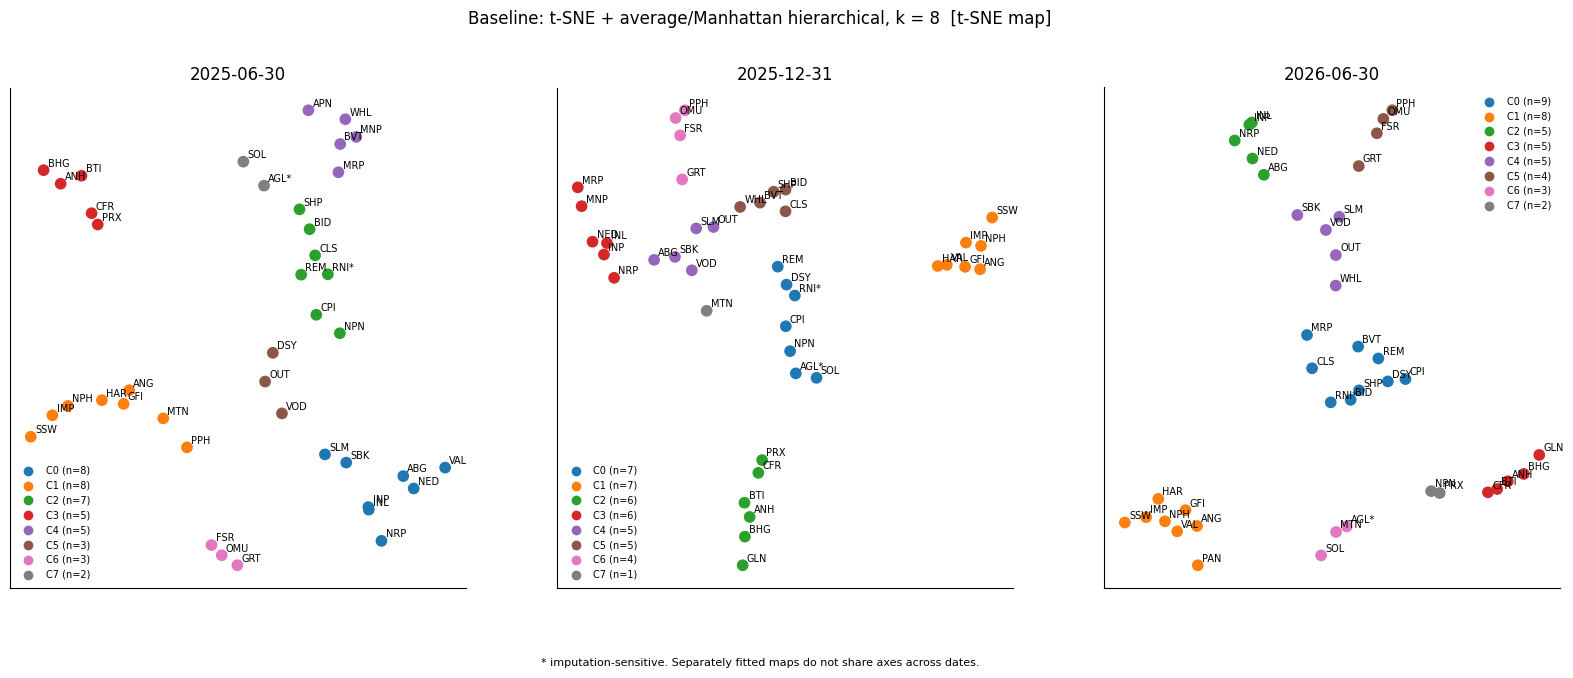

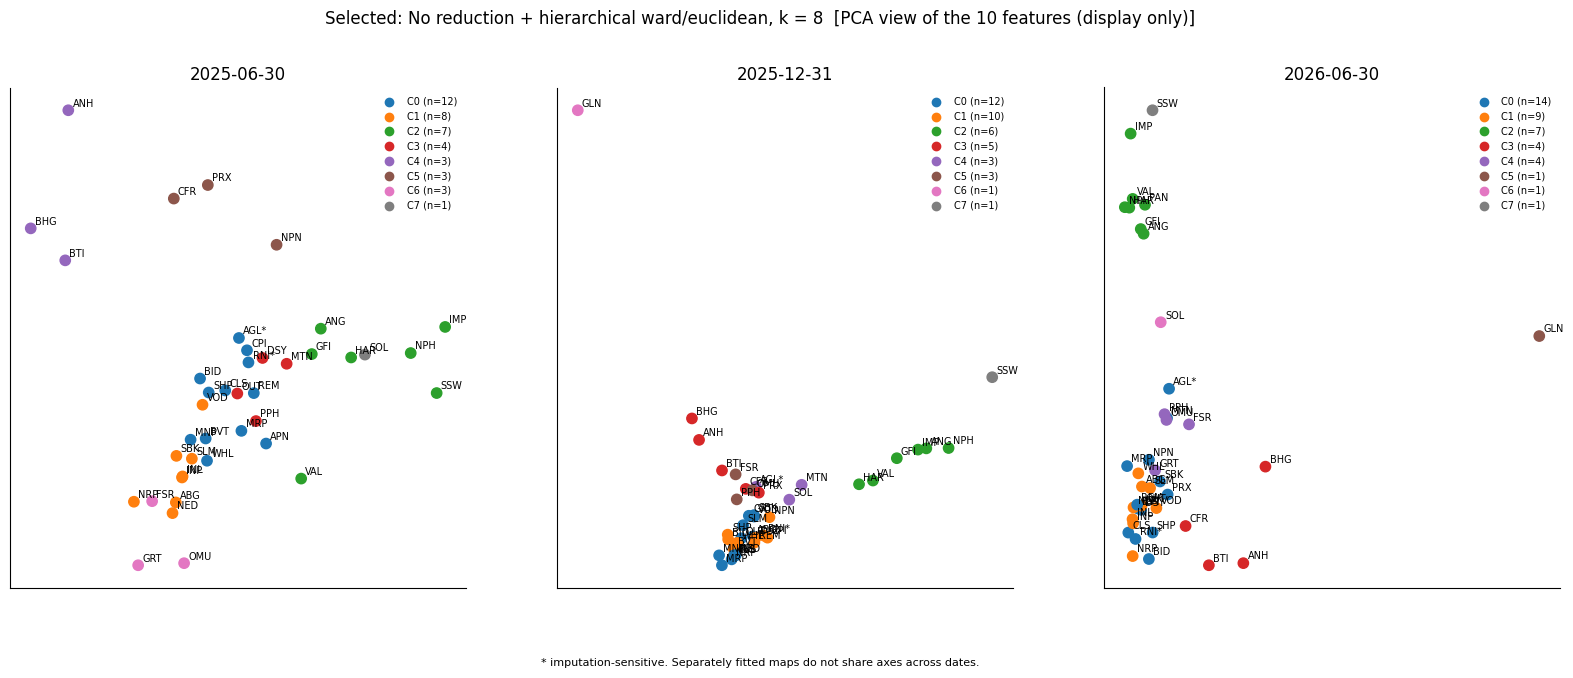

In [29]:
for m, spec in MODELS.items():
    fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
    for ax, d in zip(axes, DATES):
        xy, y = display_xy(m, d), labels_of(m, d).values
        ax.scatter(xy[:, 0], xy[:, 1], c=[plt.cm.tab10(c % 10) for c in y], s=55)
        for (x0, y0), t in zip(xy, snaps[d].ticker):
            ax.annotate(t + ('*' if t in IMPUTED else ''), (x0, y0), fontsize=7, xytext=(3, 3), textcoords='offset points')
        for c in sorted(set(y)):
            ax.scatter([], [], color=plt.cm.tab10(c % 10), label=f'C{c} (n={(y == c).sum()})')
        ax.legend(frameon=False, fontsize=7); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(d)
    axis_note = 't-SNE map' if spec['rep']['reduction'] == 'tsne' else 'PCA view of the 10 features (display only)'
    fig.suptitle(f"{spec['name']}  [{axis_note}]", y=1.0)
    fig.text(0.5, -0.01, '* imputation-sensitive. Separately fitted maps do not share axes across dates.', ha='center', fontsize=8)
    save(fig, f'cluster_maps_{m}'); plt.show()

### 5.1 Dendrograms over the years
The three dates are side by side. **Each ticker is coloured by its June 2025 cluster**, so firms that change peer group stand out as
colours mixing into a different branch. Black tickers were not in the index in June 2025.
The dashed line is the cut that gives k clusters. Each cell checks that this cut reproduces the model's clusters exactly.

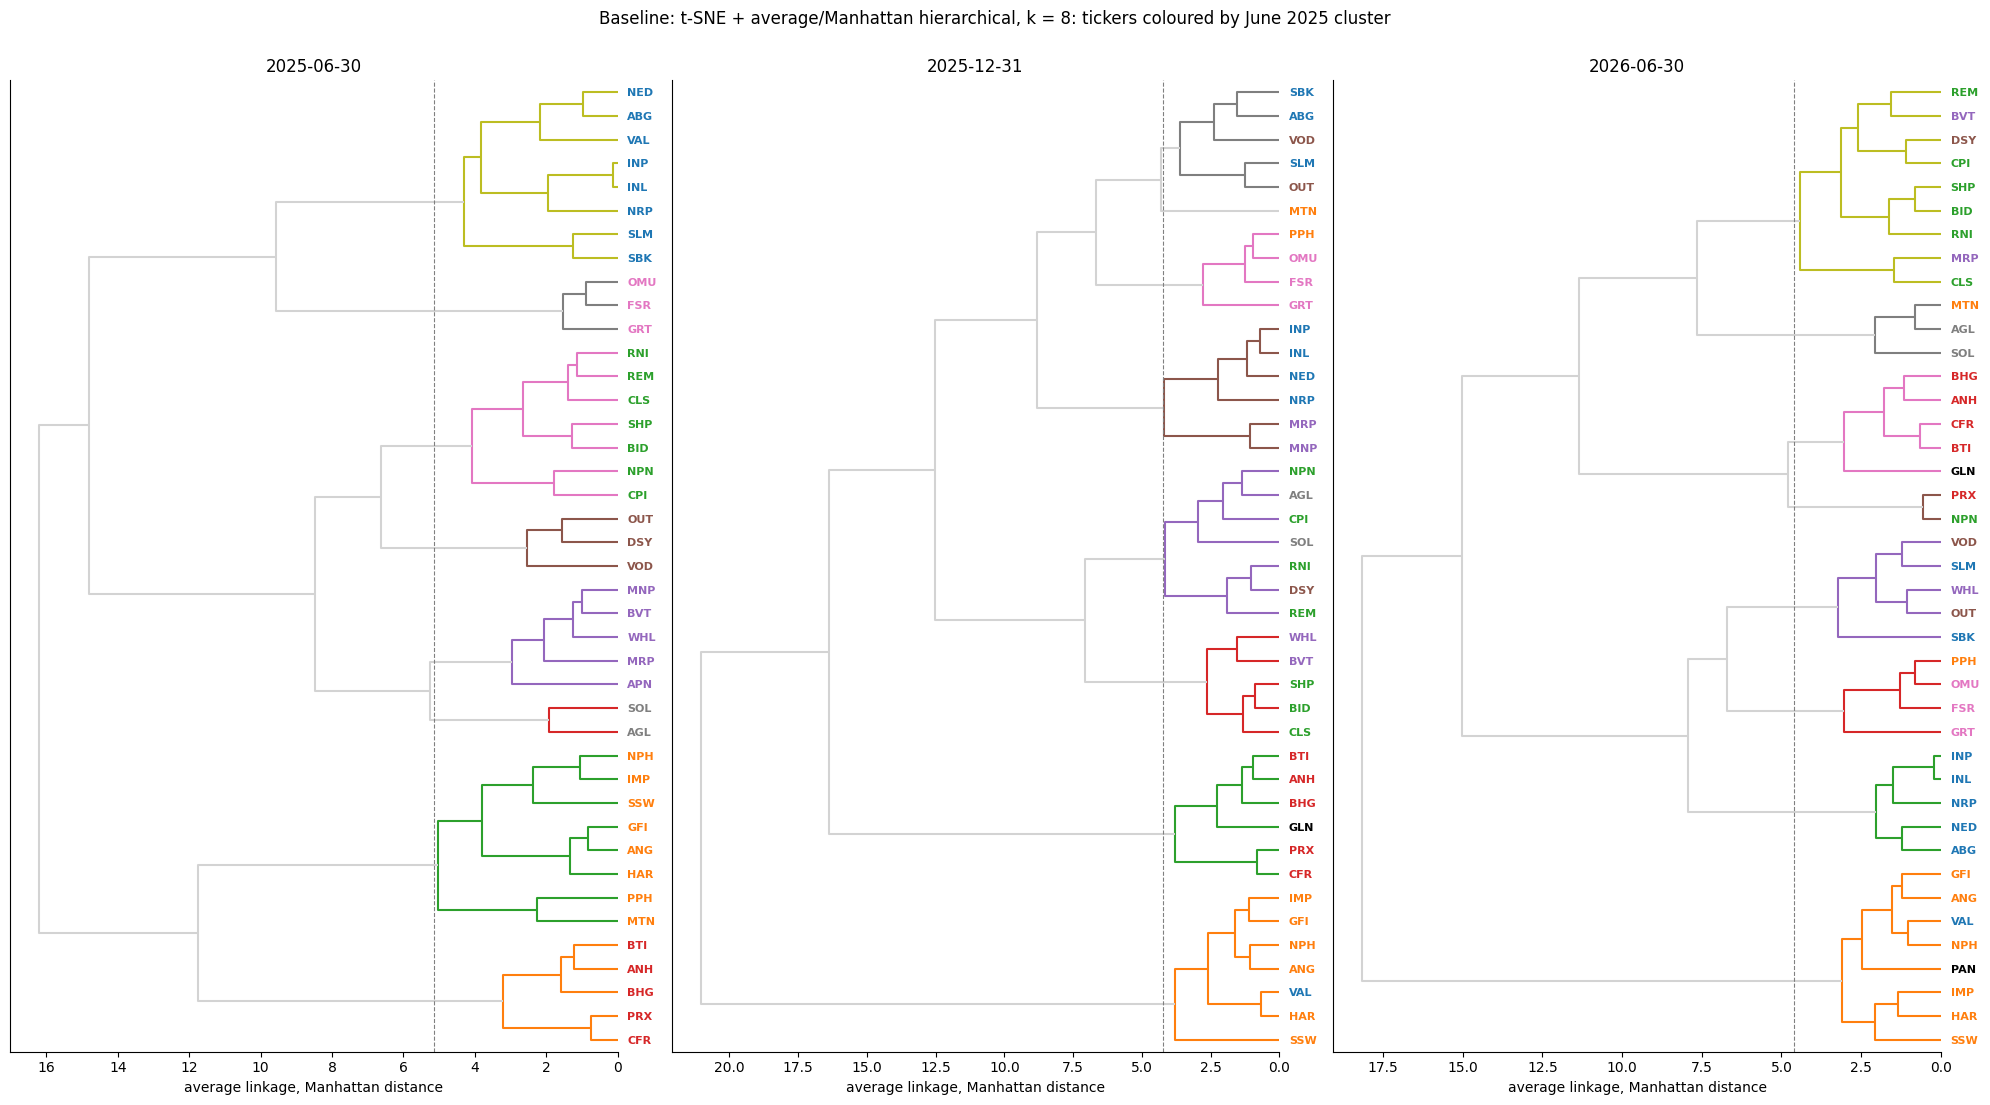

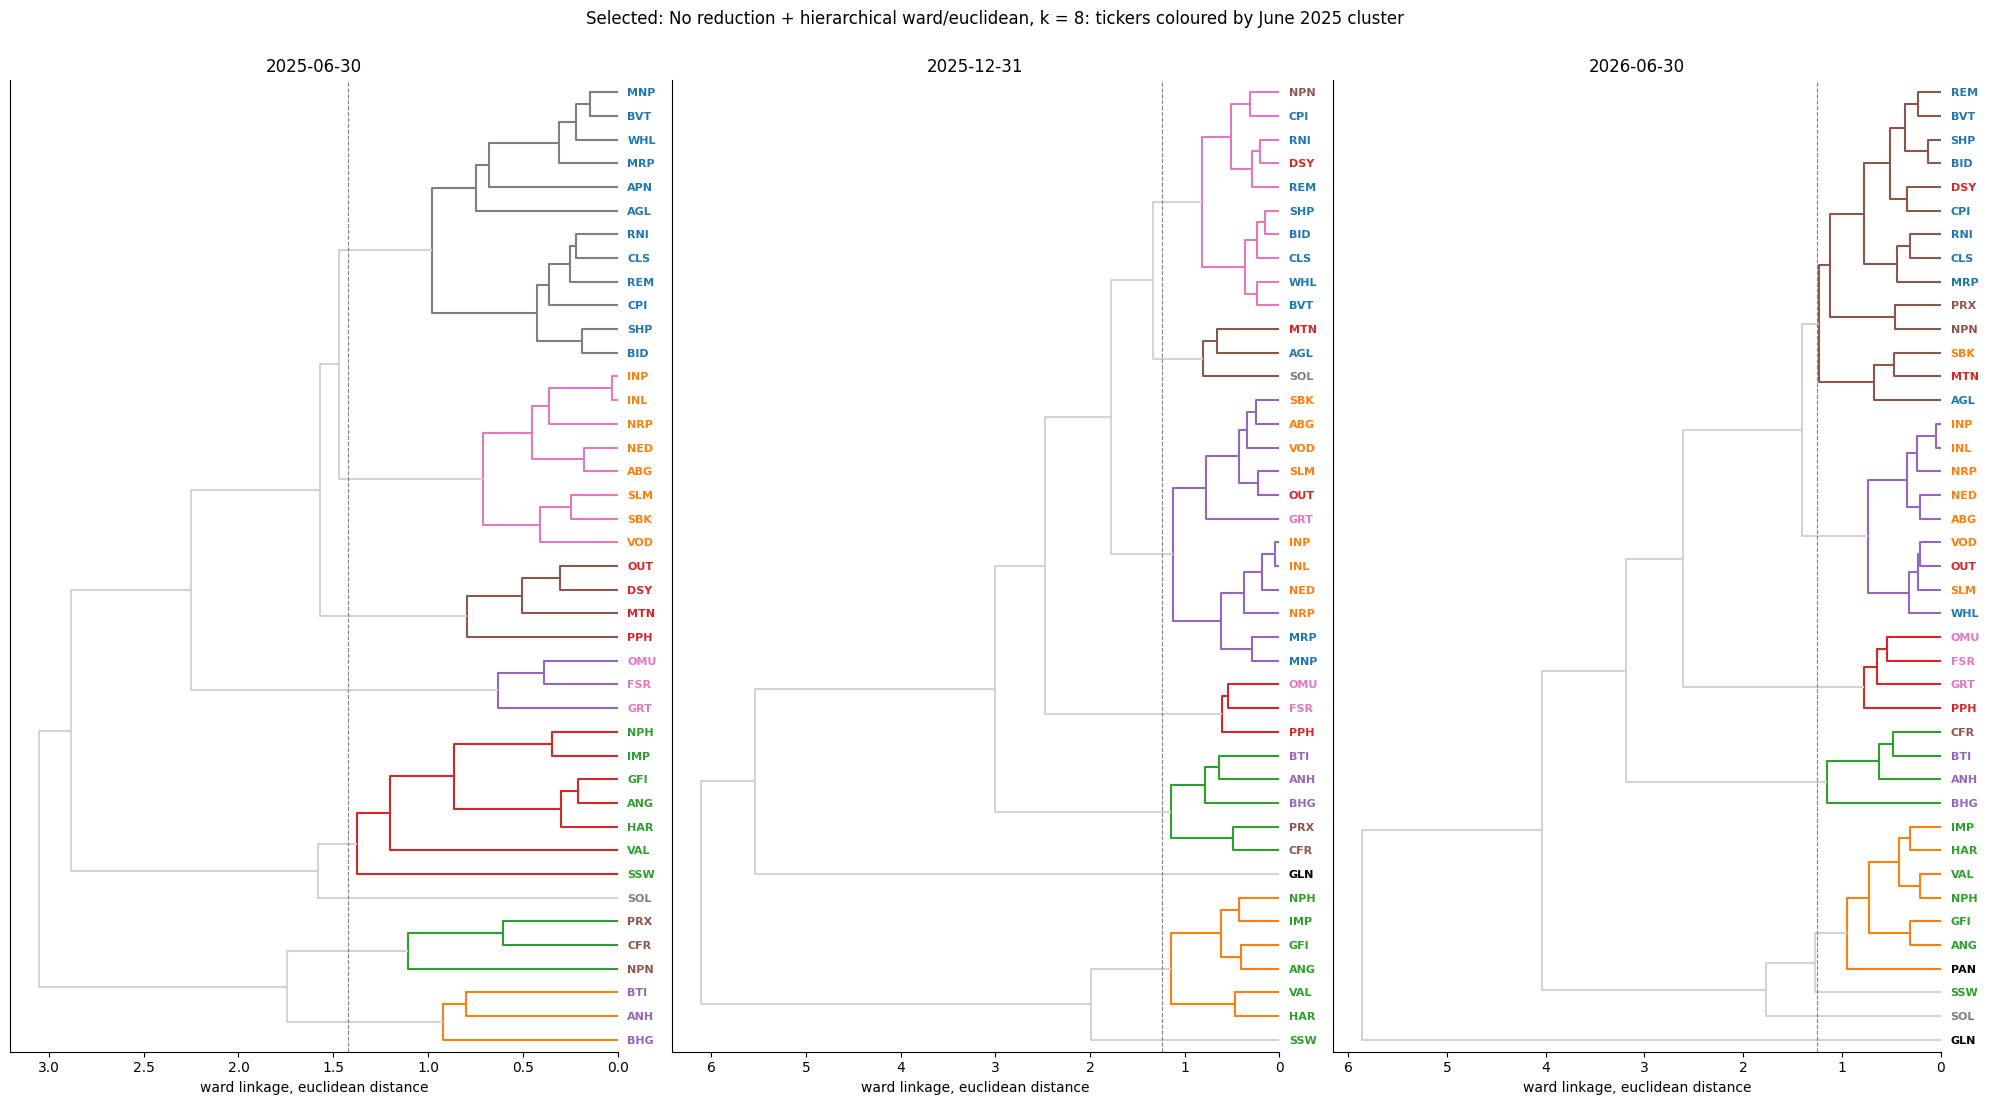

In [30]:
def draw_dendrograms(m):
    spec = MODELS[m]
    base_colour = {t: plt.cm.tab10(c % 10) for t, c in labels_of(m, DATES[0]).items()}
    fig, axes = plt.subplots(1, 3, figsize=(20, 11))
    for ax, d in zip(axes, DATES):
        z = fitted[m, d, SEED][0]
        Z = linkage(z, method=spec['cl']['linkage'], metric=spec['cl']['distance'])
        k = spec['cl']['k']
        assert adjusted_rand_score(fcluster(Z, k, 'maxclust'), labels_of(m, d)) == 1.0
        cut = (Z[-k, 2] + Z[-k + 1, 2]) / 2
        dendrogram(Z, labels=snaps[d].ticker.tolist(), orientation='left', color_threshold=cut,
                   above_threshold_color='lightgrey', ax=ax, leaf_font_size=8)
        for lbl in ax.get_ymajorticklabels():
            lbl.set_color(base_colour.get(lbl.get_text(), 'black')); lbl.set_fontweight('bold')
        ax.axvline(cut, ls='--', color='grey', lw=0.8); ax.set_title(d)
        ax.set_xlabel(f"{spec['cl']['linkage']} linkage, {spec['cl']['distance'].replace('cityblock', 'Manhattan')} distance")
    fig.suptitle(f"{spec['name']}: tickers coloured by June 2025 cluster", y=1.0)
    fig.tight_layout(); save(fig, f'dendrograms_over_time_{m}'); plt.show()

for m in MODELS:
    if MODELS[m]['cl']['clustering'] == 'hierarchical':
        draw_dendrograms(m)

### 5.2 Who is in each cluster, and what characterises it

In [31]:
rows = []
for m, d in product(MODELS, DATES):
    lab = labels_of(m, d)
    for c in sorted(lab.unique()):
        firms = lab.index[lab == c]
        rows.append(dict(model=m, date=d, cluster=c, n=len(firms), firms=', '.join(firms),
                         sectors='; '.join(f'{s} ({n})' for s, n in info.loc[firms, 'sector_label'].value_counts().items())))
members_table = table(pd.DataFrame(rows), 'cluster_members', index=False)
with pd.option_context('display.max_colwidth', 110):
    display(members_table[members_table.model == MAIN])

,model,date,cluster,n,firms,sectors
24,tuned,2025-06-30,0,12,"AGL, APN, BID, BVT, CLS, CPI, MNP, MRP, REM, RNI, SHP, WHL",Consumer Services (5); Financials (3); Basic Materials (2); Health Care (1); Industrials (1)
25,tuned,2025-06-30,1,8,"ABG, INL, INP, NED, NRP, SBK, SLM, VOD",Financials (7); Telecommunications (1)
26,tuned,2025-06-30,2,7,"ANG, GFI, HAR, IMP, NPH, SSW, VAL",Basic Materials (7)
27,tuned,2025-06-30,3,4,"DSY, MTN, OUT, PPH",Financials (2); Telecommunications (1); Consumer Services (1)
28,tuned,2025-06-30,4,3,"ANH, BHG, BTI",Consumer Goods (2); Basic Materials (1)
29,tuned,2025-06-30,5,3,"CFR, NPN, PRX",Technology (2); Consumer Goods (1)
30,tuned,2025-06-30,6,3,"FSR, GRT, OMU",Financials (3)
31,tuned,2025-06-30,7,1,SOL,Basic Materials (1)
32,tuned,2025-12-31,0,12,"ABG, GRT, INL, INP, MNP, MRP, NED, NRP, OUT, SBK, SLM, VOD",Financials (9); Basic Materials (1); Consumer Services (1); Telecommunications (1)
33,tuned,2025-12-31,1,10,"BID, BVT, CLS, CPI, DSY, NPN, REM, RNI, SHP, WHL",Consumer Services (4); Financials (4); Industrials (1); Technology (1)


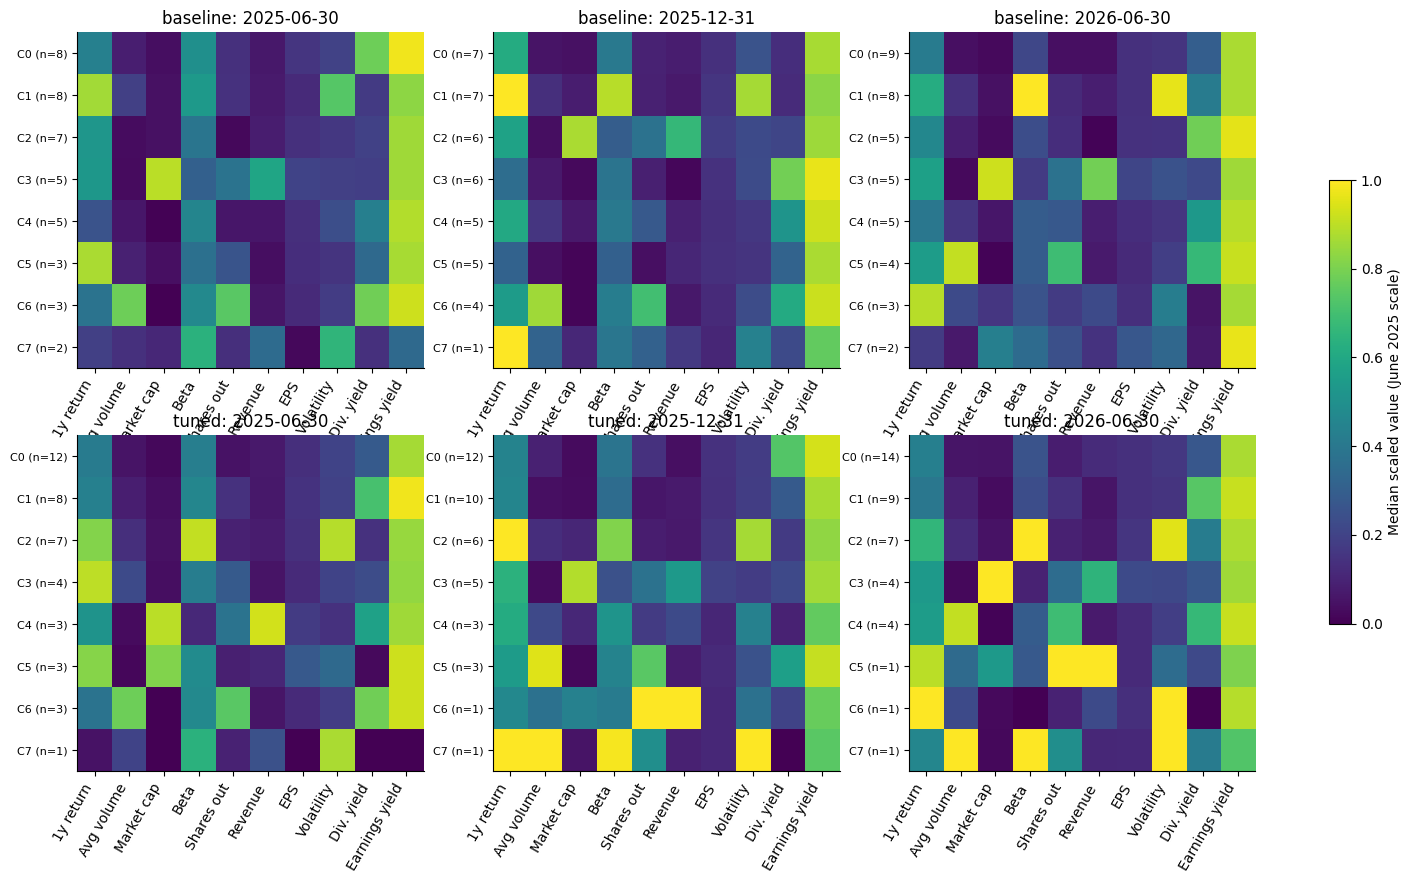

In [32]:
fig, axes = plt.subplots(len(MODELS), 3, figsize=(19, 4.8 * len(MODELS)))
for row, m in zip(axes, MODELS):
    for ax, d in zip(row, DATES):
        lab = labels_of(m, d).values
        profile = pd.DataFrame(X[d], columns=NAMES).groupby(lab).median()
        im = ax.imshow(profile, cmap='viridis', vmin=0, vmax=1, aspect='auto')
        ax.set_xticks(range(len(NAMES)), NAMES, rotation=60, ha='right')
        ax.set_yticks(range(len(profile)), [f'C{c} (n={(lab == c).sum()})' for c in profile.index], fontsize=8)
        ax.set_title(f'{m}: {d}')
fig.colorbar(im, ax=axes, shrink=0.6, label='Median scaled value (June 2025 scale)')
save(fig, 'cluster_profiles'); plt.show()

## 6. Stability
### 6.1 Seed stability (full sample)
Every pair of the five seeds is compared (10 pairs per date). The SACJ paper reported ARI = 1.0 for its baseline.
A deterministic method (no random step) has seed ARI = 1.0 by construction. That says nothing about sensitivity to the data, which is why Section 6.2 exists.

In [33]:
rows = [dict(model=m, date=d, seed_a=a, seed_b=b, ari=adjusted_rand_score(labels_of(m, d, a), labels_of(m, d, b)),
             nmi=normalized_mutual_info_score(labels_of(m, d, a), labels_of(m, d, b)))
        for m in MODELS for d in DATES for a, b in combinations(SEEDS, 2)]
seed_pairs = table(pd.DataFrame(rows), 'seed_stability_pairs', index=False)
seed_summary = table(seed_pairs.groupby(['model', 'date'])[['ari', 'nmi']].agg(['mean', 'min']), 'seed_stability_summary')
seed_summary.round(3)

ari           nmi       
                      mean    min   mean    min
model    date                                  
baseline 2025-06-30  0.727  0.526  0.872  0.789
         2025-12-31  0.920  0.883  0.959  0.932
         2026-06-30  0.934  0.836  0.967  0.919
tuned    2025-06-30  1.000  1.000  1.000  1.000
         2025-12-31  1.000  1.000  1.000  1.000
         2026-06-30  1.000  1.000  1.000  1.000

### 6.2 Stability under data perturbation (protocol Section 6.1)
At each date: instruments sorted by ticker, *m* = ⌈0.9 *n*⌉ (37 of 41), B = 100 subsamples drawn with
`default_rng(20251108)` in date order, b = 0…99. Run b refits the method unchanged on its subsample (frozen June 2025 scaling, k = 8,
seed 42 + (b mod 5)). A run fails if it gives fewer than k clusters. Every draw is stored.
A firm-level property is reported as a **stability proportion** over the successful runs in which the firm is included.
It is **robust** at ≥ 0.80, and *not estimable* with fewer than 20 evaluable runs. This is a stability threshold, not a confidence level.

In [34]:
B, ROBUST, MIN_RUNS = 100, 0.80, 20

def draw_subsamples(dates, seed):
    rng = np.random.default_rng(seed)
    out = {}
    for d in dates:
        n = len(snaps[d]); m_ = int(np.ceil(0.9 * n))
        out[d] = [np.sort(rng.choice(n, size=m_, replace=False)) for _ in range(B)]
    return out

def fit_subset(spec, x, seed):
    try:
        y = assign(represent(x, spec['rep'], seed), spec['cl'], seed)
    except Exception as err:                      # a failed fit is recorded, never retried with other settings
        return None, f'error: {type(err).__name__}'
    k_found = len(np.unique(y[y >= 0]))
    return (y, 'ok') if k_found == spec['cl']['k'] else (None, f'only {k_found} clusters')

DRAWS = draw_subsamples(DATES, 20251108)
assert all(np.array_equal(np.sort(i), i) and len(set(i)) == int(np.ceil(0.9 * len(snaps[d]))) for d in DATES for i in DRAWS[d])

start = time.time()
jobs = [(m, d, b) for m in MODELS for d in DATES for b in range(B)]
results = Parallel(n_jobs=-1)(delayed(fit_subset)(MODELS[m], X[d][DRAWS[d][b]], SEED + b % 5) for m, d, b in jobs)
PERT, rows = {}, []
for (m, d, b), (y, status) in zip(jobs, results):
    tick = snaps[d].ticker.values[DRAWS[d][b]]
    PERT[m, d, b] = None if y is None else canonical(y, tick)
    rows.append(dict(model=m, date=d, b=b, seed=SEED + b % 5, status=status, tickers=' '.join(tick),
                     labels='' if y is None else ' '.join(map(str, PERT[m, d, b].values))))
pert_runs = pd.DataFrame(rows)
pert_runs.to_csv(TAB / 'perturbation_runs.csv.gz', index=False)
print(f'{len(jobs)} perturbation fits in {time.time() - start:.0f} s.')
table(pert_runs.assign(ok=pert_runs.status == 'ok').groupby(['model', 'date']).ok.agg(['sum', 'count']).rename(columns={'sum': 'successful', 'count': 'runs'}),
      'perturbation_success')

600 perturbation fits in 13 s.


successful  runs
model    date                        
baseline 2025-06-30         100   100
         2025-12-31         100   100
         2026-06-30         100   100
tuned    2025-06-30         100   100
         2025-12-31         100   100
         2026-06-30         100   100

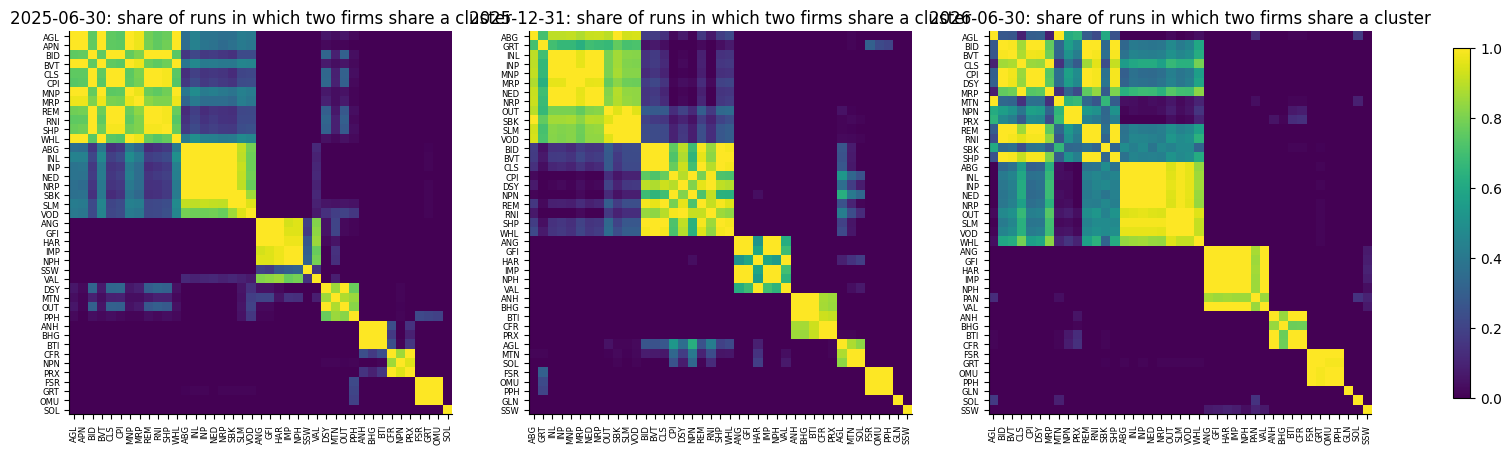

In [35]:
def proportion(m, d, prop):
    # Stability proportion of a per-run firm property. prop(labels) -> Series of bools indexed by ticker (NaN = not evaluable).
    hits, n = pd.Series(0.0, index=snaps[d].ticker), pd.Series(0, index=snaps[d].ticker)
    for b in range(B):
        lab = PERT[m, d, b]
        if lab is None:
            continue
        v = prop(lab).dropna()
        hits[v.index] += v.astype(float); n[v.index] += 1
    return pd.DataFrame({'stability': (hits / n).where(n >= MIN_RUNS), 'evaluable_runs': n})

# How often does each pair of firms share a cluster across the perturbation runs? (co-assignment, main model, each date)
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, d in zip(axes, DATES):
    tick = snaps[d].ticker.values
    same, both = np.zeros((len(tick),) * 2), np.zeros((len(tick),) * 2)
    for b in range(B):
        lab = PERT[MAIN, d, b]
        if lab is None:
            continue
        idx = DRAWS[d][b]; v = lab.values
        both[np.ix_(idx, idx)] += 1; same[np.ix_(idx, idx)] += v[:, None] == v[None, :]
    order = np.argsort(labels_of(MAIN, d).values, kind='stable')
    co = (same / np.maximum(both, 1))[np.ix_(order, order)]
    im = ax.imshow(co, cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(len(tick)), tick[order], rotation=90, fontsize=6); ax.set_yticks(range(len(tick)), tick[order], fontsize=6)
    ax.set_title(f'{d}: share of runs in which two firms share a cluster')
fig.colorbar(im, ax=axes, shrink=0.7); save(fig, 'perturbation_coassignment'); plt.show()

Firms are ordered by their full-sample cluster. Bright blocks on the diagonal are peer groups that survive perturbation; speckled blocks are fragile.

## 7. Shifts over time: cluster matching, moves and stable firms (protocol Section 7)
### 7.1 Entries and exits
Entering and exiting firms appear at only one of the two dates, so they cannot "change cluster". They are listed with the peers they join or leave.

In [36]:
rows = []
for _, e in events.iterrows():
    before, after = e.period.split(' → ')
    d = after if e.event == 'entry' else before
    lab = labels_of(MAIN, d)
    rows.append(dict(event=e.event, ticker=e.ticker, sector=e.sector_label, date_observed=d, cluster=lab[e.ticker],
                     cluster_peers=', '.join(lab.index[(lab == lab[e.ticker]) & (lab.index != e.ticker)])))
table(pd.DataFrame(rows), 'entry_exit_context', index=False)

,event,ticker,sector,date_observed,cluster,cluster_peers
0,entry,GLN,Basic Materials,2025-12-31,6,
1,exit,APN,Health Care,2025-06-30,0,"AGL, BID, BVT, CLS, CPI, MNP, MRP, REM, RNI, S..."
2,entry,PAN,Basic Materials,2026-06-30,2,"ANG, GFI, HAR, IMP, NPH, VAL"
3,exit,MNP,Basic Materials,2025-12-31,0,"ABG, GRT, INL, INP, MRP, NED, NRP, OUT, SBK, S..."


### 7.2 Matching clusters across dates
* **Similarity:** Jaccard overlap of cluster memberships, counted on **continuing firms only** (numerator and denominator).
* **Assignment:** edges with J < 0.30 are set to 0, the maximum-weight one-to-one assignment is solved (`linear_sum_assignment`), and zero-weight pairs are discarded.
  Clusters are numbered by size, then by lowest member ticker, so ties resolve deterministically.
* **Events:** *exited* (all members left the index), *dissolved* (unmatched at *t*), *new* (unmatched at *t*+1).
  **Splits** and **merges** are a separate relation: one cluster with J ≥ 0.30 to two or more on the other side.
* **Secondary matching (sensitivity):** Hungarian assignment on the Euclidean distance between cluster median profiles.

In [37]:
MATCH_J = 0.30
TRANSITIONS = [(DATES[0], DATES[1]), (DATES[1], DATES[2]), (DATES[0], DATES[2])]   # the last one: June 2025 base → current

def jaccard_matrix(old, new):
    common = old.index.intersection(new.index)
    o, n_ = old[common], new[common]
    sets_o = {i: set(o.index[o == i]) for i in sorted(o.unique())}
    sets_n = {j: set(n_.index[n_ == j]) for j in sorted(n_.unique())}
    return pd.DataFrame([[len(a & b) / len(a | b) for b in sets_n.values()] for a in sets_o.values()],
                        index=list(sets_o), columns=list(sets_n))

def match(old, new):
    J = jaccard_matrix(old, new)
    W = J.where(J >= MATCH_J, 0.0).to_numpy()
    r, c = linear_sum_assignment(W, maximize=True)
    return {J.index[i]: J.columns[j] for i, j in zip(r, c) if W[i, j] > 0}, J

def moved(old, new, pairs):
    common = old.index.intersection(new.index)
    return pd.Series([pairs.get(old[t]) != new[t] for t in common], index=common)

def profile_match(m, before, after):
    med = lambda d: pd.DataFrame(X[d], index=snaps[d].ticker).groupby(labels_of(m, d).values).median()
    a, b = med(before), med(after)
    dist = np.linalg.norm(a.to_numpy()[:, None, :] - b.to_numpy()[None, :, :], axis=2)
    r, c = linear_sum_assignment(dist)
    return {a.index[i]: b.index[j] for i, j in zip(r, c)}

FULL_MATCH, cluster_rows = {}, []
for m in MODELS:
    for before, after in TRANSITIONS:
        old, new = labels_of(m, before), labels_of(m, after)
        pairs, J = match(old, new)
        FULL_MATCH[m, before, after] = (pairs, J)
        prof = profile_match(m, before, after)
        for i in sorted(old.unique()):
            if i not in J.index:
                event = 'exited'
            else:
                event = f'matched → C{pairs[i]}' if i in pairs else 'dissolved'
            split_to = [] if i not in J.index else [f'C{j}' for j in J.columns[J.loc[i] >= MATCH_J]]
            cluster_rows.append(dict(model=m, transition=f'{before} → {after}', side='from', cluster=f'C{i}', size=int((old == i).sum()),
                                     event=event, best_J=J.loc[i].max() if i in J.index else np.nan,
                                     split_into=', '.join(split_to) if len(split_to) >= 2 else '',
                                     profile_match=f'C{prof.get(i)}' if i in prof else '', profile_agrees=prof.get(i) == pairs.get(i) if i in pairs else np.nan))
        for j in sorted(new.unique()):
            if j in pairs.values():
                continue
            merged = [] if j not in J.columns else [f'C{i}' for i in J.index[J[j] >= MATCH_J]]
            cluster_rows.append(dict(model=m, transition=f'{before} → {after}', side='to', cluster=f'C{j}', size=int((new == j).sum()),
                                     event='new (entrants only)' if j not in J.columns else 'new',
                                     best_J=J[j].max() if j in J.columns else np.nan, split_into='', profile_match='', profile_agrees=np.nan))
        for j in J.columns[(J >= MATCH_J).sum(axis=0) >= 2]:
            cluster_rows.append(dict(model=m, transition=f'{before} → {after}', side='to', cluster=f'C{j}', size=int((new == j).sum()),
                                     event='merge of ' + ', '.join(f'C{i}' for i in J.index[J[j] >= MATCH_J]),
                                     best_J=J[j].max(), split_into='', profile_match='', profile_agrees=np.nan))
cluster_events = table(pd.DataFrame(cluster_rows), 'cluster_matching_events', index=False)
agree = cluster_events[cluster_events.event.str.startswith('matched')].groupby(['model', 'transition']).profile_agrees.mean()
print('Share of accepted Jaccard matches that the profile-distance matching reproduces:'); print(agree.round(2).to_string())
with pd.option_context('display.max_colwidth', 40):
    display(cluster_events[cluster_events.model == MAIN].round(2))

Share of accepted Jaccard matches that the profile-distance matching reproduces:
model     transition             
baseline  2025-06-30 → 2025-12-31    0.166667
          2025-06-30 → 2026-06-30    0.142857
          2025-12-31 → 2026-06-30    0.142857
tuned     2025-06-30 → 2025-12-31    0.166667
          2025-06-30 → 2026-06-30    0.166667
          2025-12-31 → 2026-06-30       0.125


,model,transition,side,cluster,size,event,best_J,split_into,profile_match,profile_agrees
30,tuned,2025-06-30 → 2025-12-31,from,C0,12,matched → C1,0.62,,C1,True
31,tuned,2025-06-30 → 2025-12-31,from,C1,8,matched → C0,0.67,,C0,True
32,tuned,2025-06-30 → 2025-12-31,from,C2,7,matched → C2,0.86,,C2,True
33,tuned,2025-06-30 → 2025-12-31,from,C3,4,dissolved,0.17,,C7,NaN
34,tuned,2025-06-30 → 2025-12-31,from,C4,3,matched → C3,0.60,,C6,False
35,tuned,2025-06-30 → 2025-12-31,from,C5,3,dissolved,0.33,,C3,NaN
36,tuned,2025-06-30 → 2025-12-31,from,C6,3,matched → C5,0.50,,C5,True
37,tuned,2025-06-30 → 2025-12-31,from,C7,1,matched → C4,0.33,,C4,True
38,tuned,2025-06-30 → 2025-12-31,to,C6,1,new (entrants only),NaN,,,NaN
39,tuned,2025-06-30 → 2025-12-31,to,C7,1,new,0.14,,,NaN


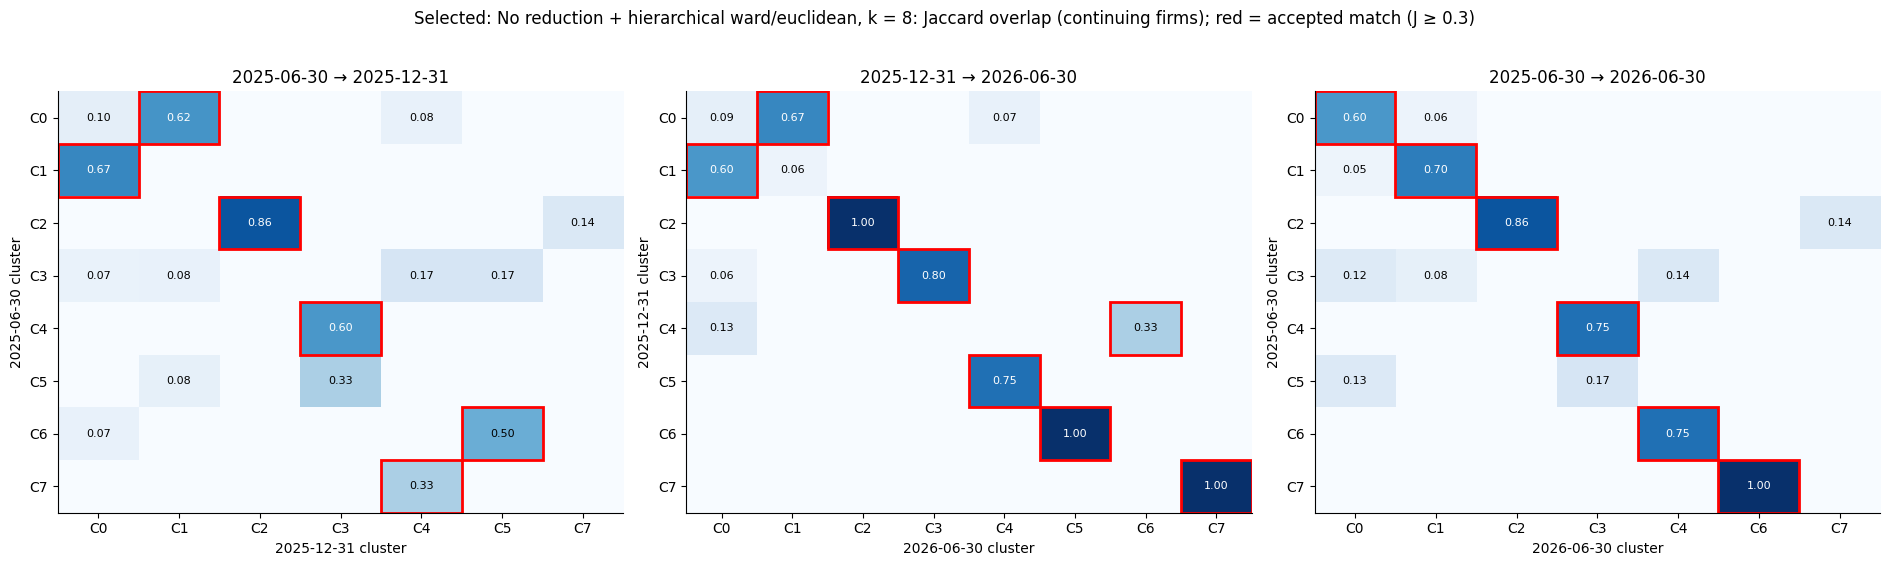

In [38]:
fig, axes = plt.subplots(1, len(TRANSITIONS), figsize=(19, 5.5))
for ax, (before, after) in zip(axes, TRANSITIONS):
    pairs, J = FULL_MATCH[MAIN, before, after]
    ax.imshow(J, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(J.shape[1]), [f'C{c}' for c in J.columns]); ax.set_yticks(range(J.shape[0]), [f'C{c}' for c in J.index])
    for i, jx in product(range(J.shape[0]), range(J.shape[1])):
        v = J.iloc[i, jx]
        if v > 0:
            ax.text(jx, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v > 0.5 else 'black')
        if pairs.get(J.index[i]) == J.columns[jx]:
            ax.add_patch(plt.Rectangle((jx - 0.5, i - 0.5), 1, 1, fill=False, ec='red', lw=2))
    ax.set_xlabel(f'{after} cluster'); ax.set_ylabel(f'{before} cluster'); ax.set_title(f'{before} → {after}')
fig.suptitle(f"{MODELS[MAIN]['name']}: Jaccard overlap (continuing firms); red = accepted match (J ≥ {MATCH_J})", y=1.02)
fig.tight_layout(); save(fig, 'cluster_matching_jaccard'); plt.show()

### 7.3 Perturbation support for cluster matches, and robust firm moves
In run b, each perturbed cluster is first related to a full-sample cluster at the same date (the same matching rule, on the firms in that run).
A full-sample match is *supported* in run b if the related perturbed clusters are matched to each other.
A firm **moves** if its cluster at *t*+1 is not the accepted match of its cluster at *t*. It is a **robust move** if it moves in the full sample
**and** in ≥ 80% of the evaluable runs (included at both dates, both fits successful; subsamples paired by b).

In [39]:
def relate(full, pert):
    # perturbed cluster -> full-sample cluster at the same date
    pairs, _ = match(full[pert.index], pert)
    return {p: f for f, p in pairs.items()}

support_rows, move_rows = [], []
for m in MODELS:
    for before, after in TRANSITIONS:
        full0, full1 = labels_of(m, before), labels_of(m, after)
        pairs, J = FULL_MATCH[m, before, after]
        full_moved = moved(full0, full1, pairs)
        hits, n_ok = {p: 0 for p in pairs.items()}, 0
        mv_hits, mv_n = pd.Series(0, index=full_moved.index), pd.Series(0, index=full_moved.index)
        for b in range(B):
            p0, p1 = PERT[m, before, b], PERT[m, after, b]
            if p0 is None or p1 is None:
                continue
            n_ok += 1
            r0, r1 = relate(full0, p0), relate(full1, p1)
            pb, _ = match(p0, p1)
            mapped = {(r0.get(a), r1.get(c)) for a, c in pb.items()}
            for pr in hits:
                hits[pr] += pr in mapped
            mv = moved(p0, p1, pb)
            mv = mv[mv.index.isin(full_moved.index)]
            mv_hits[mv.index] += mv.astype(int); mv_n[mv.index] += 1
        for (i, j), h in hits.items():
            support_rows.append(dict(model=m, transition=f'{before} → {after}', match=f'C{i} → C{j}', J=J.loc[i, j], support=h / n_ok if n_ok else np.nan, runs=n_ok))
        stab = (mv_hits / mv_n).where(mv_n >= MIN_RUNS)
        for t in full_moved.index:
            robust_mv = bool(full_moved[t]) and pd.notna(stab[t]) and stab[t] >= ROBUST
            status = ('robust move' if robust_mv else 'move, not robust') if full_moved[t] else ('stays with matched cluster' if pd.notna(stab[t]) else 'not estimable')
            move_rows.append(dict(model=m, transition=f'{before} → {after}', ticker=t, sector=info.loc[t, 'sector_label'],
                                  cluster_before=int(full0[t]), cluster_after=int(full1[t]), matched_to=pairs.get(full0[t], 'none (dissolved)'),
                                  moved_full_sample=bool(full_moved[t]), move_stability=stab[t], evaluable_runs=int(mv_n[t]), status=status,
                                  imputation_sensitive=t in IMPUTED))
match_support = table(pd.DataFrame(support_rows), 'cluster_match_support', index=False)
moves = table(pd.DataFrame(move_rows), 'firm_moves', index=False)
display(match_support[match_support.model == MAIN].round(2))
move_counts = table(moves.pivot_table(index=['model', 'transition'], columns='status', values='ticker', aggfunc='count', fill_value=0), 'firm_move_counts')
move_counts

,model,transition,match,J,support,runs
20,tuned,2025-06-30 → 2025-12-31,C0 → C1,0.62,0.76,100
21,tuned,2025-06-30 → 2025-12-31,C1 → C0,0.67,0.77,100
22,tuned,2025-06-30 → 2025-12-31,C2 → C2,0.86,0.97,100
23,tuned,2025-06-30 → 2025-12-31,C4 → C3,0.60,0.94,100
24,tuned,2025-06-30 → 2025-12-31,C6 → C5,0.50,0.98,100
25,tuned,2025-06-30 → 2025-12-31,C7 → C4,0.33,0.47,100
26,tuned,2025-12-31 → 2026-06-30,C0 → C1,0.67,0.76,100
27,tuned,2025-12-31 → 2026-06-30,C1 → C0,0.60,0.55,100
28,tuned,2025-12-31 → 2026-06-30,C2 → C2,1.00,1.00,100
29,tuned,2025-12-31 → 2026-06-30,C3 → C3,0.80,0.97,100


status                            move, not robust  robust move  \
model    transition                                               
baseline 2025-06-30 → 2025-12-31                13            3   
         2025-06-30 → 2026-06-30                 3            8   
         2025-12-31 → 2026-06-30                 7            4   
tuned    2025-06-30 → 2025-12-31                 8            4   
         2025-06-30 → 2026-06-30                 7            3   
         2025-12-31 → 2026-06-30                 6            1   

status                            stays with matched cluster  
model    transition                                           
baseline 2025-06-30 → 2025-12-31                          24  
         2025-06-30 → 2026-06-30                          28  
         2025-12-31 → 2026-06-30                          29  
tuned    2025-06-30 → 2025-12-31                          28  
         2025-06-30 → 2026-06-30                          29  
         2025-12-31 → 2026-06-30                          33

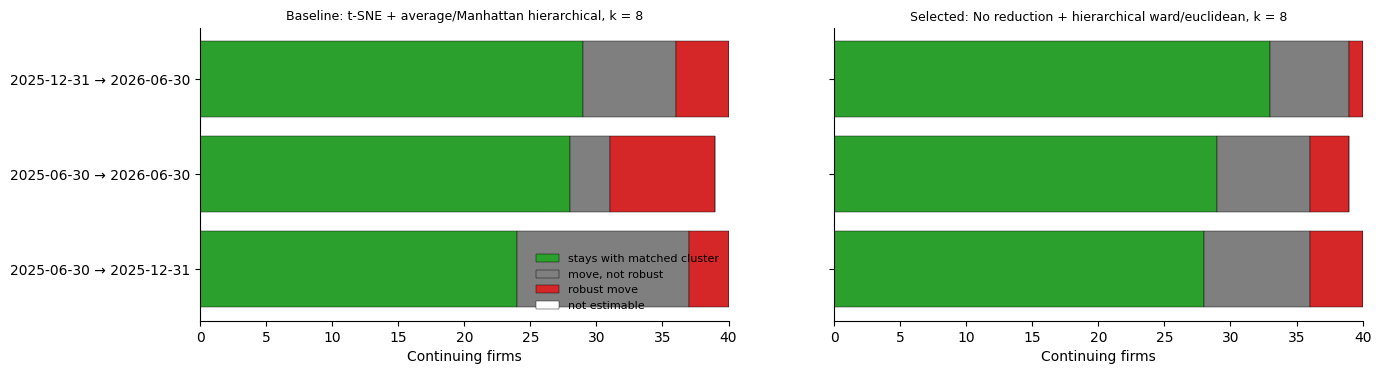

In [40]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 3.8), sharey=True)
colours = {'stays with matched cluster': 'tab:green', 'move, not robust': 'tab:grey', 'robust move': 'tab:red', 'not estimable': 'white'}
for ax, m in zip(axes, MODELS):
    c = move_counts.loc[m].reindex(columns=list(colours), fill_value=0)
    left = np.zeros(len(c))
    for status, colour in colours.items():
        ax.barh(range(len(c)), c[status], left=left, color=colour, edgecolor='black', lw=0.3, label=status); left += c[status].values
    ax.set_yticks(range(len(c)), c.index); ax.set_xlabel('Continuing firms'); ax.set_title(MODELS[m]['name'], fontsize=9)
axes[0].legend(frameon=False, fontsize=8, loc='lower right'); save(fig, 'firm_move_counts'); plt.show()

**From the June 2025 base to the current date (June 2026), main model.** Robust movers first, with their peers before and after.

In [41]:
def peer_list(lab, t):
    return ', '.join(lab.index[(lab == lab[t]) & (lab.index != t)]) or '(alone)'

base_to_now = moves[(moves.model == MAIN) & (moves.transition == f'{DATES[0]} → {DATES[-1]}')].copy()
other = 'baseline' if MAIN != 'baseline' else 'tuned'
other_status = moves[(moves.model == other) & (moves.transition == f'{DATES[0]} → {DATES[-1]}')].set_index('ticker').status
base_to_now[f'status_in_{other}'] = base_to_now.ticker.map(other_status)
base_to_now['peers_2025'] = [peer_list(labels_of(MAIN, DATES[0]), t) for t in base_to_now.ticker]
base_to_now['peers_now'] = [peer_list(labels_of(MAIN, DATES[-1]), t) for t in base_to_now.ticker]
with pd.option_context('display.max_colwidth', 70):
    display(base_to_now[base_to_now.status == 'robust move']
            [['ticker', 'sector', 'cluster_before', 'cluster_after', 'move_stability', 'peers_2025', 'peers_now', f'status_in_{other}', 'imputation_sensitive']].round(2))
for s in ['move, not robust', 'stays with matched cluster', 'not estimable']:
    print(f'{s}:', ', '.join(base_to_now[base_to_now.status == s].ticker) or '—')
both = sorted(set(base_to_now[(base_to_now.status == 'robust move') & (base_to_now[f'status_in_{other}'] == 'robust move')].ticker))
print(f'Robust move under BOTH models: {", ".join(both) or "none"}')

,ticker,sector,cluster_before,cluster_after,move_stability,peers_2025,peers_now,status_in_baseline,imputation_sensitive
219,MTN,Telecommunications,3,0,0.98,"DSY, OUT, PPH","AGL, BID, BVT, CLS, CPI, DSY, MRP, NPN, PRX, REM, RNI, SBK, SHP",robust move,False
225,OUT,Financials,3,1,0.93,"DSY, MTN, PPH","ABG, INL, INP, NED, NRP, SLM, VOD, WHL",stays with matched cluster,False
226,PPH,Consumer Services,3,4,0.80,"DSY, MTN, OUT","FSR, GRT, OMU",robust move,False


move, not robust: CFR, DSY, NPN, PRX, SBK, SSW, WHL
stays with matched cluster: ABG, AGL, ANG, ANH, BHG, BID, BTI, BVT, CLS, CPI, FSR, GFI, GRT, HAR, IMP, INL, INP, MRP, NED, NPH, NRP, OMU, REM, RNI, SHP, SLM, SOL, VAL, VOD
not estimable: —
Robust move under BOTH models: MTN, PPH


### 7.4 Label-free check (descriptive only)
For each continuing firm: the Jaccard overlap of its full-sample peer sets (continuing firms only) at *t* and *t*+1, next to the median of the same
statistic between the full-sample fit and each perturbation run at the same date (its noise level). No threshold or classification is applied.

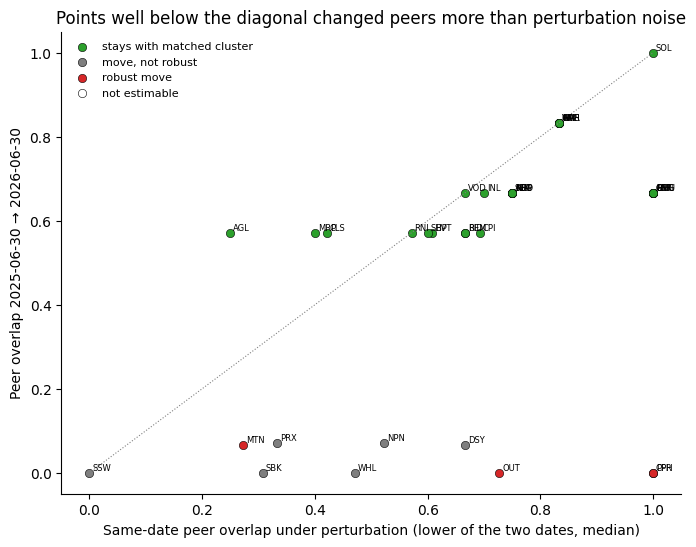

In [42]:
def peer_sets(lab, keep):
    keep = [t for t in keep if t in lab.index]
    return {t: {u for u in keep if u != t and lab[u] == lab[t]} for t in keep}

def jac(a, b):
    return 1.0 if not a and not b else len(a & b) / len(a | b)

rows = []
for before, after in TRANSITIONS:
    common = sorted(members[before] & members[after])
    f0, f1 = peer_sets(labels_of(MAIN, before), common), peer_sets(labels_of(MAIN, after), common)
    noise = {d: {t: [] for t in common} for d in (before, after)}
    for d in (before, after):
        full = labels_of(MAIN, d)
        for b in range(B):
            lab = PERT[MAIN, d, b]
            if lab is None:
                continue
            keep = [t for t in common if t in lab.index]
            pf, pp = peer_sets(full, keep), peer_sets(lab, keep)
            for t in keep:
                noise[d][t].append(jac(pf[t], pp[t]))
    for t in common:
        rows.append(dict(transition=f'{before} → {after}', ticker=t, peer_overlap_across_dates=jac(f0[t], f1[t]),
                         same_date_noise_before=np.median(noise[before][t]), same_date_noise_after=np.median(noise[after][t])))
label_free = table(pd.DataFrame(rows), 'label_free_peer_overlap', index=False)
lf = label_free[label_free.transition == f'{DATES[0]} → {DATES[-1]}'].merge(base_to_now[['ticker', 'status']], on='ticker')
fig, ax = plt.subplots(figsize=(8, 6))
for s, colour in colours.items():
    q = lf[lf.status == s]
    ax.scatter(q[['same_date_noise_before', 'same_date_noise_after']].min(axis=1), q.peer_overlap_across_dates, color=colour, edgecolor='black', lw=0.4, label=s)
for r in lf.itertuples():
    ax.annotate(r.ticker, (min(r.same_date_noise_before, r.same_date_noise_after), r.peer_overlap_across_dates), fontsize=6, xytext=(2, 2), textcoords='offset points')
ax.plot([0, 1], [0, 1], color='grey', ls=':', lw=0.8)
ax.set_xlabel('Same-date peer overlap under perturbation (lower of the two dates, median)'); ax.set_ylabel(f'Peer overlap {DATES[0]} → {DATES[-1]}')
ax.legend(frameon=False, fontsize=8); ax.set_title('Points well below the diagonal changed peers more than perturbation noise')
save(fig, 'label_free_peer_overlap'); plt.show()

## 8. Firm-level signals (protocol Section 8)
Three separate signals at each date, each 1, 0 or NA:

* **S1 sector divergence**: in a cluster whose dominant sector (strict plurality, ≥ 2 members) differs from the firm's own,
  in ≥ 80% of evaluable perturbation runs. S1 = 0 means *no detected dominance-based divergence*, not sector coherence; its reason is recorded.
  S1 = NA when the firm is isolated (S3 = 1) or not estimable.
* **S3 isolation**: alone in its cluster in the full-sample fit **and** in ≥ 80% of evaluable runs.
* **S2 multivariate outlier**: individual squared Mahalanobis distance in the 10 scaled features, against the scaled-Beta reference.

Sector labels are the legacy Listcorp categories, used as an external comparator, not a verified ground truth.

### 8.1 Agreement with the sector comparator

ari                  nmi              
                      mean    min    max   mean    min    max
model    date                                                
baseline 2025-06-30  0.220  0.164  0.268  0.521  0.472  0.560
         2025-12-31  0.256  0.243  0.271  0.552  0.534  0.575
         2026-06-30  0.303  0.292  0.306  0.596  0.575  0.601
tuned    2025-06-30  0.265  0.265  0.265  0.556  0.556  0.556
         2025-12-31  0.262  0.262  0.262  0.496  0.496  0.496
         2026-06-30  0.201  0.201  0.201  0.477  0.477  0.477

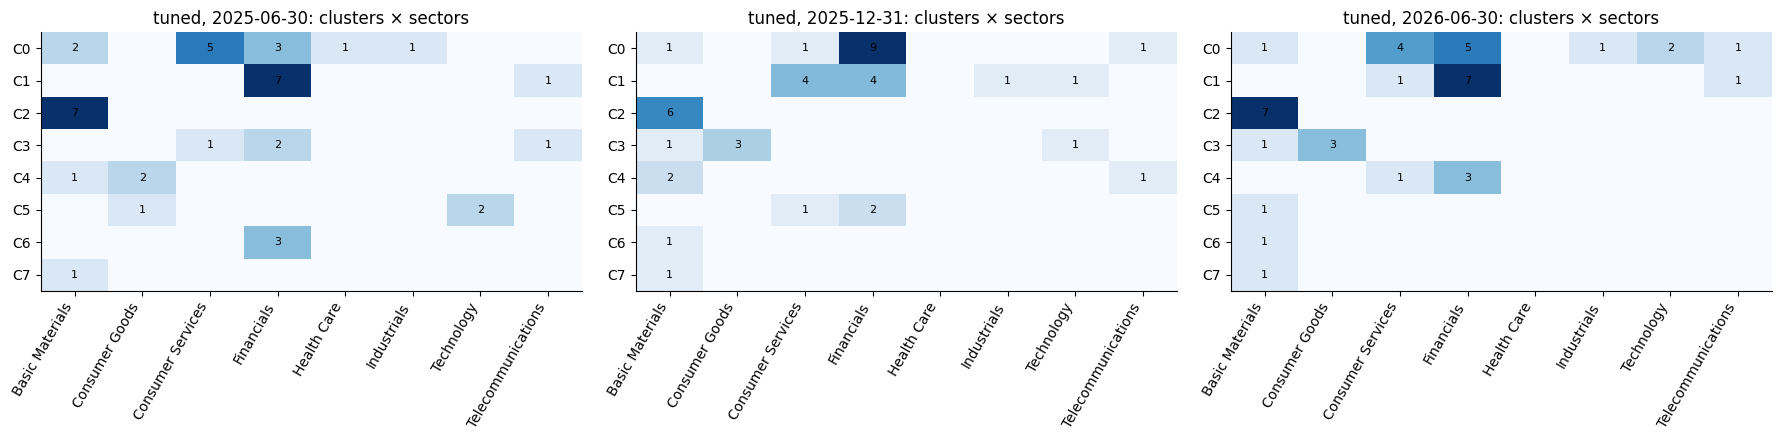

In [43]:
rows = [dict(model=m, date=d, seed=s, ari=adjusted_rand_score(snaps[d].sector_label, labels_of(m, d, s)),
             nmi=normalized_mutual_info_score(snaps[d].sector_label, labels_of(m, d, s))) for m in MODELS for d in DATES for s in SEEDS]
sector_agree = pd.DataFrame(rows)
display(table(sector_agree.groupby(['model', 'date'])[['ari', 'nmi']].agg(['mean', 'min', 'max']), 'sector_agreement').round(3))

sectors = sorted(data.sector_label.unique())
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, d in zip(axes, DATES):
    lab = labels_of(MAIN, d)
    ct = pd.crosstab(lab.values, info.loc[lab.index, 'sector_label'].values).reindex(columns=sectors, fill_value=0)
    ax.imshow(ct, cmap='Blues', aspect='auto')
    ax.set_xticks(range(len(sectors)), sectors, rotation=60, ha='right'); ax.set_yticks(range(len(ct)), [f'C{c}' for c in ct.index])
    for i, jx in product(range(ct.shape[0]), range(ct.shape[1])):
        if ct.iloc[i, jx]:
            ax.text(jx, i, ct.iloc[i, jx], ha='center', va='center', fontsize=8)
    ax.set_title(f'{MAIN}, {d}: clusters × sectors')
fig.tight_layout(); save(fig, 'cluster_sector_crosstab'); plt.show()

### 8.2 S1 sector divergence and S3 isolation

In [44]:
def divergence_status(tickers, sector, labels):
    # 'divergent:<dominant sector>', 'aligned', 'no dominant sector' or 'singleton' for each firm in one run.
    status = pd.Series(index=tickers, dtype=object)
    for c in np.unique(labels):
        in_c = labels == c
        sec = sector[in_c]
        counts = pd.Series(sec).value_counts()
        if in_c.sum() == 1:
            status[tickers[in_c]] = 'singleton'
        elif counts.iloc[0] >= 2 and (len(counts) == 1 or counts.iloc[0] > counts.iloc[1]):
            status[tickers[in_c]] = np.where(sec == counts.index[0], 'aligned', 'divergent:' + counts.index[0])
        else:
            status[tickers[in_c]] = 'no dominant sector'
    return status

def run_status(lab):
    return divergence_status(lab.index.values, info.loc[lab.index, 'sector_label'].values, lab.values)

rows = []
for m, d in product(MODELS, DATES):
    full = run_status(labels_of(m, d))
    div = proportion(m, d, lambda lab: run_status(lab).str.startswith('divergent'))
    iso = proportion(m, d, lambda lab: run_status(lab) == 'singleton')
    for t in snaps[d].ticker:
        s3 = int(full[t] == 'singleton' and pd.notna(iso.stability[t]) and iso.stability[t] >= ROBUST)
        if s3:
            s1, reason = np.nan, 'NA: isolated'
        elif pd.isna(div.stability[t]):
            s1, reason = np.nan, 'NA: not estimable'
        elif div.stability[t] >= ROBUST:
            s1, reason = 1, 'divergent'
        else:
            s1, reason = 0, 'not robust' if full[t].startswith('divergent') else full[t]
        rows.append(dict(model=m, date=d, ticker=t, sector=info.loc[t, 'sector_label'], full_sample_status=full[t],
                         divergence_stability=div.stability[t], isolation_stability=iso.stability[t], evaluable_runs=int(div.evaluable_runs[t]),
                         S1=s1, S1_reason=reason, S3=s3, imputation_sensitive=t in IMPUTED))
s13 = table(pd.DataFrame(rows), 'signals_S1_S3', index=False)
print('S1 = 1 (robust sector divergence) and S3 = 1 (isolation), main model:')
with pd.option_context('display.max_colwidth', 40):
    display(s13[(s13.model == MAIN) & ((s13.S1 == 1) | (s13.S3 == 1))]
            [['date', 'ticker', 'sector', 'full_sample_status', 'divergence_stability', 'isolation_stability', 'S1', 'S3', 'imputation_sensitive']].round(2))
table(s13.groupby(['model', 'date']).agg(S1=('S1', lambda s: int((s == 1).sum())), S3=('S3', 'sum'),
                                         S1_NA=('S1', lambda s: int(s.isna().sum()))), 'signal_counts_S1_S3')

S1 = 1 (robust sector divergence) and S3 = 1 (isolation), main model:


,date,ticker,sector,full_sample_status,divergence_stability,isolation_stability,S1,S3,imputation_sensitive
124,2025-06-30,AGL,Basic Materials,divergent:Consumer Services,0.95,0.00,1.0,0,True
127,2025-06-30,APN,Health Care,divergent:Consumer Services,0.97,0.00,1.0,0,False
128,2025-06-30,BHG,Basic Materials,divergent:Consumer Goods,0.84,0.00,1.0,0,False
131,2025-06-30,BVT,Industrials,divergent:Consumer Services,0.94,0.00,1.0,0,False
143,2025-06-30,MNP,Basic Materials,divergent:Consumer Services,0.94,0.00,1.0,0,False
145,2025-06-30,MTN,Telecommunications,divergent:Financials,0.84,0.00,1.0,0,False
152,2025-06-30,PPH,Consumer Services,divergent:Financials,0.90,0.00,1.0,0,False
159,2025-06-30,SOL,Basic Materials,singleton,0.00,1.00,NaN,1,False
162,2025-06-30,VOD,Telecommunications,divergent:Financials,0.89,0.00,1.0,0,False
168,2025-12-31,BHG,Basic Materials,divergent:Consumer Goods,0.94,0.00,1.0,0,False


S1  S3  S1_NA
model    date                     
baseline 2025-06-30   4   0      0
         2025-12-31   6   0      0
         2026-06-30   4   0      0
tuned    2025-06-30   8   1      1
         2025-12-31   6   2      2
         2026-06-30   4   3      3

### 8.3 S2: individual squared Mahalanobis distance
For each firm, D² = (x − x̄)ᵀ S⁻¹ (x − x̄), with that date's mean and unbiased covariance (ddof = 1), inverted with `numpy.linalg.inv`.
If S is rank-deficient or its condition number exceeds 10⁸, S2 is NA at that date.

* **Primary reference** (each firm is measured against its own sample): under iid multivariate normality,
  D² · n / (n − 1)² ~ Beta(p/2, (n − p − 1)/2). S2 = 1 above the 95% quantile, which is 16.36 for n = 41, p = 10.
  This is a benchmark only: equity data are skewed and partly imputed, so a 5% rate is **not** assumed.
* **Identity:** Σ D² = (n − 1)p for any sample, so S2 is a *relative* screen within each date.
* **SACJ replication reference** p(n − 1)/(n − p) · F₀.₉₅(p, n − p) = 27.78: a mean-vector test, reported descriptively with **no error rate**.
* **Borderline**: ratio D² / reference in [0.9, 1.1).

In [45]:
def mahalanobis_sq(x):
    S = np.cov(x, rowvar=False)
    cond, rank = np.linalg.cond(S), np.linalg.matrix_rank(S)
    if rank < x.shape[1] or cond > 1e8:
        return None, cond, rank
    c = x - x.mean(axis=0)
    return np.einsum('ij,jk,ik->i', c, np.linalg.inv(S), c), cond, rank

def beta_ref(n, p, alpha=0.05):
    return (n - 1) ** 2 / n * stats.beta.ppf(1 - alpha, p / 2, (n - p - 1) / 2)

def sacj_ref(n, p, alpha=0.05):
    return p * (n - 1) / (n - p) * stats.f.ppf(1 - alpha, p, n - p)

n0, p0 = len(snaps[DATES[0]]), len(FEATURES)
refs = pd.Series({'Beta reference, α = 0.05 (primary)': beta_ref(n0, p0), 'Beta reference, Bonferroni α = 0.05/n': beta_ref(n0, p0, 0.05 / n0),
                  'Beta reference, α = 0.01': beta_ref(n0, p0, 0.01), 'Beta reference, α = 0.10': beta_ref(n0, p0, 0.10),
                  'SACJ F reference (descriptive)': sacj_ref(n0, p0), 'Maximum attainable D² = (n−1)²/n': (n0 - 1) ** 2 / n0,
                  'SACJ check: n = 40, p = 2 (paper: 6.66)': sacj_ref(40, 2)}, name=f'n = {n0}, p = {p0}')
display(refs.round(2).to_frame())

def d2_table(xs, label):
    rows = []
    for d in DATES:
        x, tick = xs[d], snaps[d].ticker.values
        d2, cond, rank = mahalanobis_sq(x)
        n, p = x.shape
        if d2 is None:
            rows += [dict(space=label, date=d, ticker=t, D2=np.nan, condition_number=cond, rank=rank) for t in tick]
            continue
        assert np.isclose(d2.sum(), (n - 1) * p)                       # identity
        ref = beta_ref(n, p)
        for i, t in enumerate(tick):
            rows.append(dict(space=label, date=d, ticker=t, D2=d2[i], condition_number=cond, rank=rank, reference=ref, ratio=d2[i] / ref,
                             S2=int(d2[i] > ref), borderline=0.9 <= d2[i] / ref < 1.1,
                             bonferroni=int(d2[i] > beta_ref(n, p, 0.05 / n)), alpha_01=int(d2[i] > beta_ref(n, p, 0.01)),
                             alpha_10=int(d2[i] > beta_ref(n, p, 0.10)), sacj_F=int(d2[i] > sacj_ref(n, p))))
    return pd.DataFrame(rows)

s2 = d2_table(X, 'features')
# Implementation check: D² is invariant to affine rescaling, so refitting MinMax at each date must give the same values.
for d in DATES:
    raw = A.numeric_matrix(snaps[d])
    assert np.allclose(mahalanobis_sq(MinMaxScaler().fit_transform(raw))[0], s2[s2.date == d].D2.values)
print('Invariance check passed: frozen and refitted MinMax scaling give identical D².')
s2['sector'] = s2.ticker.map(info.sector_label); s2['imputation_sensitive'] = s2.ticker.isin(IMPUTED)
table(s2, 'signals_S2', index=False)
print('Conditioning:', s2.groupby('date')[['condition_number', 'rank']].first().round(0).to_dict('index'))
counts_s2 = s2.groupby('date')[['S2', 'bonferroni', 'alpha_01', 'alpha_10', 'sacj_F']].sum()
counts_s2['iid-normal expectation (primary)'] = 0.05 * s2.groupby('date').size()
table(counts_s2, 'signal_counts_S2')

,"n = 41, p = 10"
"Beta reference, α = 0.05 (primary)",16.36
"Beta reference, Bonferroni α = 0.05/n",22.59
"Beta reference, α = 0.01",19.44
"Beta reference, α = 0.10",14.73
SACJ F reference (descriptive),27.78
Maximum attainable D² = (n−1)²/n,39.02
"SACJ check: n = 40, p = 2 (paper: 6.66)",6.66


Invariance check passed: frozen and refitted MinMax scaling give identical D².
Conditioning: {'2025-06-30': {'condition_number': 39.0, 'rank': 10}, '2025-12-31': {'condition_number': 745.0, 'rank': 10}, '2026-06-30': {'condition_number': 533.0, 'rank': 10}}


,S2,bonferroni,alpha_01,alpha_10,sacj_F,iid-normal expectation (primary)
date,,,,,,
2025-06-30,9,4,6,9,3,2.05
2025-12-31,6,2,4,7,1,2.05
2026-06-30,7,3,5,7,2,2.05


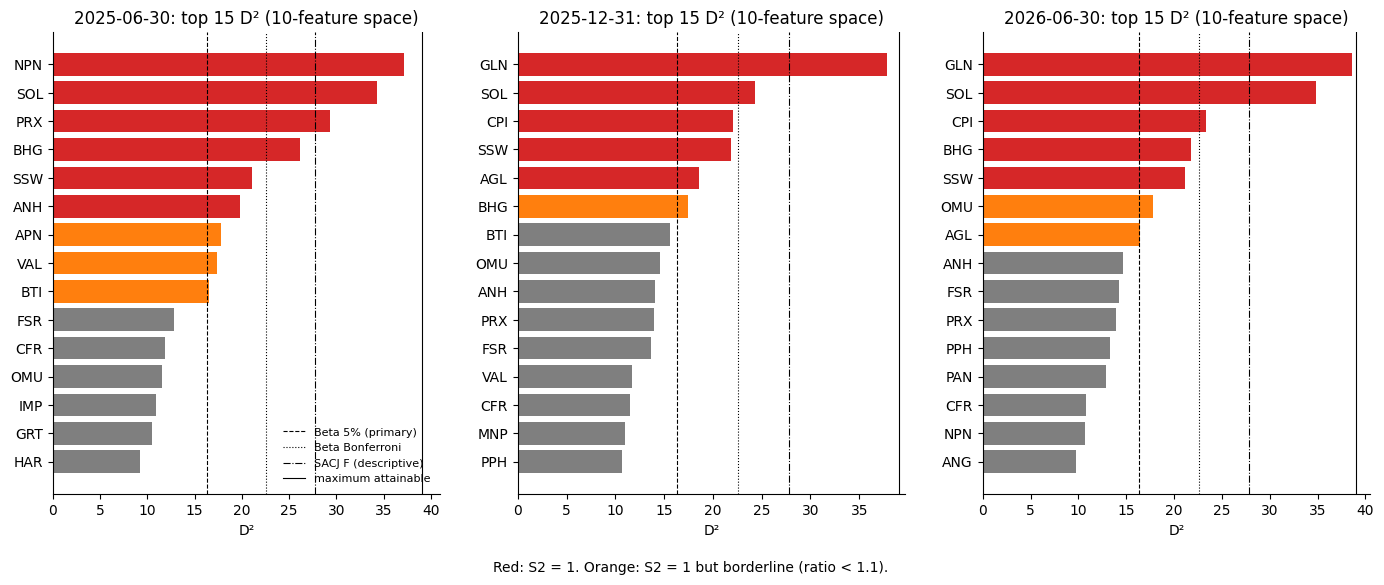

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, d in zip(axes, DATES):
    s = s2[s2.date == d].sort_values('D2', ascending=False).head(15)[::-1]
    ax.barh(s.ticker, s.D2, color=np.where(s.S2 == 1, np.where(s.borderline, 'tab:orange', 'tab:red'), 'tab:grey'))
    for v, name, style in [(s.reference.iat[0], 'Beta 5% (primary)', '--'), (beta_ref(len(snaps[d]), p0, 0.05 / len(snaps[d])), 'Beta Bonferroni', ':'),
                           (sacj_ref(len(snaps[d]), p0), 'SACJ F (descriptive)', '-.'), ((len(snaps[d]) - 1) ** 2 / len(snaps[d]), 'maximum attainable', '-')]:
        ax.axvline(v, ls=style, color='black', lw=0.8, label=name)
    ax.set_title(f'{d}: top 15 D² (10-feature space)'); ax.set_xlabel('D²')
axes[0].legend(frameon=False, fontsize=8, loc='lower right')
fig.text(0.5, -0.02, 'Red: S2 = 1. Orange: S2 = 1 but borderline (ratio < 1.1).', ha='center'); save(fig, 'signal_S2'); plt.show()

### 8.4 S2 sensitivity analyses
* **MCD (masking):** robust distances from `MinCovDet(random_state=42)` flagged above χ²₀.₉₅(p). MCD assumes one elliptical population,
  which a cross-sector universe need not be, so this is a sensitivity, not a confirmation.
* **Log-size space** (Section 3), **without INP** (one Investec line), and the **SACJ 2-D t-SNE map** version (SACJ F, flagged in ≥ 4 of 5 seeds; descriptive).

In [47]:
from sklearn.covariance import MinCovDet
rows = []
for d in DATES:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        mcd = MinCovDet(random_state=SEED).fit(X[d])
    rd = mcd.mahalanobis(X[d]); cut = stats.chi2.ppf(0.95, p0)
    rows += [dict(date=d, ticker=t, mcd_distance=rd[i], mcd_flag=int(rd[i] > cut), mcd_support=int(mcd.support_.sum()),
                  mcd_condition=np.linalg.cond(mcd.covariance_), mcd_warnings=len(caught)) for i, t in enumerate(snaps[d].ticker)]
mcd_tab = pd.DataFrame(rows)
log_tab = d2_table(X_LOG, 'log size')[['date', 'ticker', 'D2', 'S2']].rename(columns={'D2': 'D2_log', 'S2': 'S2_log'})
no_inp = {d: X[d][snaps[d].ticker.values != 'INP'] for d in DATES}
rows = []
for d in DATES:
    d2, _, _ = mahalanobis_sq(no_inp[d]); n = len(d2)
    rows += [dict(date=d, ticker=t, S2_without_INP=int(d2[i] > beta_ref(n, p0))) for i, t in enumerate(snaps[d].ticker[snaps[d].ticker != 'INP'])]
inp_tab = pd.DataFrame(rows)
rows = []
for d in DATES:
    flags = np.array([mahalanobis_sq(fitted['baseline', d, s][0])[0] > sacj_ref(len(snaps[d]), 2) for s in SEEDS])
    rows += [dict(date=d, ticker=t, tsne_map_flag_share=flags[:, i].mean()) for i, t in enumerate(snaps[d].ticker)]
map_tab = pd.DataFrame(rows)
s2_sens = s2[['date', 'ticker', 'D2', 'ratio', 'S2', 'borderline', 'bonferroni', 'sacj_F']]
for extra in (mcd_tab, log_tab, inp_tab, map_tab):
    s2_sens = s2_sens.merge(extra, on=['date', 'ticker'], how='left')
table(s2_sens, 'signals_S2_sensitivity', index=False)
print('MCD support size, condition number and warnings:', mcd_tab.groupby('date')[['mcd_support', 'mcd_condition', 'mcd_warnings']].first().round(0).to_dict('index'))
flag_cols = ['S2', 'bonferroni', 'sacj_F', 'mcd_flag', 'S2_log', 'S2_without_INP']
display(table(s2_sens.groupby('date')[flag_cols].sum().assign(tsne_map_4of5=s2_sens.groupby('date').tsne_map_flag_share.apply(lambda v: int((v >= 0.8).sum()))),
              'signal_counts_S2_sensitivity'))
any_flag = s2_sens[s2_sens[flag_cols].fillna(0).sum(axis=1) > 0]
with pd.option_context('display.max_rows', 80):
    display(any_flag.sort_values(['date', 'D2'], ascending=[True, False]).round(2))

MCD support size, condition number and warnings: {'2025-06-30': {'mcd_support': 26, 'mcd_condition': 3672.0, 'mcd_warnings': 0}, '2025-12-31': {'mcd_support': 26, 'mcd_condition': 17277.0, 'mcd_warnings': 0}, '2026-06-30': {'mcd_support': 26, 'mcd_condition': 2965.0, 'mcd_warnings': 0}}


,S2,bonferroni,sacj_F,mcd_flag,S2_log,S2_without_INP,tsne_map_4of5
date,,,,,,,
2025-06-30,9,4,3,16,5,8.0,0
2025-12-31,6,2,1,16,6,6.0,0
2026-06-30,7,3,2,16,5,6.0,0


,date,ticker,D2,ratio,S2,borderline,bonferroni,sacj_F,mcd_distance,mcd_flag,mcd_support,mcd_condition,mcd_warnings,D2_log,S2_log,S2_without_INP,tsne_map_flag_share
25,2025-06-30,NPN,37.13,2.27,1,False,1,1,12309.91,1,26,3671.62,0,36.93,1,1.0,0.0
36,2025-06-30,SOL,34.32,2.10,1,False,1,1,582.87,1,26,3671.62,0,33.66,1,1.0,0.0
30,2025-06-30,PRX,29.29,1.79,1,False,1,1,1627.26,1,26,3671.62,0,13.59,0,1.0,0.0
5,2025-06-30,BHG,26.14,1.60,1,False,1,0,1042.20,1,26,3671.62,0,15.82,0,1.0,0.0
37,2025-06-30,SSW,21.05,1.29,1,False,0,0,120.44,1,26,3671.62,0,11.38,0,1.0,0.0
3,2025-06-30,ANH,19.78,1.21,1,False,0,0,1604.61,1,26,3671.62,0,9.43,0,1.0,0.0
4,2025-06-30,APN,17.75,1.09,1,True,0,0,36.53,1,26,3671.62,0,17.88,1,1.0,0.0
38,2025-06-30,VAL,17.38,1.06,1,True,0,0,54.09,1,26,3671.62,0,20.13,1,1.0,0.0
7,2025-06-30,BTI,16.55,1.01,1,True,0,0,849.01,1,26,3671.62,0,16.85,1,0.0,0.0
13,2025-06-30,FSR,12.77,0.78,0,False,0,0,74.80,1,26,3671.62,0,14.85,0,0.0,0.0


### 8.5 Why is each S2 firm extreme? (D² decomposition)
D² = Σₖ cₖ(S⁻¹c)ₖ, where c is the firm's deviation from the mean. Terms are **signed** and conditional on the correlations,
so they are not independent feature importances. Section 10 adds the SHAP view.

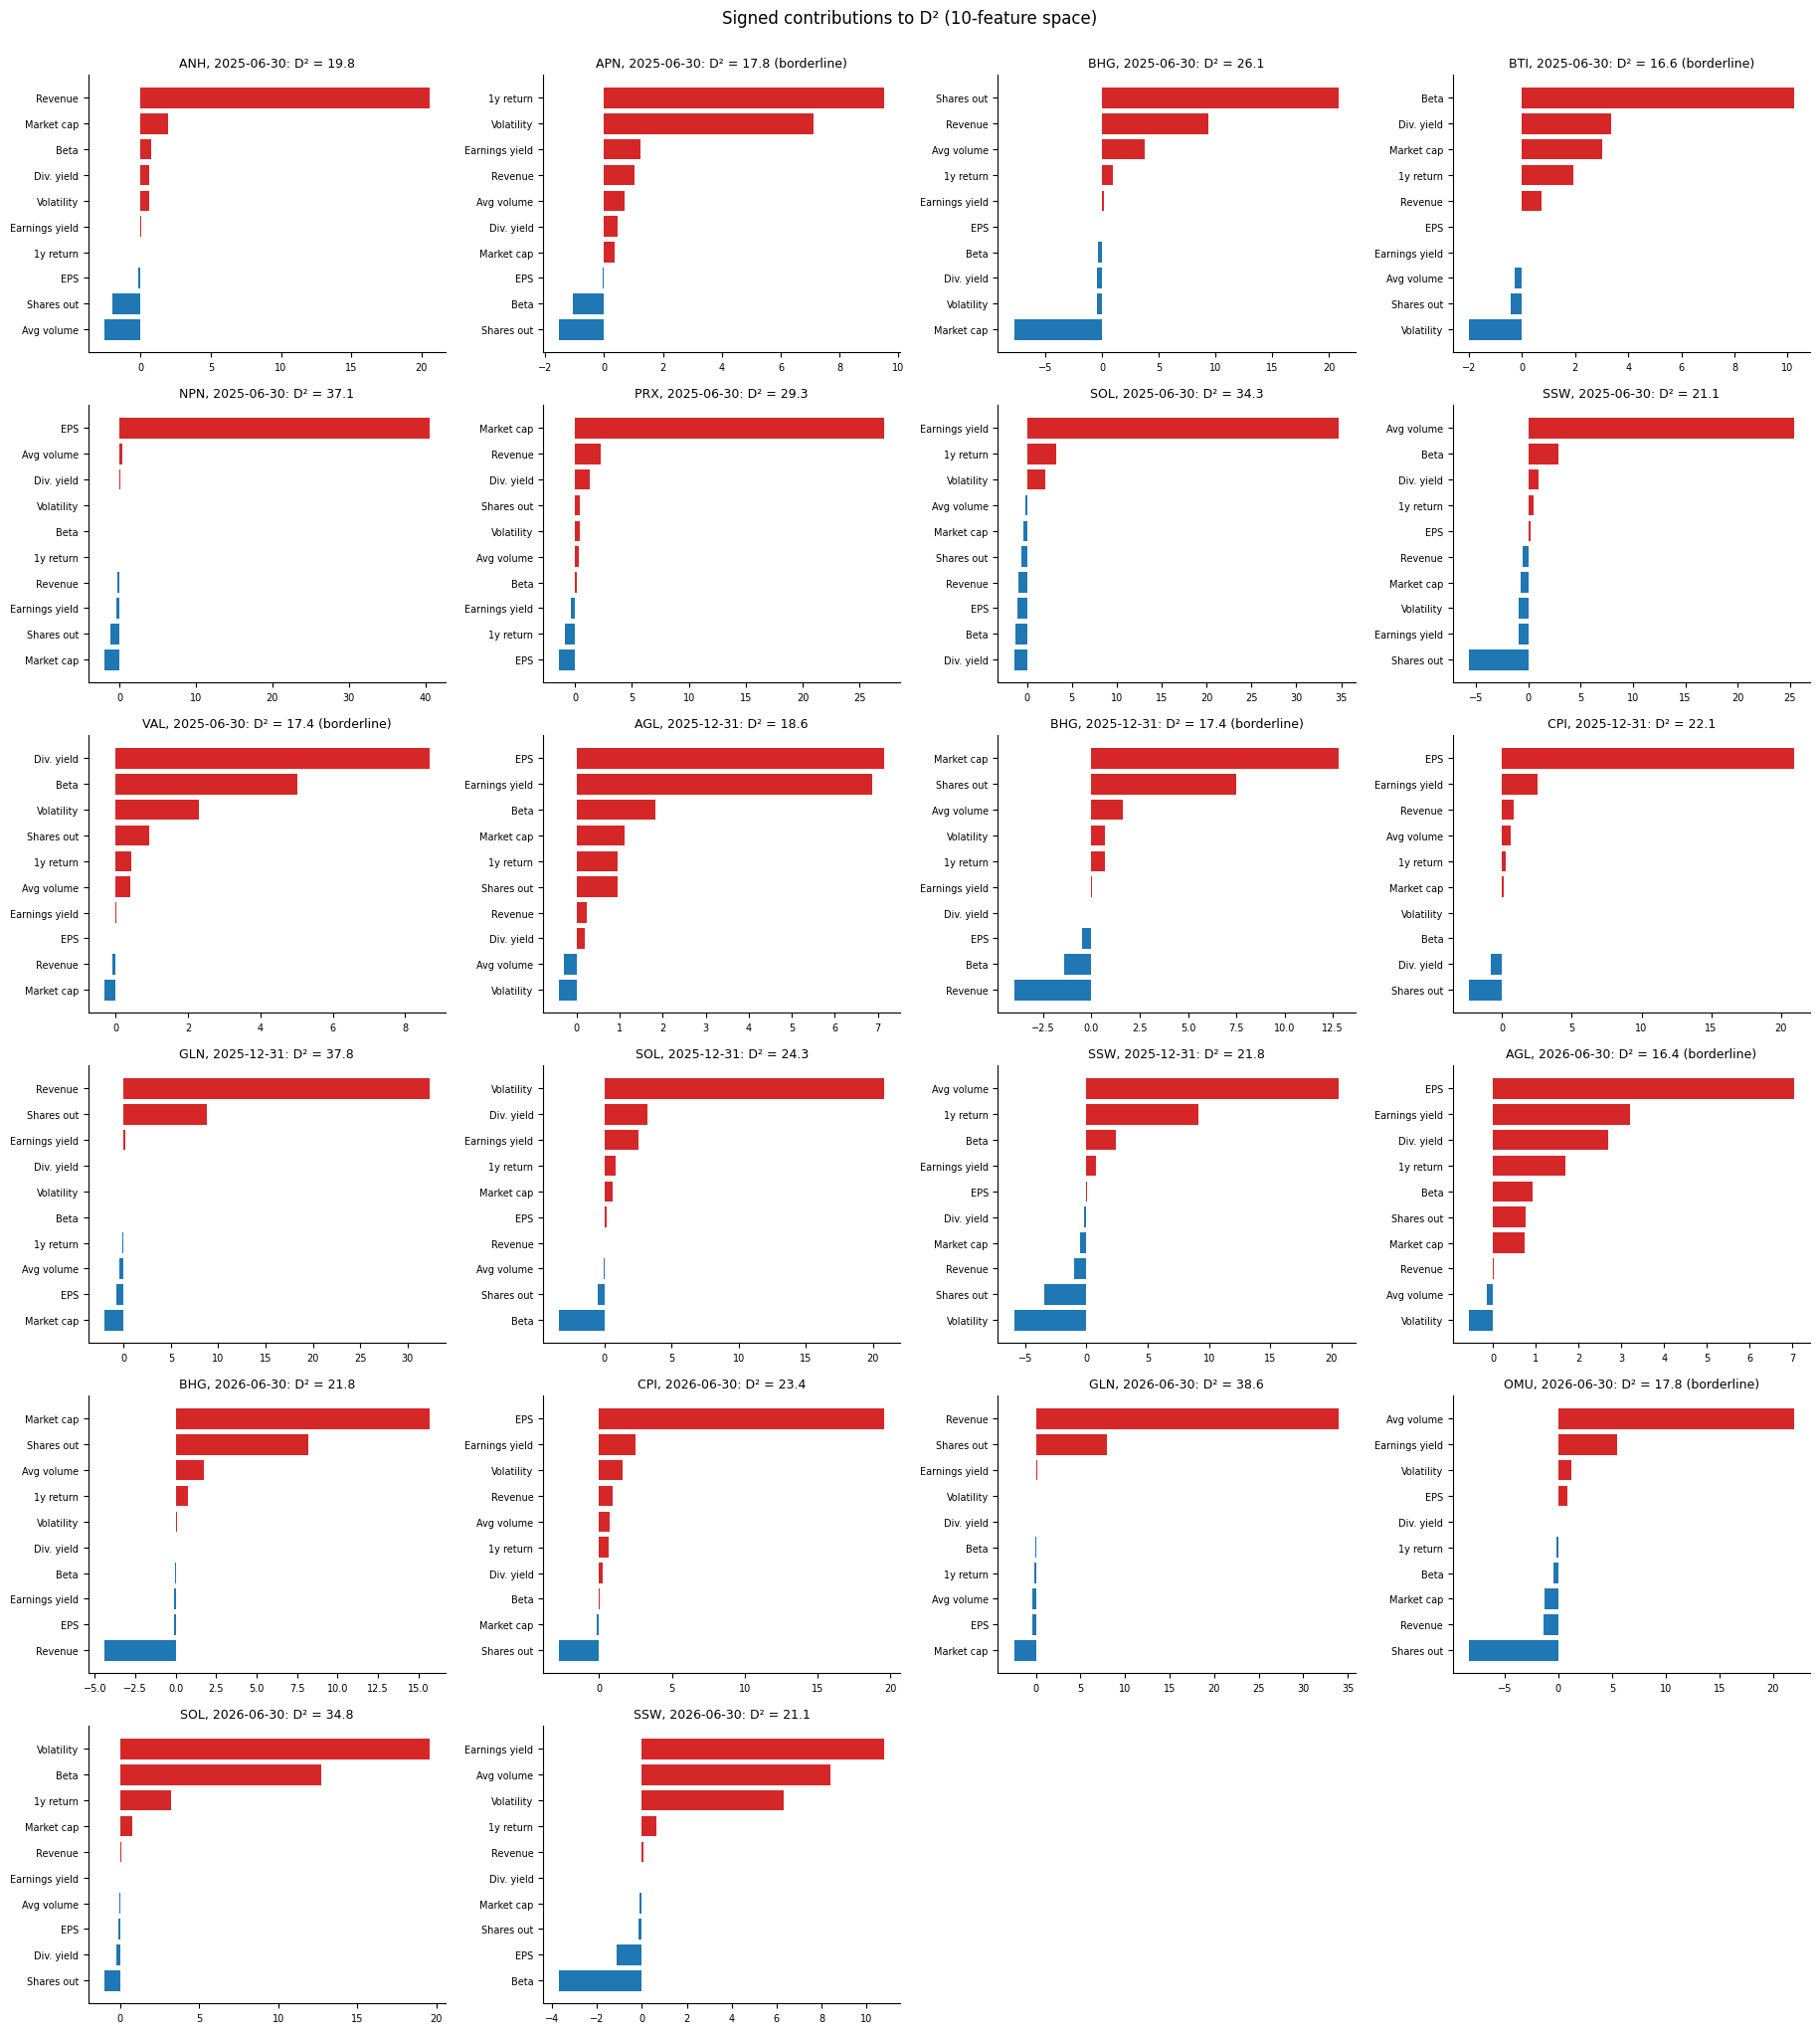

In [48]:
def d2_contributions(x):
    c = x - x.mean(axis=0)
    return c * (c @ np.linalg.inv(np.cov(x, rowvar=False)))       # rows sum to D²

rows = []
for d in DATES:
    contrib = d2_contributions(X[d])
    for i, t in enumerate(snaps[d].ticker):
        r = s2[(s2.date == d) & (s2.ticker == t)].iloc[0]
        if r.S2 == 1:
            assert np.isclose(contrib[i].sum(), r.D2)
            rows.append(dict(date=d, ticker=t, D2=r.D2, borderline=r.borderline, **dict(zip(NAMES, contrib[i]))))
d2_decomp = table(pd.DataFrame(rows), 'S2_decomposition', index=False)
n = len(d2_decomp); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.4 * nrow), squeeze=False)
for ax, (_, r) in zip(axes.flat, d2_decomp.iterrows()):
    v = r[NAMES].astype(float).sort_values()
    ax.barh(v.index, v.values, color=np.where(v.values > 0, 'tab:red', 'tab:blue'))
    ax.set_title(f'{r.ticker}, {r.date}: D² = {r.D2:.1f}' + (' (borderline)' if r.borderline else ''), fontsize=9); ax.tick_params(labelsize=7)
for ax in axes.flat[n:]:
    ax.axis('off')
fig.suptitle('Signed contributions to D² (10-feature space)', y=1.0); fig.tight_layout(); save(fig, 'S2_decomposition'); plt.show()

### 8.6 Combined signals
S∨ = 1 if any applicable signal is 1; 0 if all applicable signals are 0; NA if none applies.
**Multi-signal** = two or more signals equal 1 at the same date. Agreement is stronger screening evidence, not independent confirmation.

In [49]:
signals = s13.merge(s2[['date', 'ticker', 'S2', 'ratio', 'borderline']], on=['date', 'ticker'])
def union(r):
    vals = [v for v in (r.S1, r.S2, r.S3) if pd.notna(v)]
    return np.nan if not vals else int(max(vals) == 1)
signals['S_any'] = signals.apply(union, axis=1)
signals['applicable'] = signals[['S1', 'S2', 'S3']].notna().sum(axis=1)
signals['n_signals'] = (signals[['S1', 'S2', 'S3']] == 1).sum(axis=1)
signals['multi_signal'] = signals.n_signals >= 2
table(signals, 'signals_all', index=False)
display(table(signals.groupby(['model', 'date']).agg(S1=('S1', lambda s: int((s == 1).sum())), S2=('S2', 'sum'), S3=('S3', 'sum'),
                                                     S_any=('S_any', lambda s: int((s == 1).sum())), multi_signal=('multi_signal', 'sum')), 'signal_counts'))
print('Multi-signal firms, main model:')
signals[(signals.model == MAIN) & signals.multi_signal][['date', 'ticker', 'sector', 'S1', 'S2', 'S3', 'ratio', 'borderline']].round(2)

S1  S2  S3  S_any  multi_signal
model    date                                       
baseline 2025-06-30   4   9   0     10             3
         2025-12-31   6   6   0     12             0
         2026-06-30   4   7   0     11             0
tuned    2025-06-30   8   9   1     15             3
         2025-12-31   6   6   2     11             3
         2026-06-30   4   7   3     11             3

Multi-signal firms, main model:


,date,ticker,sector,S1,S2,S3,ratio,borderline
127,2025-06-30,APN,Health Care,1.0,1,0,1.09,True
128,2025-06-30,BHG,Basic Materials,1.0,1,0,1.60,False
159,2025-06-30,SOL,Basic Materials,NaN,1,1,2.10,False
168,2025-12-31,BHG,Basic Materials,1.0,1,0,1.07,True
178,2025-12-31,GLN,Basic Materials,NaN,1,1,2.31,False
201,2025-12-31,SSW,Basic Materials,NaN,1,1,1.34,False
219,2026-06-30,GLN,Basic Materials,NaN,1,1,2.36,False
241,2026-06-30,SOL,Basic Materials,NaN,1,1,2.13,False
242,2026-06-30,SSW,Basic Materials,NaN,1,1,1.29,False


## 9. Anomaly-dynamics taxonomy (protocol Section 9)
For firms with a **defined** state at all three dates (N = 0, A = 1). Firms absent at a date are *partial history*;
firms with an NA state are *undefined state*. Peer-group moves are shown alongside but never define the class.

Adjacent dates share six months of market data and often the same annual accounts, so adjacent-date persistence is partly mechanical.
Firms in state A at both June 2025 and June 2026 (non-overlapping return windows) are reported separately as **less mechanically overlapping evidence**.

In [50]:
PATTERN = {'NNN': 'No signal', 'NNA': 'Emerging', 'NAA': 'Emerging and sustained', 'AAA': 'Persistent',
           'AAN': 'Resolving', 'ANN': 'Resolved', 'NAN': 'Transient', 'ANA': 'Recurrent'}
SIGNALS = ['S1', 'S2', 'S3', 'S_any']

def taxonomy(m):
    sig = signals[signals.model == m]
    rows = []
    for t in sorted(set(sig.ticker)):
        st = sig[sig.ticker == t].set_index('date')
        r = dict(ticker=t, sector=info.loc[t, 'sector_label'], imputation_sensitive=t in IMPUTED)
        for s in SIGNALS:
            vals = [st[s].get(d, None) if d in st.index else None for d in DATES]
            r[f'{s}_states'] = ''.join('·' if v is None else ('?' if pd.isna(v) else ('A' if v == 1 else 'N')) for v in vals)
            if any(d not in st.index for d in DATES):
                r[s] = 'partial history'
            elif any(pd.isna(v) for v in vals):
                r[s] = 'undefined state'
            else:
                r[s] = PATTERN[r[f'{s}_states']]
        r['S2_borderline_dates'] = ', '.join(d for d in DATES if d in st.index and st.borderline.get(d, False) and st.S2.get(d) == 1)
        r['robust_moves'] = ', '.join(f'{tr}' for tr in moves[(moves.model == m) & (moves.ticker == t) & (moves.status == 'robust move')].transition)
        rows.append(r)
    return pd.DataFrame(rows)

tax = {m: table(taxonomy(m), f'taxonomy_{m}', index=False) for m in MODELS}
order = list(PATTERN.values()) + ['undefined state', 'partial history']
display(table(pd.concat({m: pd.DataFrame({s: tax[m][s].value_counts() for s in SIGNALS}).reindex(order).fillna(0).astype(int) for m in MODELS}, axis=1),
              'taxonomy_counts'))

baseline               tuned              
                             S1  S2  S3 S_any    S1  S2  S3 S_any
No signal                    30  28  39    23    28  28  37    22
Emerging                      1   1   0     2     1   1   0     2
Emerging and sustained        2   2   0     4     0   2   1     1
Persistent                    1   3   0     4     2   3   0     6
Resolving                     0   0   0     1     1   0   0     1
Resolved                      3   5   0     4     2   5   0     5
Transient                     2   0   0     1     2   0   0     1
Recurrent                     0   0   0     0     1   0   1     1
undefined state               0   0   0     0     2   0   0     0
partial history               4   4   4     4     4   4   4     4

In [51]:
t_main = tax[MAIN]
interesting = t_main[(t_main[SIGNALS] != 'No signal').any(axis=1) & ~(t_main[SIGNALS] == 'partial history').all(axis=1)]
cols = ['ticker', 'sector'] + [c for s in SIGNALS for c in (s, f'{s}_states')] + ['S2_borderline_dates', 'robust_moves', 'imputation_sensitive']
print('Firms with any signal (main model). States: A = signal, N = none, ? = NA, · = not in index.')
with pd.option_context('display.max_rows', 60, 'display.max_colwidth', 40):
    display(interesting[cols])
endpoint = t_main[t_main.S_any_states.str[0].eq('A') & t_main.S_any_states.str[2].eq('A')]
print('A at both June 2025 and June 2026 (less mechanically overlapping evidence):', ', '.join(endpoint.ticker) or 'none')

Firms with any signal (main model). States: A = signal, N = none, ? = NA, · = not in index.


,ticker,sector,S1,S1_states,S2,S2_states,S3,S3_states,S_any,S_any_states,S2_borderline_dates,robust_moves,imputation_sensitive
1,AGL,Basic Materials,Resolved,ANN,Emerging and sustained,NAA,No signal,NNN,Persistent,AAA,2026-06-30,2025-06-30 → 2025-12-31,True
3,ANH,Consumer Goods,No signal,NNN,Resolved,ANN,No signal,NNN,Resolved,ANN,,,False
5,BHG,Basic Materials,Resolving,AAN,Persistent,AAA,No signal,NNN,Persistent,AAA,2025-12-31,,False
7,BTI,Consumer Goods,No signal,NNN,Resolved,ANN,No signal,NNN,Resolved,ANN,2025-06-30,,False
8,BVT,Industrials,Recurrent,ANA,No signal,NNN,No signal,NNN,Recurrent,ANA,,,False
11,CPI,Financials,No signal,NNN,Emerging and sustained,NAA,No signal,NNN,Emerging and sustained,NAA,,,False
22,MRP,Consumer Services,Transient,NAN,No signal,NNN,No signal,NNN,Transient,NAN,,,False
23,MTN,Telecommunications,Resolved,ANN,No signal,NNN,No signal,NNN,Resolved,ANN,,"2025-06-30 → 2025-12-31, 2025-06-30 ...",False
26,NPN,Technology,No signal,NNN,Resolved,ANN,No signal,NNN,Resolved,ANN,,2025-06-30 → 2025-12-31,False
28,OMU,Financials,No signal,NNN,Emerging,NNA,No signal,NNN,Emerging,NNA,2026-06-30,,False


A at both June 2025 and June 2026 (less mechanically overlapping evidence): AGL, BHG, BVT, PPH, SOL, SSW, VOD


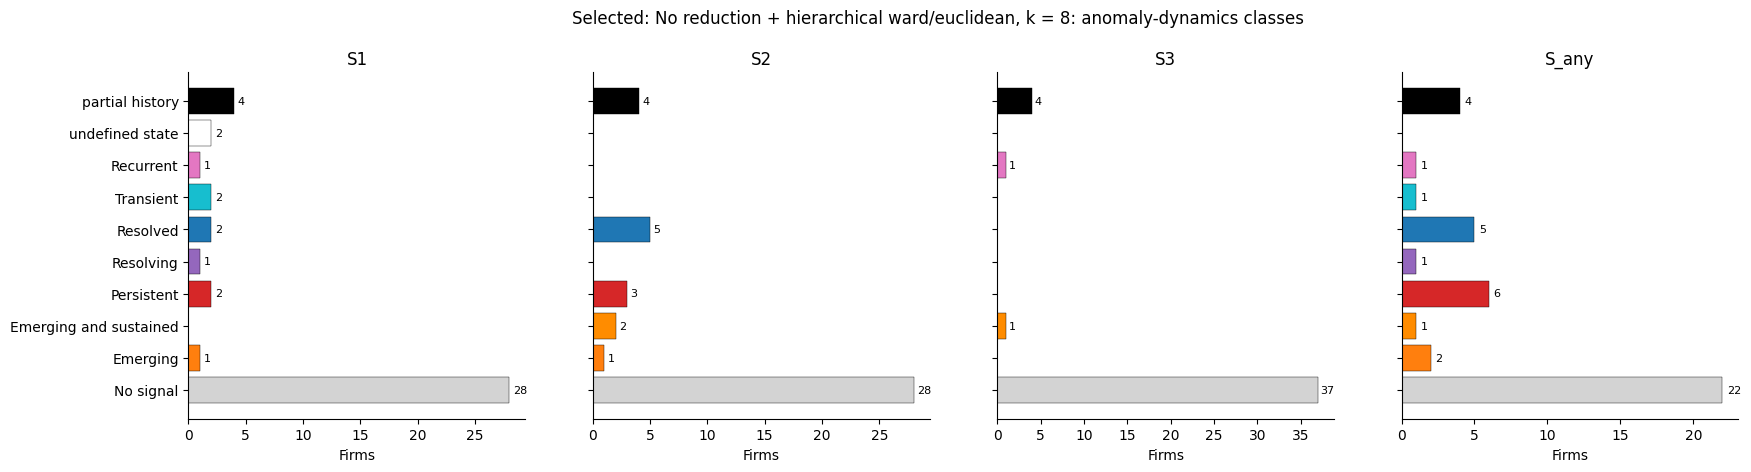

In [52]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
colour_map = {'No signal': 'lightgrey', 'Emerging': 'tab:orange', 'Emerging and sustained': 'darkorange', 'Persistent': 'tab:red',
              'Resolving': 'tab:purple', 'Resolved': 'tab:blue', 'Transient': 'tab:cyan', 'Recurrent': 'tab:pink',
              'undefined state': 'white', 'partial history': 'black'}
for ax, s in zip(axes, SIGNALS):
    c = t_main[s].value_counts().reindex(order).fillna(0)
    ax.barh(range(len(c)), c.values, color=[colour_map[k] for k in c.index], edgecolor='black', lw=0.3)
    ax.set_yticks(range(len(c)), c.index); ax.set_title(s); ax.set_xlabel('Firms')
    for i, v in enumerate(c.values):
        if v:
            ax.text(v + 0.3, i, int(v), va='center', fontsize=8)
fig.suptitle(f"{MODELS[MAIN]['name']}: anomaly-dynamics classes", y=1.02); save(fig, 'taxonomy_counts'); plt.show()

## 10. SHAP explanations (protocol Section 10)
SHAP explains a **surrogate**: an XGBoost classifier (fixed settings, as in the archived runs) trained on the ten raw features to predict
that date's cluster labels of the main model. It explains *what separates the clusters*, not the clustering algorithm itself,
and it is not causal. Fidelity: in-sample accuracy, stratified out-of-fold (OOF) accuracy, and OOF without singleton clusters.
Attributions at a date carry a **weak-fidelity** warning if OOF without singletons is below 0.60 (or not estimable). Additivity is checked for every explanation.

In [53]:
import shap
from xgboost import XGBClassifier

def oof_accuracy(x, y):
    smallest = np.bincount(y).min()
    if smallest < 2:
        return None
    model = XGBClassifier(**A.SPEC['surrogate'], random_state=SEED)
    cv = StratifiedKFold(n_splits=min(5, smallest), shuffle=True, random_state=SEED)
    return accuracy_score(y, cross_val_predict(model, x, y, cv=cv))

def surrogate(frame, labels):
    x = frame[FEATURES].to_numpy(dtype=float)
    classes, y = np.unique(labels, return_inverse=True)          # cluster label <-> surrogate class
    model = XGBClassifier(**A.SPEC['surrogate'], random_state=SEED).fit(x, y)
    explainer = shap.TreeExplainer(model)
    explanation = explainer(pd.DataFrame(x, columns=NAMES))
    assert explanation.values.shape == (len(frame), len(FEATURES), len(classes))
    assert np.allclose(explanation.values.sum(axis=1) + explanation.base_values, model.predict(x, output_margin=True), atol=1e-4)
    big = np.isin(y, np.flatnonzero(np.bincount(y) >= 2))
    oof_big = oof_accuracy(x[big], np.unique(y[big], return_inverse=True)[1]) if big.sum() > 2 else None
    return dict(model=model, explainer=explainer, classes=classes, y=y, x=x, explanation=explanation,
                in_sample=accuracy_score(y, model.predict(x)), oof=oof_accuracy(x, y), oof_without_singletons=oof_big,
                singletons=int((np.bincount(y) == 1).sum()))

sur = {d: surrogate(snaps[d], labels_of(MAIN, d).values) for d in DATES}
WEAK = {d: s['oof_without_singletons'] is None or s['oof_without_singletons'] < 0.60 for d, s in sur.items()}
fidelity = table(pd.DataFrame([dict(model=MAIN, date=d, clusters=len(s['classes']), singleton_clusters=s['singletons'],
                                    in_sample_accuracy=s['in_sample'], oof_accuracy=s['oof'],
                                    oof_accuracy_without_singletons=s['oof_without_singletons'], weak_fidelity_warning=WEAK[d])
                               for d, s in sur.items()]), 'surrogate_fidelity', index=False)
fidelity.fillna('not estimable (singleton cluster)')

,model,date,clusters,singleton_clusters,in_sample_accuracy,oof_accuracy,oof_accuracy_without_singletons,weak_fidelity_warning
0,tuned,2025-06-30,8,1,1.00000,not estimable (singleton cluster),0.600000,False
1,tuned,2025-12-31,8,2,1.00000,not estimable (singleton cluster),0.743590,False
2,tuned,2026-06-30,8,3,0.97561,not estimable (singleton cluster),0.789474,False


### 10.1 Global importance: which features separate the clusters overall

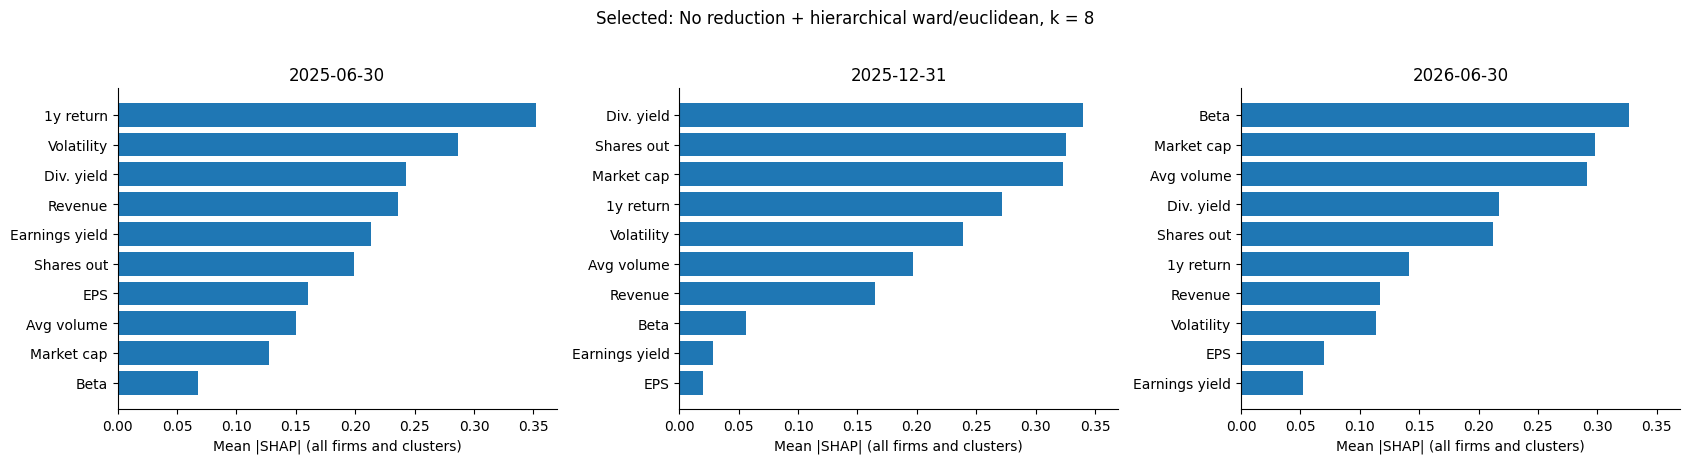

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True)
rows = []
for ax, d in zip(axes, DATES):
    imp = pd.Series(np.abs(sur[d]['explanation'].values).mean(axis=(0, 2)), index=NAMES).sort_values()
    ax.barh(imp.index, imp.values); ax.set_title(d + (' (weak fidelity)' if WEAK[d] else '')); ax.set_xlabel('Mean |SHAP| (all firms and clusters)')
    rows.append(imp.rename(d))
table(pd.concat(rows, axis=1).loc[NAMES], 'shap_global_importance')
fig.suptitle(MODELS[MAIN]['name'], y=1.02); fig.tight_layout(); save(fig, 'shap_global'); plt.show()

### 10.2 Cluster-level importance
For each cluster: the mean |SHAP| of each feature for that cluster's own members, then beeswarm plots. Singleton clusters are marked: one firm cannot support a subgroup explanation.

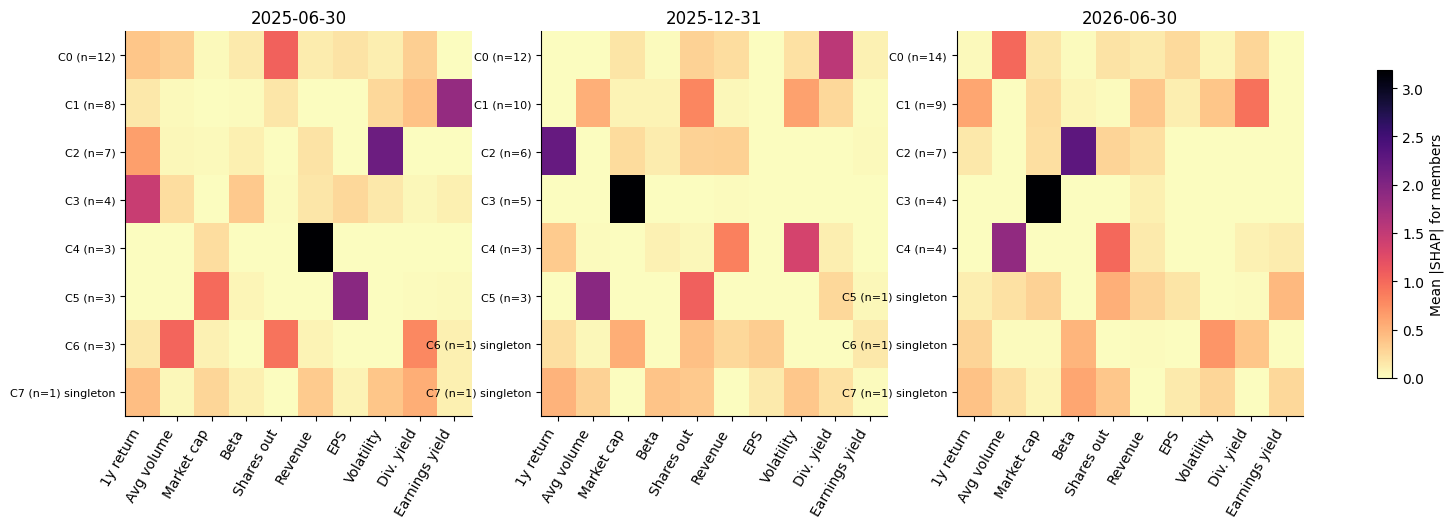

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
rows = []
for ax, d in zip(axes, DATES):
    s = sur[d]; vals = s['explanation'].values
    heat = pd.DataFrame([np.abs(vals[s['y'] == c, :, c]).mean(axis=0) for c in range(len(s['classes']))], columns=NAMES)
    sizes = np.bincount(s['y'])
    heat.index = [f'C{lab} (n={n}){" singleton" if n == 1 else ""}' for lab, n in zip(s['classes'], sizes)]
    rows.append(heat.assign(date=d))
    im = ax.imshow(heat, cmap='magma_r', aspect='auto')
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=60, ha='right'); ax.set_yticks(range(len(heat)), heat.index, fontsize=8)
    ax.set_title(d)
fig.colorbar(im, ax=axes, shrink=0.8, label='Mean |SHAP| for members')
table(pd.concat(rows), 'shap_cluster_importance'); save(fig, 'shap_cluster_heatmap'); plt.show()

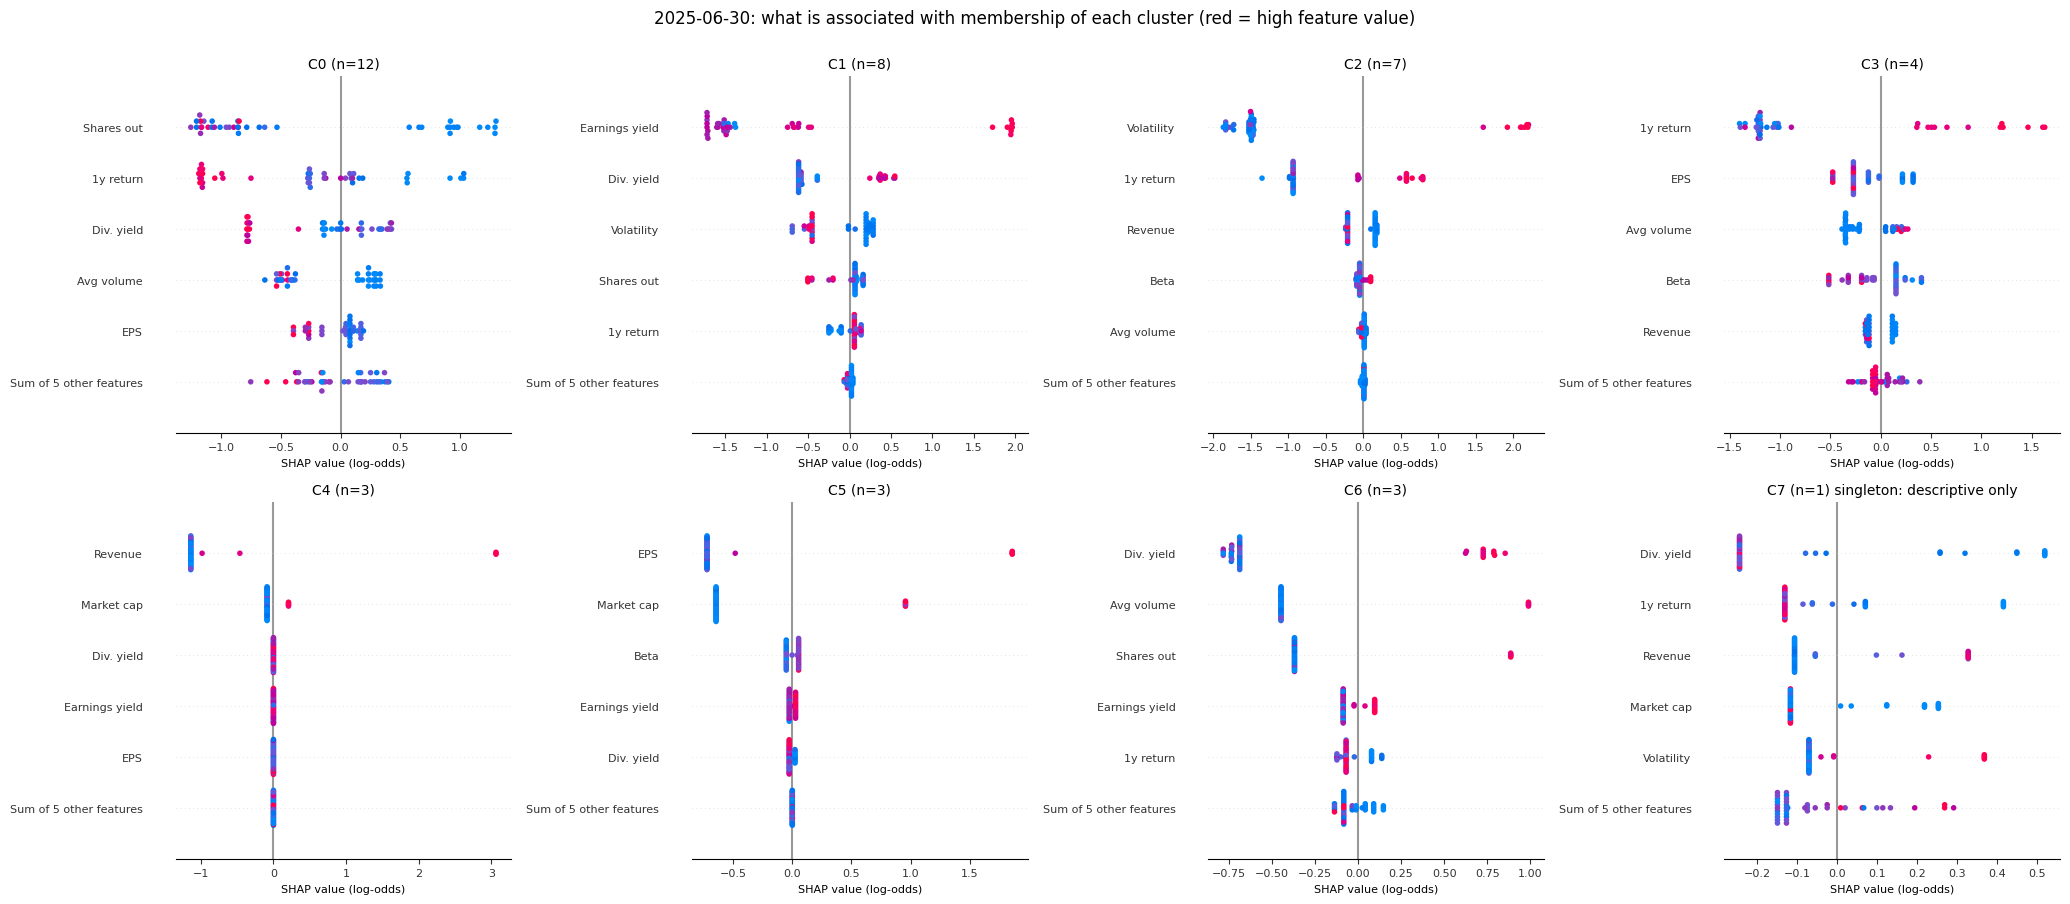

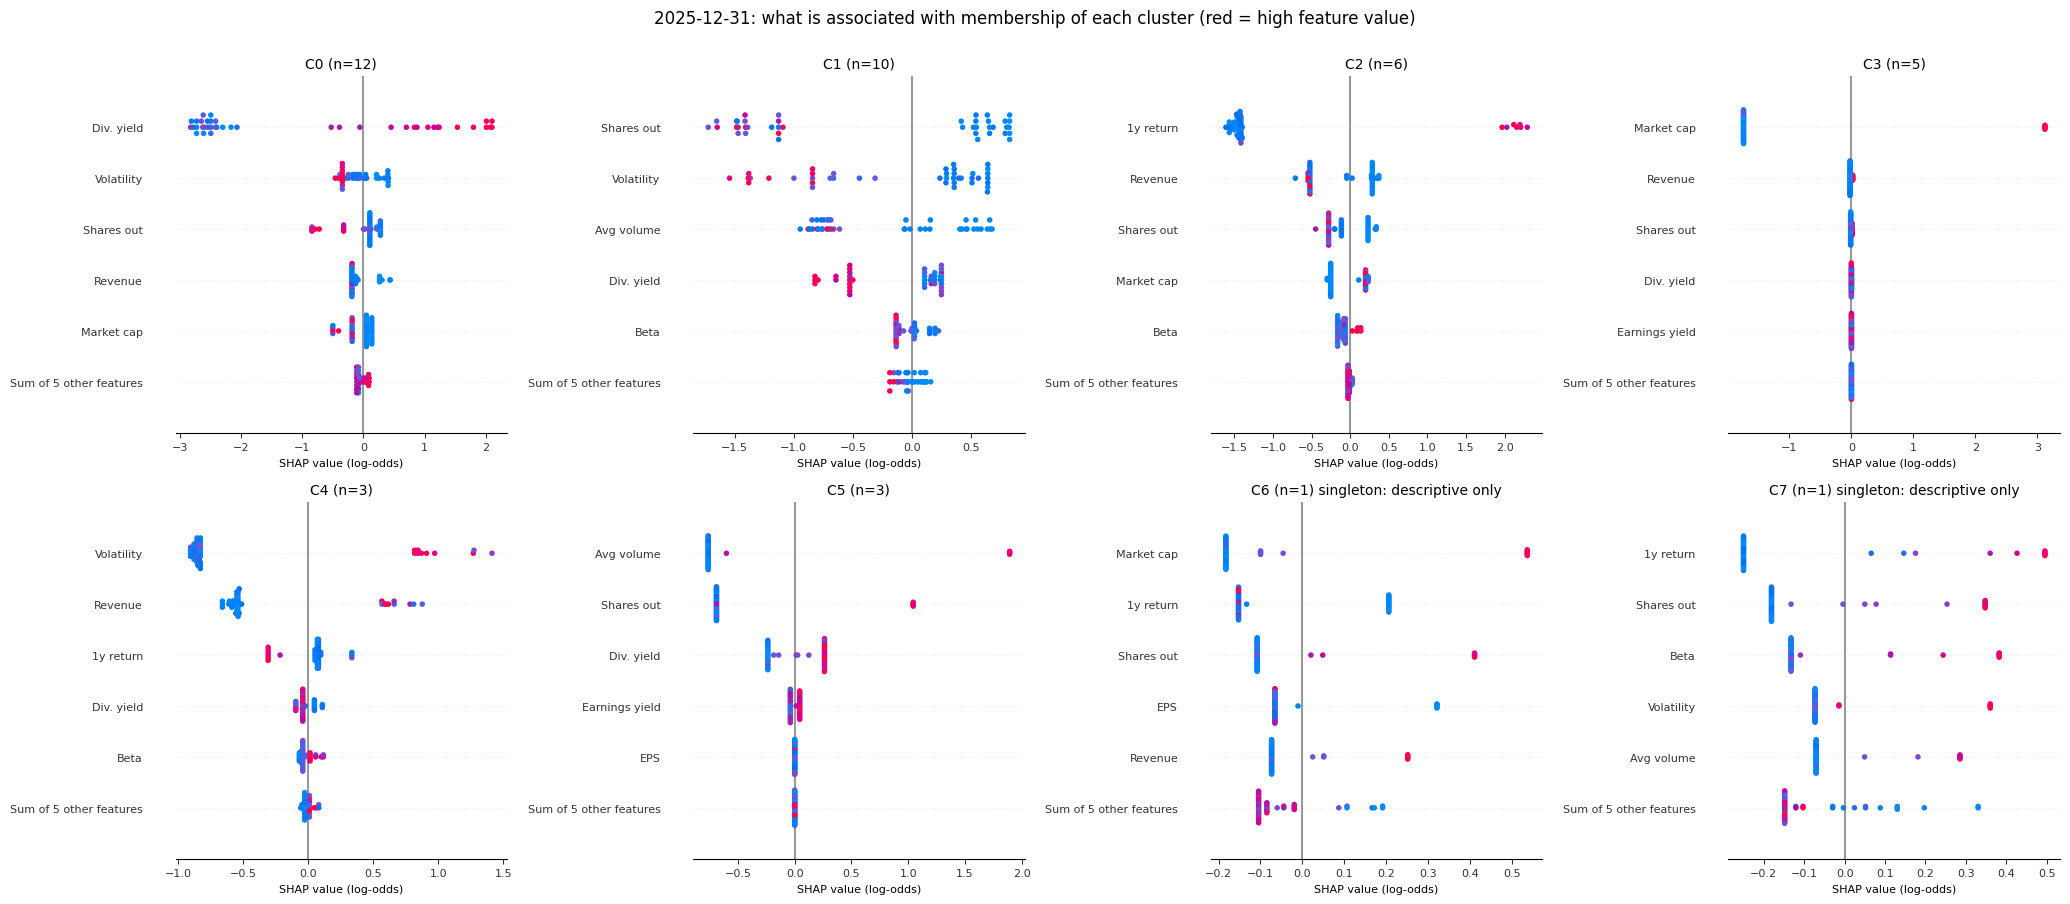

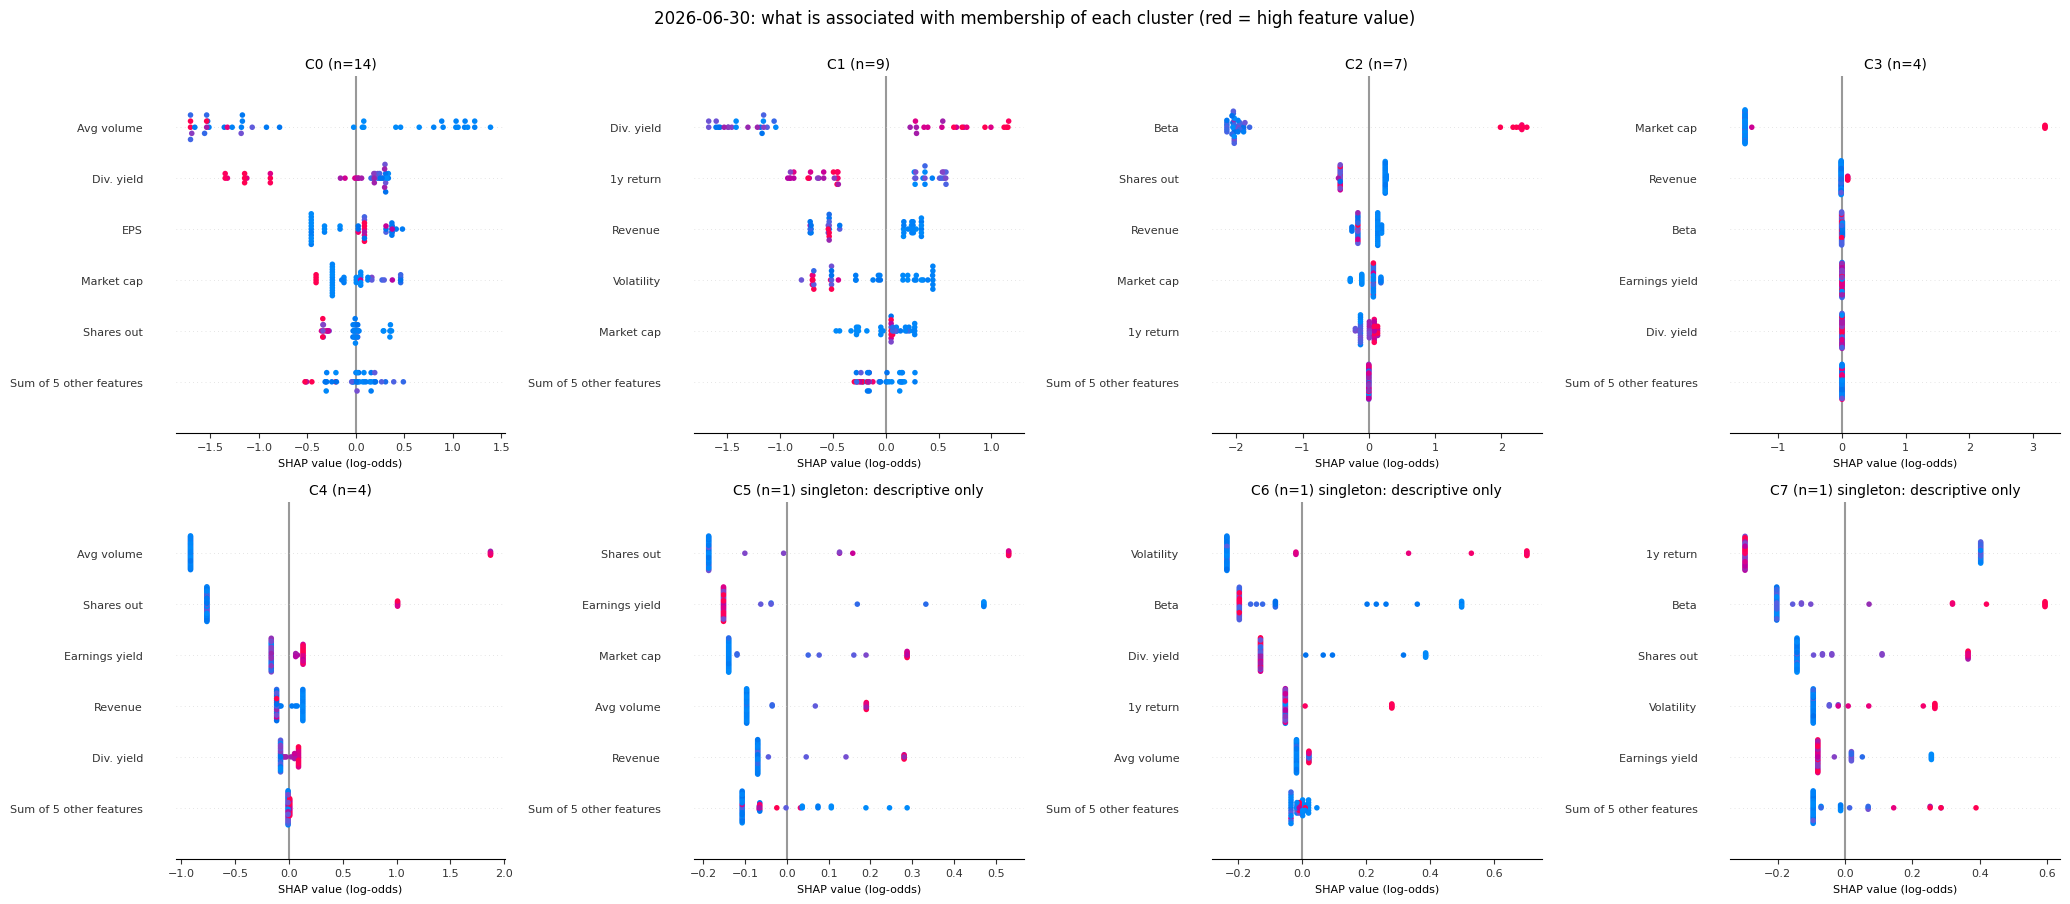

In [56]:
for d in DATES:
    s = sur[d]; n = len(s['classes'])
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(5.2 * ((n + 1) // 2), 9))
    for c, ax in zip(range(n), axes.flat):
        plt.sca(ax)
        shap.plots.beeswarm(s['explanation'][:, :, c], max_display=6, show=False, ax=ax, color_bar=False, plot_size=None)
        size = (s['y'] == c).sum()
        ax.set_title(f'C{s["classes"][c]} (n={size}){" singleton: descriptive only" if size == 1 else ""}', fontsize=10)
        ax.set_xlabel('SHAP value (log-odds)', fontsize=8); ax.tick_params(labelsize=8)
    for ax in axes.flat[n:]:
        ax.axis('off')
    fig.suptitle(f'{d}: what is associated with membership of each cluster (red = high feature value)', y=1.0)
    fig.tight_layout(); save(fig, f'shap_beeswarm_{d}'); plt.show()

### 10.3 What changed for robust movers and signalled firms, relative to June 2025?
The **June 2025 surrogate** is applied to each focus firm's June 2025 and later raw feature vectors (same feature definitions at both dates).

* **Focus firms:** every robust mover from June 2025, and every firm with S1, S2 or S3 = 1 at any date, if present in June 2025.
* **Reference destination** (in order): (1) the June 2025 cluster that is the accepted match of the firm's current cluster;
  (2) else the June 2025 cluster holding most of its current continuing peers (ties: lowest number); (3) if the firm is isolated, the cluster the
  June 2025 surrogate assigns its current profile to. The reference used is recorded.
* **ΔSHAP = SHAP(later) − SHAP(June 2025)**, towards the base cluster and towards the destination. Negative towards the base: attributes
  **associated with leaving** the 2025 group. Positive towards the destination: attributes **associated with joining** the new peers.
* **Range flag:** a later value outside the June 2025 min–max of that feature is an extrapolation the surrogate cannot support (direction of any bias unknown).

The v1 data have no native-currency amounts, so the split of each change into source and exchange-rate parts (protocol rule 4.6) is not available here.

In [57]:
ref = sur[DATES[0]]
cls = {lab: i for i, lab in enumerate(ref['classes'])}
base_lab = labels_of(MAIN, DATES[0])
robust_movers = set(moves[(moves.model == MAIN) & (moves.status == 'robust move') & moves.transition.str.startswith(DATES[0])].ticker)
signalled = set(signals[(signals.model == MAIN) & (signals.S_any == 1)].ticker)
focus = sorted((robust_movers | signalled) & members[DATES[0]])
lo, hi = snaps[DATES[0]][FEATURES].min(), snaps[DATES[0]][FEATURES].max()
x_then = snaps[DATES[0]].set_index('ticker')[FEATURES]
e_then = ref['explainer'](pd.DataFrame(x_then.to_numpy(float), columns=NAMES))
row_of = {t: i for i, t in enumerate(x_then.index)}

rows, deltas = [], {}
for later in DATES[1:]:
    cur = labels_of(MAIN, later)
    pairs, _ = FULL_MATCH[MAIN, DATES[0], later]
    inverse = {j: i for i, j in pairs.items()}
    x_now = snaps[later].set_index('ticker')[FEATURES]
    e_now = ref['explainer'](pd.DataFrame(x_now.to_numpy(float), columns=NAMES))
    pred_now = ref['classes'][ref['model'].predict(x_now.to_numpy(float))]
    for t in focus:
        if t not in x_now.index:
            continue
        i0, i1 = row_of[t], int(np.flatnonzero(x_now.index == t)[0])
        peers_now = [u for u in cur.index[(cur == cur[t]) & (cur.index != t)] if u in base_lab.index]
        if cur[t] in inverse:
            dest, how = inverse[cur[t]], 'accepted match'
        elif peers_now:
            counts = base_lab[peers_now].value_counts()
            dest, how = min(counts.index[counts == counts.max()]), 'most current peers'
        else:
            dest, how = pred_now[i1], 'isolated: surrogate assignment'
        c0, c1 = cls[base_lab[t]], cls[dest]
        d_from = pd.Series(e_now.values[i1, :, c0] - e_then.values[i0, :, c0], index=NAMES)
        d_to = pd.Series(e_now.values[i1, :, c1] - e_then.values[i0, :, c1], index=NAMES)
        out_of_range = [SHORT[f] for f in FEATURES if not lo[f] <= x_now.loc[t, f] <= hi[f]]
        deltas[later, t] = (d_from, d_to, base_lab[t], dest)
        sig = signals[(signals.model == MAIN) & (signals.ticker == t)]
        rows.append(dict(later_date=later, ticker=t, sector=info.loc[t, 'sector_label'],
                         why_in_focus=' + '.join(w for w, ok in [('robust move', t in robust_movers), ('S1', (sig.S1 == 1).any()),
                                                                  ('S2', (sig.S2 == 1).any()), ('S3', (sig.S3 == 1).any())] if ok),
                         base_cluster_2025=base_lab[t], current_cluster=cur[t], destination_2025_cluster=dest, destination_reference=how,
                         associated_with_leaving_base=', '.join(d_from.sort_values().index[:3]) if dest != base_lab[t] else '(same cluster)',
                         associated_with_joining_destination=', '.join(d_to.sort_values(ascending=False).index[:3]) if dest != base_lab[t] else '(same cluster)',
                         change_in_base_score=d_from.sum(), change_in_destination_score=d_to.sum(),
                         outside_training_range=', '.join(out_of_range), weak_fidelity_2025=WEAK[DATES[0]], imputation_sensitive=t in IMPUTED))
shift_shap = table(pd.DataFrame(rows), 'shap_shift_attribution', index=False)
with pd.option_context('display.max_colwidth', 60, 'display.max_rows', 100):
    display(shift_shap[shift_shap.later_date == DATES[-1]].round(2))

,later_date,ticker,sector,why_in_focus,base_cluster_2025,current_cluster,destination_2025_cluster,destination_reference,associated_with_leaving_base,associated_with_joining_destination,change_in_base_score,change_in_destination_score,outside_training_range,weak_fidelity_2025,imputation_sensitive
19,2026-06-30,AGL,Basic Materials,robust move + S1 + S2,0,0,0,accepted match,(same cluster),(same cluster),-3.12,-3.12,,False,True
20,2026-06-30,ANH,Consumer Goods,S2,4,3,4,accepted match,(same cluster),(same cluster),0.00,0.00,Market cap,False,False
21,2026-06-30,BHG,Basic Materials,S1 + S2,4,3,4,accepted match,(same cluster),(same cluster),0.00,0.00,Market cap,False,False
22,2026-06-30,BTI,Consumer Goods,S2,4,3,4,accepted match,(same cluster),(same cluster),-3.53,-3.53,Beta,False,False
23,2026-06-30,BVT,Industrials,S1,0,0,0,accepted match,(same cluster),(same cluster),-0.15,-0.15,,False,False
24,2026-06-30,CPI,Financials,S2,0,0,0,accepted match,(same cluster),(same cluster),-0.33,-0.33,,False,False
25,2026-06-30,MRP,Consumer Services,S1,0,0,0,accepted match,(same cluster),(same cluster),-1.41,-1.41,,False,False
26,2026-06-30,MTN,Telecommunications,robust move + S1,3,0,0,accepted match,"EPS, Earnings yield, Shares out","Beta, Avg volume, 1y return",0.35,0.17,,False,False
27,2026-06-30,NPN,Technology,robust move + S2,5,0,0,accepted match,"Market cap, Beta, Avg volume","1y return, Beta, Market cap",-1.71,1.22,,False,False
28,2026-06-30,OMU,Financials,S2,6,4,6,accepted match,(same cluster),(same cluster),-0.39,-0.39,Avg volume,False,False


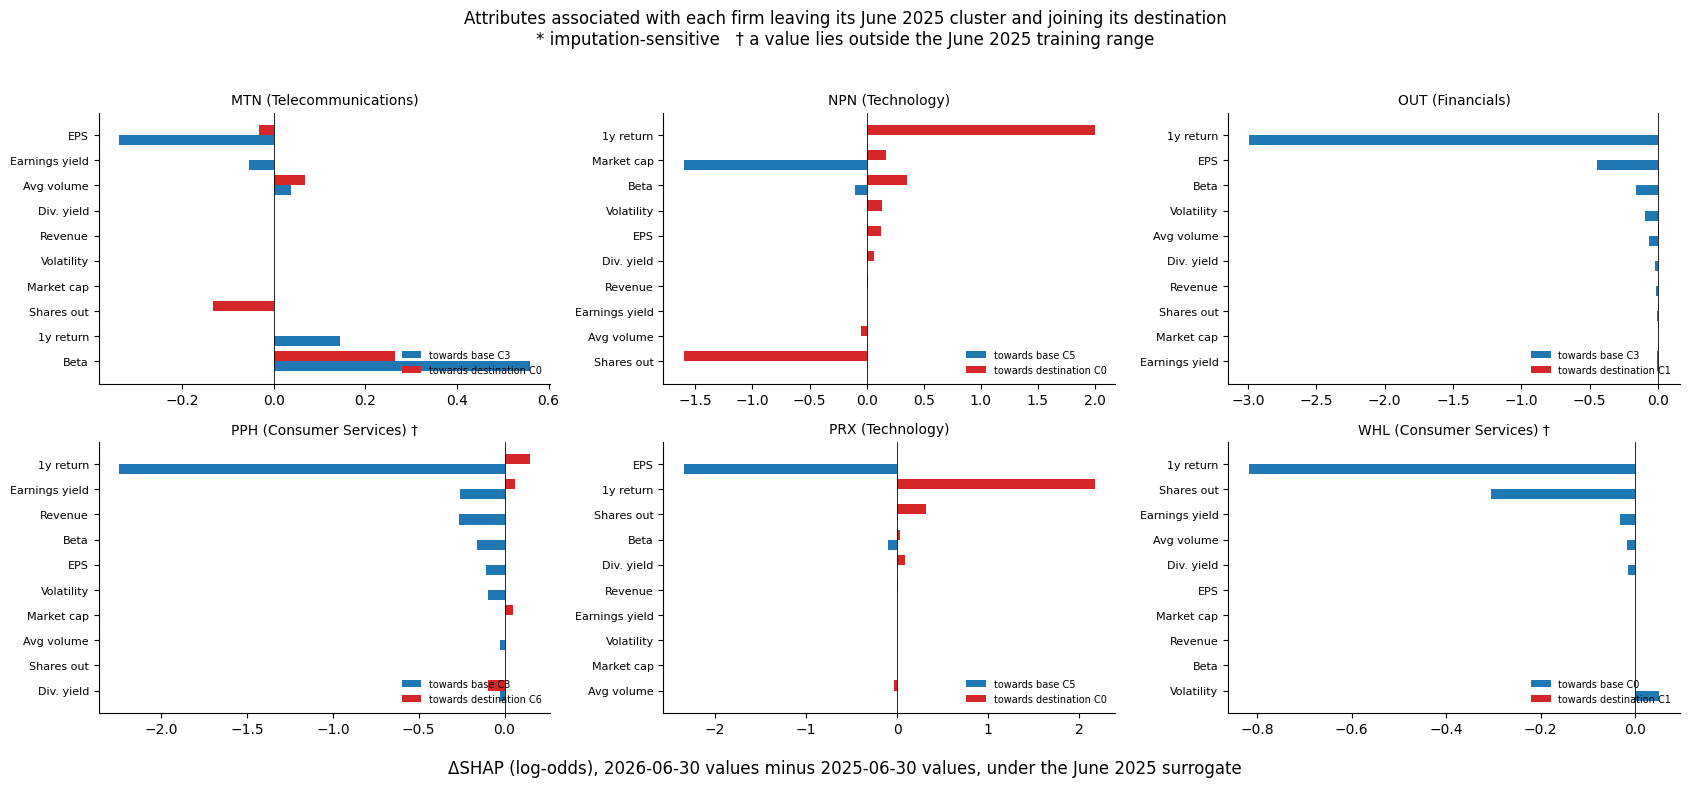

In [58]:
moved_now = [t for t in focus if (DATES[-1], t) in deltas and deltas[DATES[-1], t][2] != deltas[DATES[-1], t][3]]
if moved_now:
    ncol = 3; nrow = int(np.ceil(len(moved_now) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(17, 3.8 * nrow), squeeze=False)
    for ax, t in zip(axes.flat, moved_now):
        d_from, d_to, c0, c1 = deltas[DATES[-1], t]
        order_ = (d_to - d_from).sort_values().index
        pos = np.arange(len(order_))
        ax.barh(pos - 0.2, d_from[order_], 0.4, color='tab:blue', label=f'towards base C{c0}')
        ax.barh(pos + 0.2, d_to[order_], 0.4, color='tab:red', label=f'towards destination C{c1}')
        ax.axvline(0, color='black', lw=0.6); ax.set_yticks(pos, order_, fontsize=8)
        flag = shift_shap[(shift_shap.later_date == DATES[-1]) & (shift_shap.ticker == t)].outside_training_range.iat[0]
        ax.set_title(f'{t} ({info.loc[t, "sector_label"]})' + ('*' if t in IMPUTED else '') + (' †' if flag else ''), fontsize=10)
        ax.legend(frameon=False, fontsize=7, loc='lower right')
    for ax in axes.flat[len(moved_now):]:
        ax.axis('off')
    fig.supxlabel(f'ΔSHAP (log-odds), {DATES[-1]} values minus {DATES[0]} values, under the June 2025 surrogate')
    fig.suptitle('Attributes associated with each firm leaving its June 2025 cluster and joining its destination\n'
                 '* imputation-sensitive   † a value lies outside the June 2025 training range', y=1.02)
    fig.tight_layout(); save(fig, 'shap_shift_attribution'); plt.show()

In [59]:
# Raw feature changes for the focus firms (percentage change, June 2025 → June 2026), to read alongside the SHAP bars.
x_cur = snaps[DATES[-1]].set_index('ticker')[FEATURES]
keep = [t for t in focus if t in x_cur.index]
pct = ((x_cur.loc[keep] - x_then.loc[keep]) / x_then.loc[keep].abs().replace(0, np.nan) * 100).set_axis(NAMES, axis=1)
table(pct.round(1), 'focus_feature_changes_pct')

,1y return,Avg volume,Market cap,Beta,Shares out,Revenue,EPS,Volatility,Div. yield,Earnings yield
ticker,,,,,,,,,,
AGL,847.5,-31.8,54.5,-23.5,0.3,-37.4,-20.1,-1.9,-81.4,22.1
ANH,-16.0,-16.5,10.9,-145.3,-1.2,-8.6,9.1,10.0,2.4,-2.8
BHG,424.1,-9.1,58.8,-14.7,0.1,-15.2,5.0,11.6,-37.1,-33.8
BTI,-56.7,-19.9,19.9,-55.8,-1.3,-12.0,128.1,8.9,-39.3,87.7
BVT,114.2,-5.6,2.5,-49.8,0.0,3.3,-4.6,-7.7,0.8,-7.0
CPI,-3.7,-20.6,33.8,-45.2,0.0,19.0,22.4,-10.9,-8.4,-8.5
MRP,-349.7,24.7,-19.0,-46.3,-0.2,4.2,2.6,18.2,36.0,26.4
MTN,-6.1,5.2,64.1,-54.5,1.5,20.6,307.3,-8.1,-10.4,228.2
NPN,-146.9,210.9,-30.1,-30.0,370.0,39.1,-81.1,2.4,183.3,27.0


### 10.4 What separates S1 (sector-divergent) firms from their sector peers?
For each firm with S1 = 1, using that date's surrogate: SHAP(assigned cluster) − SHAP(the cluster holding most of its sector peers; ties: lowest number).
Positive = the feature is associated with the assigned cluster rather than the sector's cluster. The firm's value of the top features is shown next to its sector median.

,date,ticker,sector,assigned_cluster,sector_home_cluster,sector_peers_in_home,associated_with_assigned_cluster,top1: firm vs sector median,top2: firm vs sector median,weak_fidelity,imputation_sensitive
0,2025-06-30,AGL,Basic Materials,0.0,2,7 of 10,"1y return, Volatility, Div. yield",1y return: -0.0724 vs 0.457,Volatility: 0.358 vs 0.518,False,True
1,2025-06-30,APN,Health Care,NaN,none (only firm in its sector),NaN,NaN,NaN,NaN,False,False
2,2025-06-30,BHG,Basic Materials,4.0,2,7 of 10,"Revenue, Volatility, 1y return",Revenue: 9.9e+11 vs 1.09e+11,Volatility: 0.246 vs 0.518,False,False
3,2025-06-30,BVT,Industrials,NaN,none (only firm in its sector),NaN,NaN,NaN,NaN,False,False
4,2025-06-30,MNP,Basic Materials,0.0,2,7 of 10,"Volatility, 1y return, Shares out",Volatility: 0.255 vs 0.518,1y return: -0.173 vs 0.457,False,False
5,2025-06-30,MTN,Telecommunications,3.0,1,1 of 1,"Earnings yield, 1y return, Div. yield",Earnings yield: -0.0377 vs 0.0121,1y return: 0.658 vs 0.53,False,False
6,2025-06-30,PPH,Consumer Services,3.0,0,5 of 5,"1y return, Shares out, Avg volume",1y return: 0.454 vs 0.0763,Shares out: 3.69e+09 vs 4.39e+08,False,False
7,2025-06-30,VOD,Telecommunications,1.0,3,1 of 1,"1y return, Div. yield, Avg volume",1y return: 0.402 vs 0.53,Div. yield: 0.0454 vs 0.0349,False,False
8,2025-12-31,BHG,Basic Materials,3.0,2,6 of 11,"Market cap, 1y return, Revenue",Market cap: 2.57e+12 vs 3.04e+11,1y return: 0.102 vs 1.36,False,False
9,2025-12-31,MNP,Basic Materials,0.0,2,6 of 11,"Div. yield, 1y return, Market cap",Div. yield: 0.068 vs 0.0148,1y return: -0.266 vs 1.36,False,False


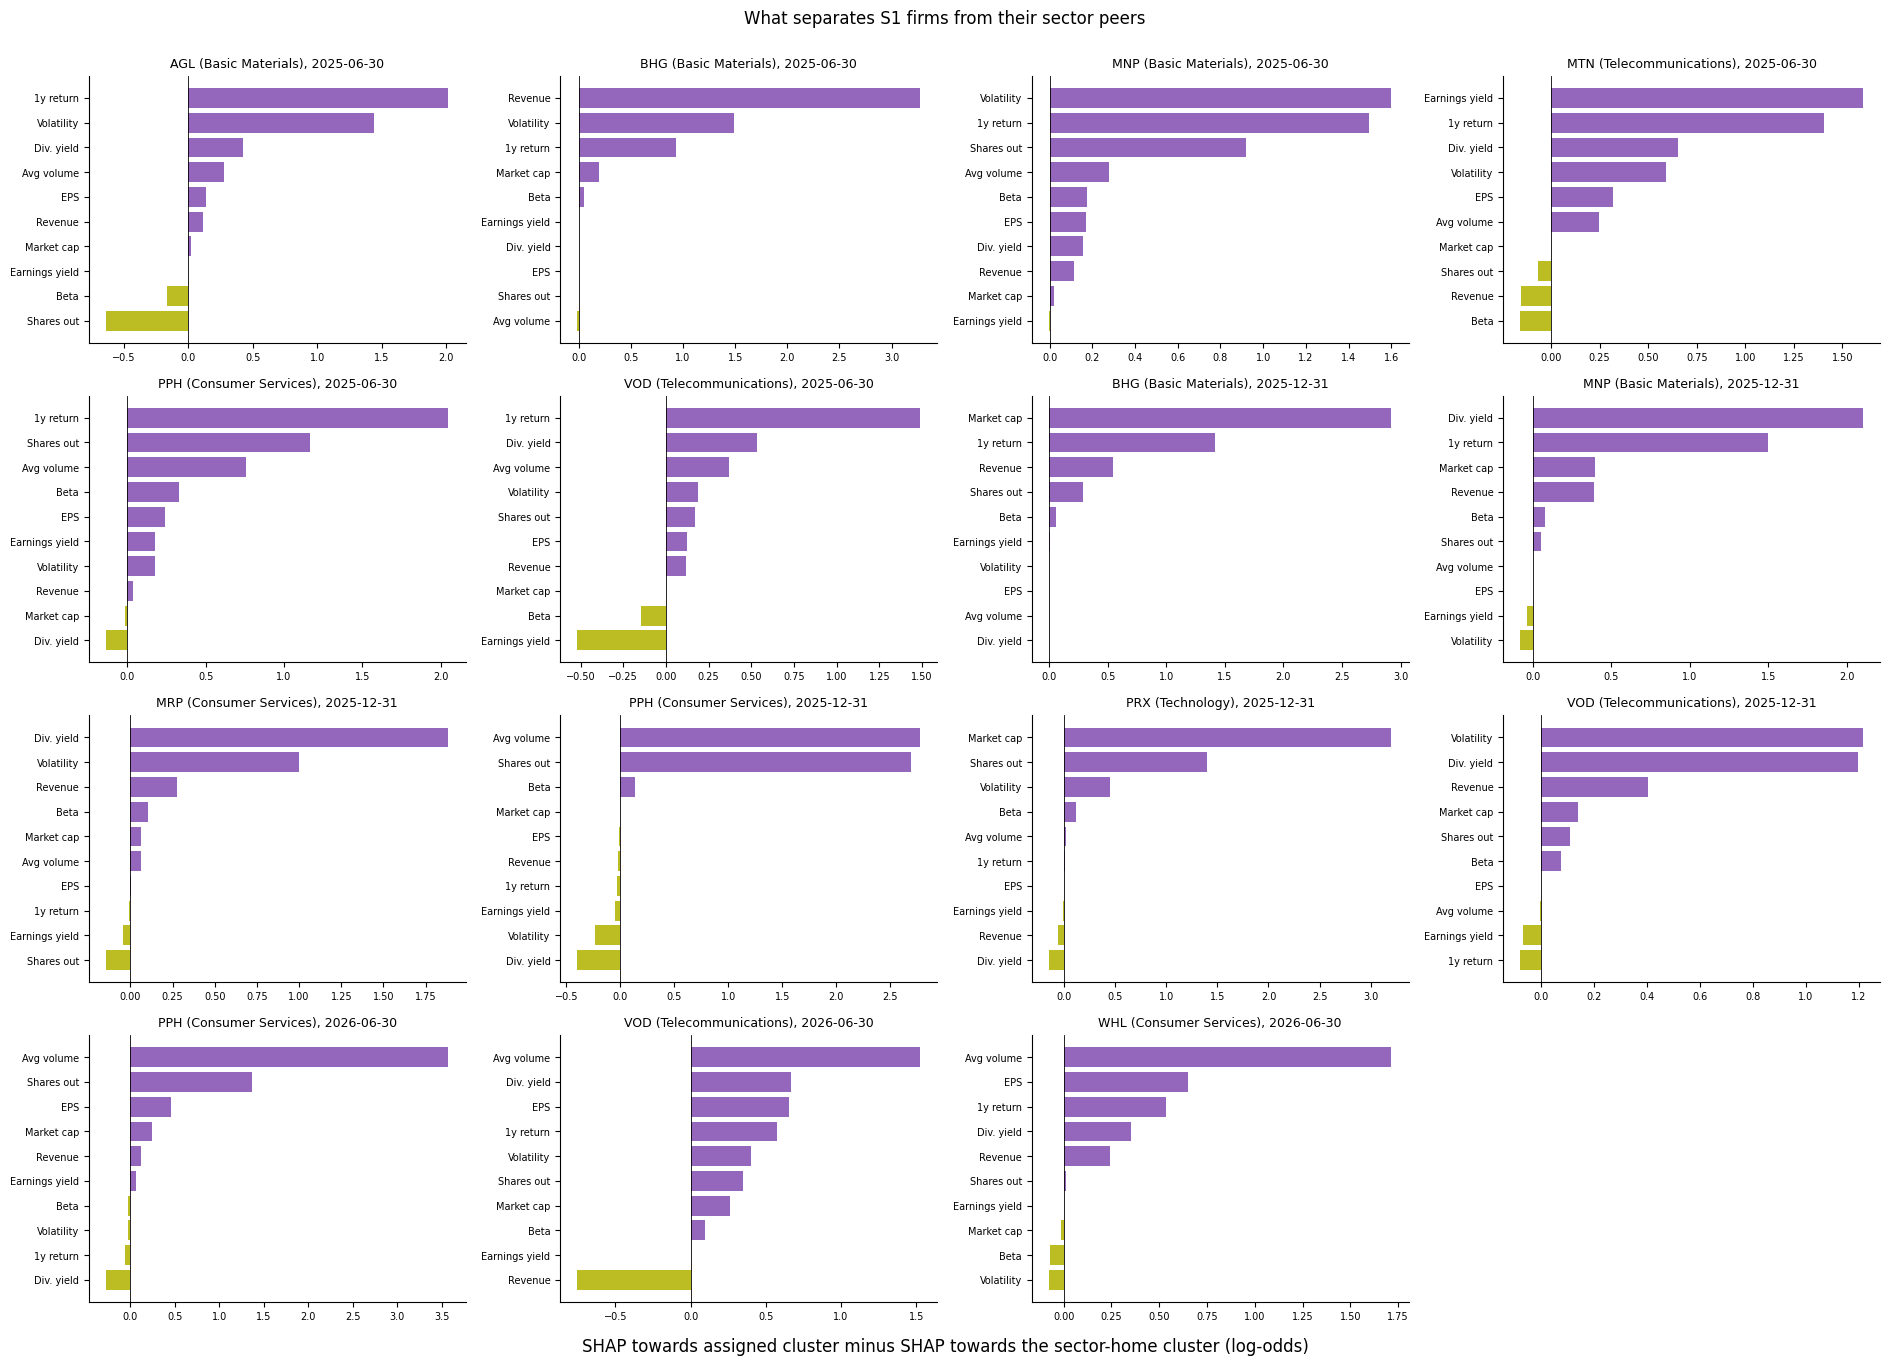

In [60]:
rows, bars = [], []
for d in DATES:
    s = sur[d]; lab = labels_of(MAIN, d); tick = snaps[d].ticker.values
    for t in signals[(signals.model == MAIN) & (signals.date == d) & (signals.S1 == 1)].ticker:
        sector = info.loc[t, 'sector_label']
        sector_peers = [u for u in lab.index if u != t and info.loc[u, 'sector_label'] == sector]
        if not sector_peers:                           # sole member of its sector: no sector-home cluster exists
            rows.append(dict(date=d, ticker=t, sector=sector, sector_home_cluster='none (only firm in its sector)',
                             weak_fidelity=WEAK[d], imputation_sensitive=t in IMPUTED))
            continue
        counts = lab[sector_peers].value_counts()
        home = min(counts.index[counts == counts.max()])
        i = int(np.flatnonzero(tick == t)[0])
        ca, ch = s['y'][i], int(np.flatnonzero(s['classes'] == home)[0])
        diff = pd.Series(s['explanation'].values[i, :, ca] - s['explanation'].values[i, :, ch], index=NAMES)
        top = diff.sort_values(ascending=False).index[:3]
        sector_median = snaps[d][snaps[d].sector_label == sector][FEATURES].median().set_axis(NAMES)
        firm = snaps[d].set_index('ticker').loc[t, FEATURES].set_axis(NAMES)
        rows.append(dict(date=d, ticker=t, sector=sector, assigned_cluster=s['classes'][ca], sector_home_cluster=home,
                         sector_peers_in_home=f'{counts.max()} of {len(sector_peers)}', associated_with_assigned_cluster=', '.join(top),
                         **{f'top{k + 1}: firm vs sector median': f'{f}: {firm[f]:.3g} vs {sector_median[f]:.3g}' for k, f in enumerate(top[:2])},
                         weak_fidelity=WEAK[d], imputation_sensitive=t in IMPUTED))
        bars.append((d, t, diff))
div_shap = table(pd.DataFrame(rows), 'shap_sector_divergence', index=False)
with pd.option_context('display.max_colwidth', 60):
    display(div_shap)
if bars:
    ncol = 4; nrow = int(np.ceil(len(bars) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(19, 3.4 * nrow), squeeze=False)
    for ax, (d, t, diff) in zip(axes.flat, bars):
        v = diff.sort_values()
        ax.barh(v.index, v.values, color=np.where(v.values > 0, 'tab:purple', 'tab:olive'))
        ax.axvline(0, color='black', lw=0.6); ax.set_title(f'{t} ({info.loc[t, "sector_label"]}), {d}', fontsize=9); ax.tick_params(labelsize=7)
    for ax in axes.flat[len(bars):]:
        ax.axis('off')
    fig.supxlabel('SHAP towards assigned cluster minus SHAP towards the sector-home cluster (log-odds)')
    fig.suptitle('What separates S1 firms from their sector peers', y=1.0)
    fig.tight_layout(); save(fig, 'shap_sector_divergence'); plt.show()

## 11. Summary across the three cross-sections, and run record

In [61]:
def model_row(m, d):
    r = holdout[(holdout.model == ('Baseline (SACJ)' if m == 'baseline' else 'Tuned, k = 8 (main)')) & (holdout.date == d)].iloc[0]
    mv = moves[(moves.model == m) & (moves.transition == f'{DATES[0]} → {d}')] if d != DATES[0] else None
    sg = signals[(signals.model == m) & (signals.date == d)]
    return {'Silhouette, 10-feature space': r.silhouette_features, 'Davies–Bouldin, 10-feature space': r.davies_bouldin_features,
            'Seed ARI (mean)': r.seed_ari_mean, 'Singleton clusters (structural observation)': int(r.singletons),
            'Free-k diagnostic (best eligible k)': '—' if m != MAIN or free_k.loc[free_k.date == d, 'best_k_eligible'].isna().iat[0]
                                                   else int(free_k.loc[free_k.date == d, 'best_k_eligible'].iat[0]),
            'Sector ARI / NMI': f"{sector_agree.query('model == @m and date == @d').ari.mean():.2f} / {sector_agree.query('model == @m and date == @d').nmi.mean():.2f}",
            'S1 = 1': int((sg.S1 == 1).sum()), 'S2 = 1 (Beta reference)': int(sg.S2.sum()), 'S3 = 1': int(sg.S3.sum()),
            'Multi-signal': int(sg.multi_signal.sum()),
            'Robust moves since June 2025': '—' if mv is None else int((mv.status == 'robust move').sum()),
            'Stay with matched cluster since June 2025': '—' if mv is None else int((mv.status == 'stays with matched cluster').sum())}

summary_table = table(pd.concat({m: pd.DataFrame({d: model_row(m, d) for d in DATES}) for m in MODELS}), 'summary_across_dates')
summary_table

2025-06-30  \
baseline Silhouette, 10-feature space                    0.166405   
         Davies–Bouldin, 10-feature space                1.177657   
         Seed ARI (mean)                                  0.72743   
         Singleton clusters (structural observation)            0   
         Free-k diagnostic (best eligible k)                    —   
         Sector ARI / NMI                             0.22 / 0.52   
         S1 = 1                                                 4   
         S2 = 1 (Beta reference)                                9   
         S3 = 1                                                 0   
         Multi-signal                                           3   
         Robust moves since June 2025                           —   
         Stay with matched cluster since June 2025              —   
tuned    Silhouette, 10-feature space                    0.241855   
         Davies–Bouldin, 10-feature space                0.966126   
         Seed ARI (mean)                                      1.0   
         Singleton clusters (structural observation)            1   
         Free-k diagnostic (best eligible k)                    7   
         Sector ARI / NMI                             0.26 / 0.56   
         S1 = 1                                                 8   
         S2 = 1 (Beta reference)                                9   
         S3 = 1                                                 1   
         Multi-signal                                           3   
         Robust moves since June 2025                           —   
         Stay with matched cluster since June 2025              —   

                                                       2025-12-31   2026-06-30  
baseline Silhouette, 10-feature space                    0.194242     0.223955  
         Davies–Bouldin, 10-feature space                1.038998     1.113888  
         Seed ARI (mean)                                 0.920174     0.934239  
         Singleton clusters (structural observation)            1            0  
         Free-k diagnostic (best eligible k)                    —            —  
         Sector ARI / NMI                             0.26 / 0.55  0.30 / 0.60  
         S1 = 1                                                 6            4  
         S2 = 1 (Beta reference)                                6            7  
         S3 = 1                                                 0            0  
         Multi-signal                                           0            0  
         Robust moves since June 2025                           3            8  
         Stay with matched cluster since June 2025             24           28  
tuned    Silhouette, 10-feature space                    0.284668     0.253006  
         Davies–Bouldin, 10-feature space                  0.7742     0.742457  
         Seed ARI (mean)                                      1.0          1.0  
         Singleton clusters (structural observation)            2            3  
         Free-k diagnostic (best eligible k)                    —            —  
         Sector ARI / NMI                             0.26 / 0.50  0.20 / 0.48  
         S1 = 1                                                 6            4  
         S2 = 1 (Beta reference)                                6            7  
         S3 = 1                                                 2            3  
         Multi-signal                                           3            3  
         Robust moves since June 2025                           4            3  
         Stay with matched cluster since June 2025             28           29

In [62]:
# Run record: what produced these pilot numbers (protocol Section 11 requires run ID, configuration and data hash).
import hashlib, platform, subprocess, sklearn, scipy, umap, xgboost
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def git(*args):
    try:
        return subprocess.run(['git', *args], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip()
    except Exception:
        return None
manifest = dict(
    run_id=time.strftime('pilot-notebook-%Y%m%dT%H%M%S'), status='PILOT / exploratory (v1 reconstructed data)',
    protocol=PROTOCOL, git_commit=git('rev-parse', 'HEAD'), git_dirty=bool(git('status', '--porcelain')),
    data_file='data/processed/Top40_Retrospective_Model_Inputs_v1.csv', data_sha256=sha256(ROOT / 'data/processed/Top40_Retrospective_Model_Inputs_v1.csv'),
    grid_sha256=sha256(GRID_FILE), all_fits_sha256=sha256(FITS_FILE), perturbation_runs_sha256=sha256(TAB / 'perturbation_runs.csv.gz'),
    selected_method=MODELS[MAIN]['name'], selection_rule=RULE, perturbation=dict(B=B, rng=20251108, robust=ROBUST, min_runs=MIN_RUNS),
    match_threshold=MATCH_J, python=platform.python_version(),
    packages={p.__name__: p.__version__ for p in (np, pd, sklearn, scipy, umap, xgboost, shap)})
(TAB / 'pilot_manifest.json').write_text(json.dumps(manifest, indent=1, default=str))
manifest

{'run_id': 'pilot-notebook-20261108T185611',
 'status': 'PILOT / exploratory (v1 reconstructed data)',
 'protocol': 'protocol-v1.2',
 'git_commit': 'cd645963236eb5c2c08501a8354d99e1612cb9c3',
 'git_dirty': True,
 'data_file': 'data/processed/Top40_Retrospective_Model_Inputs_v1.csv',
 'data_sha256': 'fe6abb616fc826ea973f74bac62902fc77d4309e449ae8af5119df750f061b95',
 'grid_sha256': '0fc9a637499f0b2979fcaff1f144aecd8cdc80abda25cd6256252389a7538f17',
 'all_fits_sha256': '3fe2e67027e9ce8c6537ebb78c110175437005ac995d0fca31c48af2c04121c1',
 'perturbation_runs_sha256': '4cb5a74efc432e6a632a811702280828f32ab924c20a3a1b438ede5af5b78c9e',
 'selected_method': 'Selected: No reduction + hierarchical ward/euclidean, k = 8',
 'selection_rule': {'min_coverage': 0.95,
  'min_seed_ari': 0.8,
  'max_singletons': 1,
  'max_largest_share': 0.5},
 'perturbation': {'B': 100, 'rng': 20251108, 'robust': 0.8, 'min_runs': 20},
 'match_threshold': 0.3,
 'python': '3.11.14',
 'packages': {'numpy': '2.3.5',
  'pand

### Notes for writing the paper
* **Status.** Everything in this notebook is **pilot / exploratory**: v1 reconstructed data, not point-in-time. The v2 point-in-time rebuild will be a
  *protocol-frozen reanalysis of pilot-informed historical cross-sections*, and 31 December 2026 a *prospective follow-up* (protocol Section 11).
* **Claim.** Three decision-date cross-sections, not an enlarged sample and not three market regimes.
* **Optimisation.** Report the search space (4.2), the selection rule (4.5), the rule-sensitivity check, the parameters (4.7), the later-date check (4.6)
  and the free-k diagnostic. Report embedding and feature-space scores together, and say why the feature space is the basis for selection.
* **Robustness.** Firm-level claims rest on perturbation stability proportions (≥ 0.80), not seed agreement.
* **Over time.** Clusters are matched by thresholded Jaccard on continuing firms; report matches, splits, merges, dissolutions and their perturbation support.
  A robust move is a structural change, not an anomaly. Membership changes are reported separately.
* **S2.** Primary: individual-distance Beta reference; say it is a benchmark, not a calibrated 5% rate, and that Σ D² = (n − 1)p makes it a relative screen.
  The SACJ F rule is a descriptive replication only. Report MCD, log-size, without-INP and map versions as sensitivities.
* **Taxonomy.** Report classes per signal, mark borderline and imputation-sensitive cases, and present June 2025 & June 2026 recurrence as less mechanically overlapping evidence.
* **SHAP.** Surrogate explanations, with fidelity and weak-fidelity warnings, the destination reference used, and range flags. Use "associated with".
* **Data caveats.** Shares and sector labels unverified; no per-share basis audit; RNI fundamentals and two AGL volumes imputed; analyst ratings unavailable.